# Information

### What the fields mean

Each JSON line represents one library spectrum. The first line is a **protonated propranolol** record. Some fields are lists because this record combines 81 source scans from a complete MSⁿ fragmentation forest. Because it is an MS² record, it does not contain the four MSⁿ-chain fields that appear on MS³+ records; those are documented separately below.

#### Compound identity and provenance

| Key | Example from the first spectrum | Meaning |
|---|---|---|
| `compound_name` | `propranolol` | Common name of the measured compound. |
| `formula` | `C16H21NO2` | Neutral molecular formula. |
| `exact_mass` | `259.157229` | Exact monoisotopic mass of the neutral molecule. |
| `smiles` | `CC(C)NCC(O)COc1cccc2ccccc12` | Compact text representation of the molecular structure. |
| `inchi` | `InChI=1S/C16H21NO2/...` | Standardized, detailed chemical-structure identifier. |
| `inchikey` | `AQHHHDLHHXJYJD-UHFFFAOYSA-N` | Short, searchable hash derived from the InChI. |
| `adduct` | `[M+H]+` | Ion detected after the molecule gained a proton. |
| `description` | `MCEDRUG` | Short name of the source compound library (the FDA-approved drug collection). |
| `acquisition` | `Commercial` | Provenance category recorded for the compound/library. |
| `dataset_id` | `MSV000094528` | Identifier of the parent MassIVE dataset. |
| `feature_id` | `...G14... msn trees:5` | Internal MZmine feature label tying the entry to its source file and MSⁿ forest. |
| `datacollector` | `Corinna Brungs` | Person who collected the data. |
| `investigator` | `Tomas Pluskal` | Principal investigator recorded for the dataset. |

#### Measurement and processing

| Key | Example from the first spectrum | Meaning |
|---|---|---|
| `softwaresource` | `mzmine3` | Software used to process/export the spectrum. |
| `instrument` | `Orbitrap ID-X` | Specific mass-spectrometer model. |
| `instrument_type` | `Orbitrap` | General analyzer family. |
| `ion_source` | `ESI` | Electrospray ionization was used to form ions. |
| `polarity` | `+` | Positive-ion mode. |
| `charge` | `1` | The precursor ion carries one positive charge. |
| `precursor_mz` | `260.164505` | Mass-to-charge ratio of the ion selected for fragmentation. |
| `ms_level` | `2` | Stored as an MS² spectrum; here it is a pseudo-MS² made from an MSⁿ forest. |
| `fragmenation_method` | `HCD` | Higher-energy collisional dissociation; the key is misspelled in the source data. |
| `collision_energy` | `[20, 15, 60, 40, 30]` | Collision-energy settings represented among the merged scans; the unit is not encoded in this JSON. |
| `isolation_window` | `1.200000...` | Width of the precursor-selection window in m/z units. |
| `rt` | `0.771041...` | Retention time recorded for the feature; its unit is not stated in the JSON. |
| `ims_type` | `none` | No ion-mobility separation was used. |
| `feature_ms1_height` | `148454224` | Height/intensity of the precursor feature in the MS¹ data, in instrument abundance units. |
| `merge_type` | `ALL_MSN_TO_PSEUDO_MS2` | MZmine combined the full MSⁿ forest into one pseudo-MS² spectrum. |
| `scan_number` | 81 scans: `[208, 239, ..., 802]` | Source scan numbers combined into this entry. |
| `usi` | 81 `mzspec:...` identifiers | Universal Spectrum Identifiers that point to those source scans. |

#### Additional fields on MS³ and higher records

These keys are top-level fields in the original JSON, but `Spectrum.from_record()` retains them inside `spectrum.metadata`. This example is propranolol MS⁴ scan 265.

| Key | MS⁴ example | Meaning |
|---|---|---|
| `msn_precursor_mzs` | `[260.163818, 183.080338, 155.085327]` | Ordered precursor-ion path. The last value is the peak selected from the MS³ parent to produce this MS⁴ spectrum. |
| `msn_collision_energies` | `[15, 40, 60]` | Collision energy used at each corresponding fragmentation step. |
| `msn_fragmentation_methods` | `[HCD, HCD, HCD]` | Fragmentation method used at each step. |
| `msn_isolation_windows` | `[1.2, 2.0, 2.2]` | Precursor-isolation-window width used at each step. |

#### Peaks and quality

| Key | Example from the first spectrum | Meaning |
|---|---|---|
| `num_peaks` | `86` | Number of fragment peaks in the final spectrum. |
| `peaks` | first pair: `[41.03848, 2589848.37]` | List of `[fragment m/z, intensity]` pairs. |
| `precursor_purity` | `1.0` | Fraction of signal in the isolation window attributed to the precursor; `1.0` means 100%. |
| `quality_chimeric` | `PASSED` | The spectrum passed the check for substantial co-isolation of other precursor ions. |
| `quality_explained_signals` | `0.82558` | About 82.6% of fragment signals can be assigned a chemically possible subformula. |
| `quality_explained_intensity` | `0.97529` | Those explained signals account for about 97.5% of the total fragment intensity. |

The quality-field interpretations follow the [MZmine spectral-library documentation](https://mzmine.github.io/mzmine_documentation/module_docs/io_spectral_library_export/spectral_library_generation.html); the merge labels are described in the [MSnLib dataset record](https://zenodo.org/records/15683662).

### Interpreting the unique string values

These counts describe distinct **text labels**, not distinct spectra—and not always distinct compounds.

- **Dataset-wide constants:** `Commercial` says the compounds came from a commercial collection; `MCEDRUG` names that collection; `MSV000094528` is its MassIVE dataset ID. `Corinna Brungs` is the data collector and `Tomas Pluskal` the investigator. All entries were processed with `mzmine3`, measured by positive-mode (`+`) electrospray ionization (`ESI`) on an `Orbitrap ID-X`, using `HCD` fragmentation and no ion mobility (`ims_type = none`).
- **Adducts:** `M` means the molecule, while `+H`, `+NH4`, and `+Na` mean an attached proton, ammonium, or sodium ion. `-H2O` and `-2H2O` indicate loss of one or two water molecules. Thus `[M+H]+` is protonated M, `[M+H-H2O]+` is protonated M after one water loss, and `[M]+` is the molecular ion with no added adduct written.
- **Compound identity:** `compound_name` is the human-readable name; `formula` gives elemental composition; `SMILES` and `InChI` encode structure; and `InChIKey` is a searchable hash of the InChI. Their counts differ because isomers can share a formula, names can be aliases, stereochemistry may differ, and some structures may have repeated or missing representations.
- **`feature_id`:** identifies an acquired MZmine feature/MSⁿ forest, not a unique molecule. One feature can produce many records at different MS levels, energies, and merge modes.
- **Merge modes:** `SINGLE_BEST_SCAN` keeps one representative scan; `SAME_ENERGY` merges repeated scans acquired at one energy; `ALL_ENERGIES` merges spectra across collision energies; and `ALL_MSN_TO_PSEUDO_MS2` combines the full MSⁿ forest into one pseudo-MS² spectrum.
- **Chimeric status:** `PASSED` means the precursor-purity check passed. `CHIMERIC` flags likely co-isolation and fragmentation of one or more additional precursor ions, so those peaks should be interpreted more cautiously.

> Backslashes visible in copied output before `_`, `+`, or `@` are Markdown escaping and are not part of the stored values.

# Load Dataset

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from Spectrum_Classes import Spectrum, SpectrumForest, parse_spectrum_forest

In [2]:
data_path_anchor = Path("msnlib/20241003_mcedrug_pos_msn.json")
data_path = Path("msnlib/20241003_enamdisc_pos_msn.json")

In [3]:
def parse_dataset(dataset_path, verbose = False):
    spectra_by_smiles = {}
    spectra = []
    with dataset_path.open(encoding="utf-8") as file:
        for line in file:
            if line.strip():
                spectrum = Spectrum.from_record(json.loads(line))
                if spectrum.metadata["merge_type"] == "SINGLE_BEST_SCAN":
                    spectra_by_smiles.setdefault(spectrum.smiles, []).append(spectrum)
                    spectra.append(spectrum)

    if verbose:
        print(f"{len(spectra_by_smiles):,} unique SMILES")
    
    return spectra, spectra_by_smiles

In [4]:
spectra, spectra_by_smiles = parse_dataset(data_path)

In [5]:
def check_compatability(spectra, data_path_anchor):
    spectra_anchor, _ = parse_dataset(data_path_anchor)
    row_anchor = spectra_anchor[0]
    row = spectra[0]
    anchor_keys = set(row_anchor.metadata.keys())
    keys = set(row.metadata.keys())
    if anchor_keys == keys:
        print("Dataset compatible with anchor")
    else:
        print("ERROR DATASET NOT COMPATIBLE WITH ANCHOR")


In [6]:
check_compatability(spectra, data_path_anchor)

Dataset compatible with anchor


# Statistics

### Shared Imports & Functions

In [7]:
from collections import Counter

In [8]:
def print_summary(values):
    if len(values) == 0:
        print("No values to summarize")
        return

    print(f"Mean: {np.mean(values):.2f}")
    print(f"Median: {np.median(values):.2f}")
    print(f"Q1 (25%): {np.quantile(values, 0.25):.2f}")
    print(f"Q3 (75%): {np.quantile(values, 0.75):.2f}")
    print(f"Minimum: {np.min(values):.2f}")
    print(f"Maximum: {np.max(values):.2f}")

#### Markdown report

Run the notebook from top to bottom in this directory to refresh the report. Each block's final cell stores its text in `report_sections`; rerunning that cell replaces its section. Plot cells save PNGs in `MSnLib_stats_report_files/`. The last cell of Block 7 writes `MSnLib_stats_report.md` with relative image links, so keep that folder beside the report when sharing it.

In [9]:
from datetime import datetime, timezone

report_sections = {}
report_images = {}
report_dir = Path.cwd()
report_path = report_dir / "MSnLib_stats_report.md"
report_image_dir = report_dir / "MSnLib_stats_report_files"
report_image_dir.mkdir(exist_ok=True)

In [10]:
def report_table(columns, rows, decimals=2):
    def format_value(value):
        if value is None:
            return "—"
        if isinstance(value, (int, np.integer)):
            return f"{value:,}"
        if isinstance(value, (float, np.floating)):
            return f"{value:,.{decimals}f}" if np.isfinite(value) else "—"
        return str(value).replace("|", r"\|").replace("\n", " ")

    lines = ["| " + " | ".join(columns) + " |", "| " + " | ".join(["---"] * len(columns)) + " |"]
    for row in rows:
        lines.append("| " + " | ".join(format_value(value) for value in row) + " |")
    return "\n".join(lines)

In [11]:
def report_summary(groups, decimals=2):
    rows = []
    for label, values in groups.items():
        values = np.asarray(values, dtype=float)
        valid = values[np.isfinite(values)]
        stats = [None] * 6
        if len(valid):
            stats = [valid.mean(), *np.quantile(valid, [0.5, 0.25, 0.75, 0, 1])]
        rows.append([label, len(valid), len(values) - len(valid), *stats])
    columns = ["Metric", "N", "Missing/nonfinite", "Mean", "Median", "Q1", "Q3", "Min", "Max"]
    return report_table(columns, rows, decimals)


def report_percent(count, total):
    return 100 * count / total if total else np.nan

In [12]:
def save_report_plot(name, caption):
    image_path = report_image_dir / f"{name}.png"
    plt.gcf().savefig(image_path, dpi=180, bbox_inches="tight")
    relative_path = image_path.relative_to(report_dir).as_posix()
    report_images[name] = f"![{caption}]({relative_path})"

### Spectrum Inventory

In [13]:
total_spectra = len(spectra)
print(f"Total spectra: {total_spectra}")

print()


ms_level_count = Counter()
for spectrum in spectra:
    ms_level_count[spectrum.ms_level] += 1

print(f"Spectra count by MS level:")

for ms_level in ms_level_count:
    print(f"MS level {ms_level}: {ms_level_count[ms_level]} Spectra")

print()

for ms_level in ms_level_count:
    percentage = ms_level_count[ms_level] / total_spectra
    print(f"Percentage of Spectra with MS level {ms_level}: {percentage * 100:.2f}%")



Total spectra: 346248

Spectra count by MS level:
MS level 2: 31463 Spectra
MS level 3: 152514 Spectra
MS level 4: 153508 Spectra
MS level 5: 8763 Spectra

Percentage of Spectra with MS level 2: 9.09%
Percentage of Spectra with MS level 3: 44.05%
Percentage of Spectra with MS level 4: 44.33%
Percentage of Spectra with MS level 5: 2.53%


In [14]:
report_sections[1] = "\n\n".join([
    "## Block 1 — Spectrum inventory",
    f"**Total spectra: {total_spectra:,}.** Percentages use all loaded spectra.",
    report_table(["MS level", "Spectra", "% of all spectra"], [
        [f"MS{level}", count, report_percent(count, total_spectra)]
        for level, count in sorted(ms_level_count.items())
    ]),
])

### Molecules and adducts

These statistics use the `SINGLE_BEST_SCAN` spectra loaded above. Molecules are grouped by InChIKey, falling back to SMILES. Spectra missing both identifiers are excluded from molecule counts.

In [15]:
molecule_count = Counter()
molecule_counts_by_ms_level = {ms_level: Counter() for ms_level in sorted(ms_level_count)}
missing_molecule_ids = 0

for spectrum in spectra:
    molecule_id = (spectrum.metadata.get("inchikey") or "").strip()
    molecule_id = molecule_id or (spectrum.smiles or "").strip()
    if molecule_id:
        molecule_count[molecule_id] += 1
        molecule_counts_by_ms_level[spectrum.ms_level][molecule_id] += 1
    else:
        missing_molecule_ids += 1

print(f"Unique molecules: {len(molecule_count):,}")
print(f"Spectra missing a molecule identifier: {missing_molecule_ids:,}")

Unique molecules: 9,544
Spectra missing a molecule identifier: 0


In [16]:
spectra_per_molecule = np.array(list(molecule_count.values()))

print("Spectra per molecule:")
print_summary(spectra_per_molecule)

Spectra per molecule:
Mean: 36.28
Median: 35.00
Q1 (25%): 28.00
Q3 (75%): 43.00
Minimum: 1.00
Maximum: 175.00


#### Average spectra per molecule by MS level

Each mean uses all unique molecules as the denominator, including molecules with zero spectra at that MS level. Spectra missing both InChIKey and SMILES are excluded.


In [17]:
print(f"Mean spectra per molecule ({len(molecule_count):,} unique molecules):")

for ms_level, counts in molecule_counts_by_ms_level.items():
    mean_count = sum(counts.values()) / len(molecule_count) if molecule_count else np.nan
    print(f"MS{ms_level}: {mean_count:.2f} spectra per molecule")


Mean spectra per molecule (9,544 unique molecules):
MS2: 3.30 spectra per molecule
MS3: 15.98 spectra per molecule
MS4: 16.08 spectra per molecule
MS5: 0.92 spectra per molecule


#### Adducts

Blank or missing adducts are excluded from unique-adduct counts and frequency tables. Percentages use all spectra overall, or all spectra within the stated MS level.

In [18]:
adduct_count = Counter()
adducts_by_ms_level = {ms_level: Counter() for ms_level in sorted(ms_level_count)}

for spectrum in spectra:
    adduct = (spectrum.metadata.get("adduct") or "").strip()
    if adduct:
        adduct_count[adduct] += 1
        adducts_by_ms_level[spectrum.ms_level][adduct] += 1

spectra_with_adduct = sum(adduct_count.values())
adduct_presence = spectra_with_adduct / total_spectra if total_spectra else np.nan

print(f"Unique adducts: {len(adduct_count)}")
for adduct in adduct_count.keys():
    print(adduct)
print(f"Adduct presence: {adduct_presence:.2%} ---> {spectra_with_adduct:,} out of {total_spectra:,}")

Unique adducts: 7
[M+H]+
[M+NH4]+
[M+Na]+
[M+H-H2O]+
[M-H2O]+
[M]+
[M+H-2H2O]+
Adduct presence: 100.00% ---> 346,248 out of 346,248


In [19]:
print(f"{'Adduct':<20} {'Spectra':>10} {'% of all':>10}")
for adduct, count in adduct_count.most_common():
    percentage = 100 * count / total_spectra
    print(f"{adduct:<20} {count:>10,} {percentage:>9.2f}%")

Adduct                  Spectra   % of all
[M+H]+                  334,625     96.64%
[M+H-H2O]+                5,800      1.68%
[M+Na]+                   1,868      0.54%
[M+NH4]+                  1,604      0.46%
[M]+                      1,159      0.33%
[M-H2O]+                    769      0.22%
[M+H-2H2O]+                 423      0.12%


In [20]:
for ms_level, counts in adducts_by_ms_level.items():
    level_total = ms_level_count[ms_level]
    presence = sum(counts.values()) / level_total
    print(f"\nMS{ms_level} — Adduct presence: {presence:.2%}")
    print(f"{'Adduct':<20} {'Spectra':>10} {'% of level':>10}")
    for adduct, count in counts.most_common():
        percentage = 100 * count / level_total
        print(f"{adduct:<20} {count:>10,} {percentage:>9.2f}%")


MS2 — Adduct presence: 100.00%
Adduct                  Spectra % of level
[M+H]+                   29,690     94.36%
[M+H-H2O]+                  809      2.57%
[M+Na]+                     528      1.68%
[M+NH4]+                    188      0.60%
[M]+                        133      0.42%
[M-H2O]+                     71      0.23%
[M+H-2H2O]+                  44      0.14%

MS3 — Adduct presence: 100.00%
Adduct                  Spectra % of level
[M+H]+                  146,719     96.20%
[M+H-H2O]+                3,106      2.04%
[M+Na]+                     924      0.61%
[M+NH4]+                    726      0.48%
[M]+                        507      0.33%
[M-H2O]+                    336      0.22%
[M+H-2H2O]+                 196      0.13%

MS4 — Adduct presence: 100.00%
Adduct                  Spectra % of level
[M+H]+                  149,613     97.46%
[M+H-H2O]+                1,826      1.19%
[M+NH4]+                    658      0.43%
[M]+                        499      0.33%
[

In [21]:
report_sections[2] = "\n\n".join([
    "## Block 2 — Molecules and adducts",
    "Molecules use InChIKey, falling back to SMILES. Missing identifiers are excluded. "
    "MS-level averages use all unique molecules, including zeros at that level.",
    report_table(["Metric", "Value"], [
        ["Unique molecules", len(molecule_count)],
        ["Spectra missing a molecule identifier", missing_molecule_ids],
        ["Unique adducts", len(adduct_count)],
        ["Spectra with an adduct", spectra_with_adduct],
        ["Adduct presence (%)", 100 * adduct_presence],
    ]),
    report_summary({"Spectra per molecule": spectra_per_molecule}),
    report_table(["MS level", "Identified spectra", "Mean spectra per molecule"], [
        [f"MS{level}", sum(counts.values()), sum(counts.values()) / len(molecule_count) if molecule_count else np.nan]
        for level, counts in molecule_counts_by_ms_level.items()
    ]),
    "### Adduct frequencies",
    "Blank/missing adducts are excluded from frequency tables. Percentages use all spectra overall or within the stated MS level.",
    report_table(["Adduct", "Spectra", "% of all spectra"], [
        [adduct, count, report_percent(count, total_spectra)] for adduct, count in adduct_count.most_common()
    ]),
    report_table(["MS level", "Spectra with adduct", "Total spectra", "Adduct presence (%)"], [
        [f"MS{level}", sum(counts.values()), ms_level_count[level], report_percent(sum(counts.values()), ms_level_count[level])]
        for level, counts in adducts_by_ms_level.items()
    ]),
    report_table(["MS level", "Adduct", "Spectra", "% of level"], [
        [f"MS{level}", adduct, count, report_percent(count, ms_level_count[level])]
        for level, counts in adducts_by_ms_level.items() for adduct, count in counts.most_common()
    ]),
])

#### Peak statistics

Peak counts use `len(spectrum.peaks)`, including zero for empty spectra.

In [22]:
peak_counts = np.array([len(spectrum.peaks) for spectrum in spectra])
ms_levels = np.array([spectrum.ms_level for spectrum in spectra])

print("Peaks per spectrum:")
print_summary(peak_counts)
print(f"Empty spectra: {np.count_nonzero(peak_counts == 0):,}")

Peaks per spectrum:
Mean: 15.26
Median: 9.00
Q1 (25%): 4.00
Q3 (75%): 20.00
Minimum: 2.00
Maximum: 271.00
Empty spectra: 0


In [23]:
for ms_level in sorted(ms_level_count):
    counts = peak_counts[ms_levels == ms_level]
    print(f"\nMS{ms_level} — Peaks per spectrum:")
    print_summary(counts)
    print(f"Empty spectra: {np.count_nonzero(counts == 0):,}")


MS2 — Peaks per spectrum:
Mean: 27.70
Median: 21.00
Q1 (25%): 13.00
Q3 (75%): 36.00
Minimum: 2.00
Maximum: 271.00
Empty spectra: 0

MS3 — Peaks per spectrum:
Mean: 18.68
Median: 13.00
Q1 (25%): 6.00
Q3 (75%): 24.00
Minimum: 2.00
Maximum: 246.00
Empty spectra: 0

MS4 — Peaks per spectrum:
Mean: 9.55
Median: 6.00
Q1 (25%): 3.00
Q3 (75%): 12.00
Minimum: 2.00
Maximum: 182.00
Empty spectra: 0

MS5 — Peaks per spectrum:
Mean: 10.90
Median: 7.00
Q1 (25%): 4.00
Q3 (75%): 13.00
Minimum: 2.00
Maximum: 126.00
Empty spectra: 0


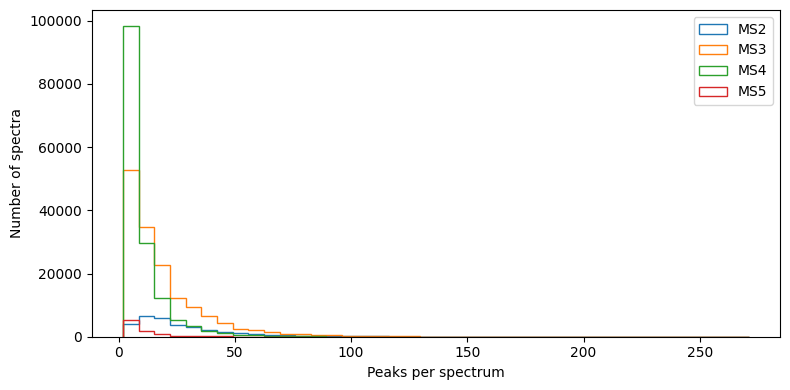

In [24]:
# Shared bins make the MS levels comparable.
bins = np.histogram_bin_edges(peak_counts, bins=40)
plt.figure(figsize=(8, 4))

for ms_level in sorted(ms_level_count):
    counts = peak_counts[ms_levels == ms_level]
    plt.hist(counts, bins=bins, histtype="step", label=f"MS{ms_level}")

plt.xlabel("Peaks per spectrum")
plt.ylabel("Number of spectra")
plt.legend()
plt.tight_layout()
save_report_plot("peak_counts_by_ms_level", "Peak-count histogram by MS level")
plt.show()

#### Peak m/z and relative intensity distributions

Each peak contributes once to these pooled distributions. Intensities are normalized separately within each spectrum so its maximum is 100. Empty spectra contribute no peaks; all-zero spectra retain zero intensities.

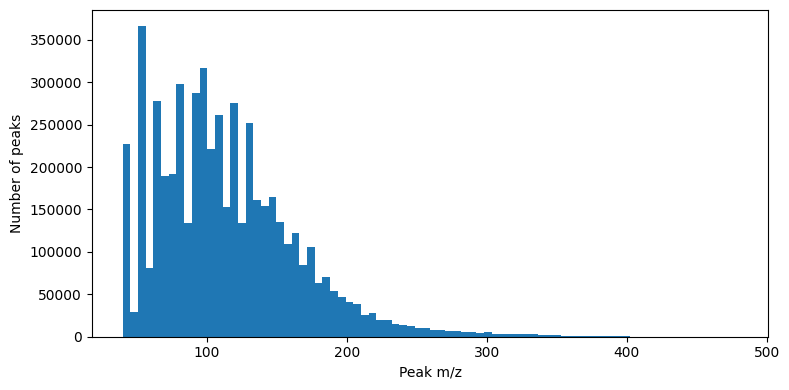

In [25]:
all_mz = np.concatenate([spectrum.mz for spectrum in spectra]) if spectra else np.array([])

plt.figure(figsize=(8, 4))
plt.hist(all_mz, bins=80)
plt.xlabel("Peak m/z")
plt.ylabel("Number of peaks")
plt.tight_layout()
save_report_plot("peak_mz_distribution", "Pooled peak m/z distribution")
plt.show()

In [26]:
normalized_intensities = []

for spectrum in spectra:
    if len(spectrum.peaks) == 0:
        continue
    intensities = spectrum.intensity.copy()
    if intensities.max() > 0:
        intensities = 100 * intensities / intensities.max()
    normalized_intensities.append(intensities)

relative_intensities = (
    np.concatenate(normalized_intensities) if normalized_intensities else np.array([])
)

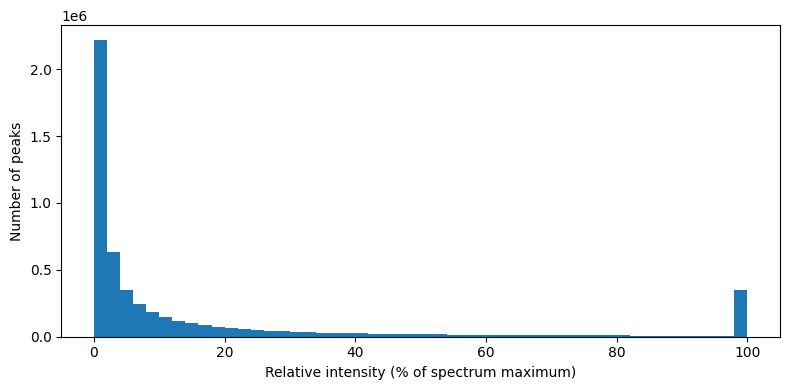

In [27]:
plt.figure(figsize=(8, 4))
plt.hist(relative_intensities, bins=50, range=(0, 100))
plt.xlabel("Relative intensity (% of spectrum maximum)")
plt.ylabel("Number of peaks")
plt.tight_layout()
save_report_plot("relative_intensity_distribution", "Pooled normalized relative-intensity distribution")
plt.show()

In [28]:
peak_groups = {"All spectra": peak_counts}
peak_groups.update({f"MS{level}": peak_counts[ms_levels == level] for level in sorted(ms_level_count)})

report_sections[3] = "\n\n".join([
    "## Block 3 — Peak statistics",
    "Peak counts use `len(spectrum.peaks)` and include empty spectra as zero.",
    report_summary(peak_groups),
    report_table(["Group", "Empty spectra"], [
        [label, np.count_nonzero(counts == 0)] for label, counts in peak_groups.items()
    ]),
    report_images["peak_counts_by_ms_level"],
    "### Pooled peak distributions",
    "Each peak contributes once. Relative intensities are normalized separately within each spectrum "
    "to a maximum of 100; all-zero spectra remain zero, and empty spectra contribute no peaks.",
    report_summary({"Peak m/z": all_mz, "Relative intensity (%)": relative_intensities}),
    report_images["peak_mz_distribution"],
    report_images["relative_intensity_distribution"],
])

### Block 4 — Fragmentation-forest statistics

Group the loaded spectra by `feature_id`, then parse each feature separately at `0.01 Da`. Missing feature IDs are excluded and reported. A feature may contain multiple MS² roots.

In [29]:
spectra_by_feature = {}
missing_feature_ids = 0

for spectrum in spectra:
    feature_id = (spectrum.metadata.get("feature_id") or "").strip()
    if feature_id:
        spectra_by_feature.setdefault(feature_id, []).append(spectrum)
    else:
        missing_feature_ids += 1

print(f"Unique feature forests: {len(spectra_by_feature):,}")
print(f"Spectra missing feature_id: {missing_feature_ids:,}")

Unique feature forests: 10,181
Spectra missing feature_id: 0


In [30]:
mz_tolerance = 0.01

forests = {}
for feature_id, group in spectra_by_feature.items():
    forests[feature_id] = parse_spectrum_forest(group, mz_tol=mz_tolerance)

print(f"Parsed spectra: {sum(len(forest.nodes) for forest in forests.values()):,}")

Parsed spectra: 343,300


In [31]:
forest_level_counts = {
    feature_id: Counter(spectrum.ms_level for spectrum in forest.nodes.values())
    for feature_id, forest in forests.items()
}

forest_statistics = {
    "Spectra per forest": [len(forest.nodes) for forest in forests.values()],
    "MS2 roots per forest": [len(forest.roots) for forest in forests.values()],
    "Maximum recorded MS level per forest": [max(counts) for counts in forest_level_counts.values()],
}

for label, values in forest_statistics.items():
    print(f"\n{label}:")
    print_summary(values)


Spectra per forest:
Mean: 33.72
Median: 34.00
Q1 (25%): 27.00
Q3 (75%): 42.00
Minimum: 1.00
Maximum: 78.00

MS2 roots per forest:
Mean: 3.07
Median: 3.00
Q1 (25%): 3.00
Q3 (75%): 3.00
Minimum: 1.00
Maximum: 5.00

Maximum recorded MS level per forest:
Mean: 4.15
Median: 4.00
Q1 (25%): 4.00
Q3 (75%): 4.00
Minimum: 2.00
Maximum: 5.00


In [32]:
for ms_level in sorted(ms_level_count):
    if ms_level >= 3:
        counts = [levels[ms_level] for levels in forest_level_counts.values()]
        print(f"\nMS{ms_level} spectra per forest (including zeros):")
        print_summary(counts)


MS3 spectra per forest (including zeros):
Mean: 14.86
Median: 15.00
Q1 (25%): 14.00
Q3 (75%): 17.00
Minimum: 0.00
Maximum: 34.00

MS4 spectra per forest (including zeros):
Mean: 14.94
Median: 15.00
Q1 (25%): 9.00
Q3 (75%): 21.00
Minimum: 0.00
Maximum: 48.00

MS5 spectra per forest (including zeros):
Mean: 0.85
Median: 0.00
Q1 (25%): 0.00
Q3 (75%): 0.00
Minimum: 0.00
Maximum: 20.00


#### Resolved forest depth

Depth counts resolved edges from an MS² root: MS² alone has depth 0, MS²→MS³ has depth 1. Paths disconnected from MS² do not contribute. Features with no MS² root have undefined depth.

In [33]:
def depth_from_ms2(forest, node_id):
    depth = 0
    while node_id in forest.parent_of:
        node_id = forest.parent_of[node_id]
        depth += 1
    if forest.nodes[node_id].ms_level == 2:
        return depth
    return None

In [34]:
resolved_forest_depths = {}
for feature_id, forest in forests.items():
    depths = [depth_from_ms2(forest, node_id) for node_id in forest.nodes]
    depths = [depth for depth in depths if depth is not None]
    resolved_forest_depths[feature_id] = max(depths) if depths else np.nan

values = np.array(list(resolved_forest_depths.values()))
print("Maximum resolved depth per forest (edges from MS2):")
print_summary(values[np.isfinite(values)])
print(f"Forests without an MS2 root: {np.count_nonzero(np.isnan(values)):,}")

Maximum resolved depth per forest (edges from MS2):
Mean: 2.06
Median: 2.00
Q1 (25%): 2.00
Q3 (75%): 2.00
Minimum: 0.00
Maximum: 3.00
Forests without an MS2 root: 0


#### Orphans and branching

An orphan is an MS³+ spectrum for which the parser found no immediate parent. A spectrum can have a parent yet still lack a complete path to MS². Orphan rates below show both all parsed spectra and eligible MS³+ spectra as denominators.

Branching counts resolved children of spectra with at least one child; leaves are excluded.

In [35]:
orphan_counts = Counter(
    forest.nodes[node_id].ms_level for forest in forests.values() for node_id in forest.orphans
)
parsed_level_counts = Counter()
for counts in forest_level_counts.values():
    parsed_level_counts.update(counts)

orphan_total = sum(orphan_counts.values())
parsed_total = sum(parsed_level_counts.values())
ms3plus_total = sum(count for level, count in parsed_level_counts.items() if level >= 3)
print(f"Unresolved/orphan spectra: {orphan_total:,}")
for label, denominator in [("all parsed spectra", parsed_total), ("MS3+ spectra", ms3plus_total)]:
    percentage = 100 * orphan_total / denominator if denominator else np.nan
    print(f"Orphans / {label}: {percentage:.2f}%")

Unresolved/orphan spectra: 18,656
Orphans / all parsed spectra: 5.43%
Orphans / MS3+ spectra: 5.98%


In [36]:
print("Orphan spectra per forest:")
print_summary([len(forest.orphans) for forest in forests.values()])

for ms_level in sorted(parsed_level_counts):
    if ms_level >= 3:
        count = orphan_counts[ms_level]
        percentage = 100 * count / parsed_level_counts[ms_level]
        print(f"MS{ms_level} orphans: {count:,} ({percentage:.2f}% of MS{ms_level})")

Orphan spectra per forest:
Mean: 1.83
Median: 0.00
Q1 (25%): 0.00
Q3 (75%): 0.00
Minimum: 0.00
Maximum: 31.00
MS3 orphans: 10,657 (7.05% of MS3)
MS4 orphans: 7,853 (5.16% of MS4)
MS5 orphans: 146 (1.68% of MS5)


In [37]:
children_per_parent = []
children_by_parent_level = {}

for forest in forests.values():
    for parent_id, count in Counter(forest.parent_of.values()).items():
        children_per_parent.append(count)
        ms_level = forest.nodes[parent_id].ms_level
        children_by_parent_level.setdefault(ms_level, []).append(count)

print("Children per parent spectrum (parents with at least one child):")
print_summary(children_per_parent)
for ms_level, counts in sorted(children_by_parent_level.items()):
    print(f"\nChildren per MS{ms_level} parent:")
    print_summary(counts)

Children per parent spectrum (parents with at least one child):
Mean: 6.13
Median: 6.00
Q1 (25%): 3.00
Q3 (75%): 6.00
Minimum: 1.00
Maximum: 27.00

Children per MS2 parent:
Mean: 12.96
Median: 15.00
Q1 (25%): 11.00
Q3 (75%): 15.00
Minimum: 1.00
Maximum: 27.00

Children per MS3 parent:
Mean: 4.46
Median: 5.00
Q1 (25%): 3.00
Q3 (75%): 6.00
Minimum: 1.00
Maximum: 12.00

Children per MS4 parent:
Mean: 1.82
Median: 2.00
Q1 (25%): 2.00
Q3 (75%): 2.00
Minimum: 1.00
Maximum: 4.00


In [38]:
forest_report_groups = dict(forest_statistics)
forest_report_groups.update({
    f"MS{level} spectra per forest": [counts[level] for counts in forest_level_counts.values()]
    for level in sorted(ms_level_count) if level >= 3
})
forest_report_groups["Maximum resolved depth (edges)"] = list(resolved_forest_depths.values())
forest_report_groups["Orphan spectra per forest"] = [len(forest.orphans) for forest in forests.values()]
orphan_rows = [["All parsed spectra", orphan_total, parsed_total, report_percent(orphan_total, parsed_total)],
               ["MS3+ spectra", orphan_total, ms3plus_total, report_percent(orphan_total, ms3plus_total)]]
orphan_rows += [[f"MS{level}", orphan_counts[level], count, report_percent(orphan_counts[level], count)]
                for level, count in sorted(parsed_level_counts.items()) if level >= 3]

report_sections[4] = "\n\n".join([
    "## Block 4 — Fragmentation-forest statistics",
    f"Each `feature_id` is parsed separately with `mz_tolerance = {mz_tolerance:g} Da`. "
    "One feature can contain multiple MS2 roots; missing feature IDs are excluded.",
    report_table(["Metric", "Value"], [
        ["Unique feature forests", len(spectra_by_feature)],
        ["Spectra missing feature_id", missing_feature_ids],
        ["Parsed spectra", parsed_total],
        ["Forests without an MS2 root", sum(not np.isfinite(depth) for depth in resolved_forest_depths.values())],
    ]),
    "Per-forest MS-level counts include zeros. Resolved depth counts edges from MS2 (MS2 alone = 0); "
    "paths disconnected from MS2 are excluded. Features without MS2 have undefined depth.",
    report_summary(forest_report_groups),
    "### Unresolved/orphan spectra",
    "An orphan has no resolved immediate parent. Having a parent does not guarantee a complete path to MS2.",
    report_table(["Denominator group", "Orphans", "Spectra", "Orphans (%)"], orphan_rows),
    "### Branching factor",
    "Children per parent with at least one resolved child; leaves are excluded.",
    report_summary({"All active parents": children_per_parent,
                    **{f"MS{level} parents": counts for level, counts in sorted(children_by_parent_level.items())}}),
])

### Block 5 — MS²→MS³ coverage

Use the parsed parent of each MS³ spectrum and match its last `msn_precursor_mzs` value to the nearest MS² peak within `mz_tolerance`. A peak is identified by its parent spectrum and peak index, so multiple MS³ children count only once toward coverage.

Global and per-spectrum coverage denominators include **all loaded MS² spectra**, including those without children or a feature ID. Empty MS² spectra have undefined per-spectrum coverage and are reported separately. Global coverage is weighted by peak count; the per-spectrum mean gives each nonempty MS² spectrum equal weight.

Also report peak coverage among MS² spectra with at least one resolved MS³ child: unique linked MS² peaks divided by all peaks in those MS² spectra. This is a pooled peak ratio within that subset.


In [39]:
def spectrum_key(spectrum):
    feature_id = (spectrum.metadata.get("feature_id") or "").strip()
    return feature_id, spectrum.metadata["usi"][0]


forest_spectra = {
    (feature_id, node_id): spectrum
    for feature_id, forest in forests.items()
    for node_id, spectrum in forest.nodes.items()
}

In [40]:
ms3_parent_pairs = []

for feature_id, forest in forests.items():
    for child_id, child in forest.nodes.items():
        if child.ms_level != 3:
            continue
        parent_id = forest.parent_of.get(child_id)
        if parent_id is not None and forest.nodes[parent_id].ms_level == 2:
            ms3_parent_pairs.append(((feature_id, parent_id), (feature_id, child_id)))

In [41]:
ms3_links = {}

for parent_key, child_key in ms3_parent_pairs:
    parent, child = forest_spectra[parent_key], forest_spectra[child_key]
    if len(parent.peaks) == 0:
        continue
    isolated_mz = child.metadata["msn_precursor_mzs"][-1]
    peak_index = int(np.argmin(np.abs(parent.mz - isolated_mz)))
    mass_error = float(parent.mz[peak_index] - isolated_mz)
    if abs(mass_error) <= mz_tolerance:
        ms3_links[child_key] = {
            "parent": parent_key,
            "peak_index": peak_index,
            "mass_error_da": mass_error,
        }

print(f"MS3 spectra matched to an MS2 peak: {len(ms3_links):,}")

MS3 spectra matched to an MS2 peak: 140,613


In [42]:
linked_peak_children = Counter(
    (link["parent"], link["peak_index"]) for link in ms3_links.values()
)
linked_peaks_per_ms2 = Counter(parent_key for parent_key, peak_index in linked_peak_children)
ms2_spectra = [spectrum for spectrum in spectra if spectrum.ms_level == 2]

print(f"Unique linked MS2 peaks: {len(linked_peak_children):,}")
print("MS3 children per linked MS2 peak:")
print_summary(list(linked_peak_children.values()))

Unique linked MS2 peaks: 48,576
MS3 children per linked MS2 peak:
Mean: 2.89
Median: 3.00
Q1 (25%): 3.00
Q3 (75%): 3.00
Minimum: 1.00
Maximum: 6.00


In [43]:
ms2_with_children = sum(linked_peaks_per_ms2[spectrum_key(spectrum)] > 0 for spectrum in ms2_spectra)
ms2_child_percentage = 100 * ms2_with_children / len(ms2_spectra) if ms2_spectra else np.nan
all_ms2_peak_count = sum(len(spectrum.peaks) for spectrum in ms2_spectra)
global_peak_coverage = len(linked_peak_children) / all_ms2_peak_count if all_ms2_peak_count else np.nan

print(f"MS2 spectra with an MS3 child: {ms2_with_children:,} / {len(ms2_spectra):,} ({ms2_child_percentage:.2f}%)")
print(f"Global peak coverage: {len(linked_peak_children):,} / {all_ms2_peak_count:,} ({global_peak_coverage:.2%})")

MS2 spectra with an MS3 child: 10,933 / 31,463 (34.75%)
Global peak coverage: 48,576 / 871,577 (5.57%)


In [44]:
peaks_in_ms2_with_children = sum(
    len(spectrum.peaks) for spectrum in ms2_spectra
    if linked_peaks_per_ms2[spectrum_key(spectrum)] > 0
)
peak_coverage_with_children = (
    len(linked_peak_children) / peaks_in_ms2_with_children
    if peaks_in_ms2_with_children else np.nan
)

print("Peak coverage among MS2 spectra with MS3 children:")
print(f"{len(linked_peak_children):,} / {peaks_in_ms2_with_children:,} ({peak_coverage_with_children:.2%})")


Peak coverage among MS2 spectra with MS3 children:
48,576 / 277,351 (17.51%)


In [45]:
ms2_peak_coverage = np.array([
    linked_peaks_per_ms2[spectrum_key(spectrum)] / len(spectrum.peaks)
    if len(spectrum.peaks) else np.nan
    for spectrum in ms2_spectra
])

print("Per-spectrum MS2 peak coverage (%):")
print_summary(100 * ms2_peak_coverage[np.isfinite(ms2_peak_coverage)])
print(f"Empty MS2 spectra (undefined coverage): {np.count_nonzero(np.isnan(ms2_peak_coverage)):,}")

Per-spectrum MS2 peak coverage (%):
Mean: 8.51
Median: 0.00
Q1 (25%): 0.00
Q3 (75%): 15.62
Minimum: 0.00
Maximum: 100.00
Empty MS2 spectra (undefined coverage): 0


#### Linked peak intensity and link mass errors

Intensity statistics count each linked MS² peak once. Rank 1 is the most intense peak; ties share a rank. Relative intensity uses the maximum of that MS² spectrum. Mass errors count every MS³ link and are signed: matched MS² peak m/z minus isolated fragment m/z.

In [46]:
linked_peak_ranks = []
linked_peak_relative_intensities = []

for parent_key, peak_index in linked_peak_children:
    intensities = forest_spectra[parent_key].intensity
    intensity = intensities[peak_index]
    rank = 1 + np.count_nonzero(intensities > intensity)
    relative = 100 * intensity / intensities.max() if intensities.max() > 0 else np.nan
    linked_peak_ranks.append(rank)
    linked_peak_relative_intensities.append(relative)

linked_peak_ranks = np.array(linked_peak_ranks)
linked_peak_relative_intensities = np.array(linked_peak_relative_intensities)

In [47]:
print("Linked MS2 peak intensity rank:")
print_summary(linked_peak_ranks)

values = linked_peak_relative_intensities
print("\nLinked MS2 peak relative intensity (%):")
print_summary(values[np.isfinite(values)])
print(f"Undefined relative intensities: {np.count_nonzero(~np.isfinite(values)):,}")

mass_errors_da = np.array([link["mass_error_da"] for link in ms3_links.values()])
print("\nParent-link mass error (mDa; 1 mDa = 0.001 Da):")
print_summary(1000 * mass_errors_da)

Linked MS2 peak intensity rank:
Mean: 4.34
Median: 4.00
Q1 (25%): 2.00
Q3 (75%): 5.00
Minimum: 1.00
Maximum: 101.00

Linked MS2 peak relative intensity (%):
Mean: 34.65
Median: 16.20
Q1 (25%): 3.72
Q3 (75%): 63.13
Minimum: 0.04
Maximum: 100.00
Undefined relative intensities: 0

Parent-link mass error (mDa; 1 mDa = 0.001 Da):
Mean: 0.00
Median: -0.00
Q1 (25%): -0.00
Q3 (75%): -0.00
Minimum: -4.09
Maximum: 6.35


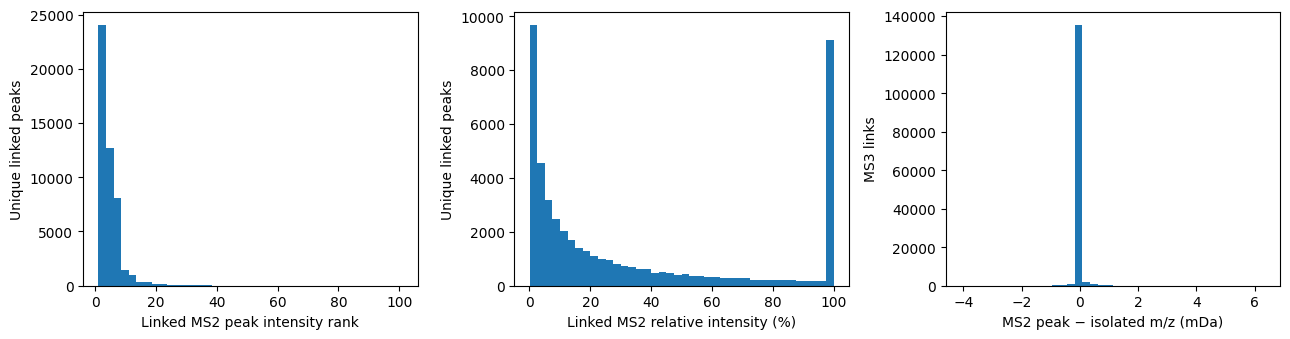

In [48]:
figure, axes = plt.subplots(1, 3, figsize=(13, 3.5))
distributions = [
    (linked_peak_ranks, "Linked MS2 peak intensity rank", "Unique linked peaks"),
    (linked_peak_relative_intensities, "Linked MS2 relative intensity (%)", "Unique linked peaks"),
    (1000 * mass_errors_da, "MS2 peak − isolated m/z (mDa)", "MS3 links"),
]

for ax, (values, label, count_label) in zip(axes, distributions):
    ax.hist(values[np.isfinite(values)], bins=40)
    ax.set_xlabel(label)
    ax.set_ylabel(count_label)

figure.tight_layout()
save_report_plot("linked_peak_distributions", "Linked-peak intensity ranks, relative intensities, and parent-link mass errors")
plt.show()

#### Coverage among active MS2 parents

An active MS2 parent has at least one resolved MS3 child. A linked peak is a unique `(parent, peak index)` pair, regardless of the number of children. The following distributions use active parents only; the dataset-wide and active-parent pooled coverage values above remain separate.

In [49]:
from IPython.display import Markdown, display

block5_details = {}
active_parent_keys = {parent_key for parent_key, child_key in ms3_parent_pairs}
active_ms2 = {
    spectrum_key(spectrum): spectrum for spectrum in ms2_spectra
    if spectrum_key(spectrum) in active_parent_keys
}
linked_indices_by_parent = {key: [] for key in active_ms2}
for parent_key, peak_index in linked_peak_children:
    linked_indices_by_parent[parent_key].append(peak_index)
linked_indices_by_parent = {
    key: np.array(sorted(indices), dtype=int) for key, indices in linked_indices_by_parent.items()
}

print(f"Active MS2 parents: {len(active_ms2):,}")

Active MS2 parents: 10,850


In [50]:
active_peak_counts = np.array([len(parent.peaks) for parent in active_ms2.values()], dtype=int)
active_linked_peak_counts = np.array([len(indices) for indices in linked_indices_by_parent.values()], dtype=int)
active_peak_coverage_pct = np.array([
    report_percent(linked, total) for linked, total in zip(active_linked_peak_counts, active_peak_counts)
])
active_coverage_table = report_summary({
    "Peak coverage per active MS2 (%)": active_peak_coverage_pct,
    "Unique linked peaks per active MS2": active_linked_peak_counts,
})
display(Markdown(active_coverage_table))

block5_details[1] = "\n\n".join([
    "### Coverage among active MS2 parents",
    f"Active parents have at least one resolved MS3 child (N = {len(active_ms2):,}). "
    "Linked peaks are unique (parent, peak index) pairs. These distributions give each active parent equal weight.",
    active_coverage_table,
])

| Metric | N | Missing/nonfinite | Mean | Median | Q1 | Q3 | Min | Max |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Peak coverage per active MS2 (%) | 10,850 | 0 | 24.49 | 21.74 | 14.71 | 31.25 | 0.76 | 100.00 |
| Unique linked peaks per active MS2 | 10,850 | 0 | 4.48 | 5.00 | 4.00 | 5.00 | 1.00 | 9.00 |

#### Intensity coverage in active MS2 parents

For each parent, divide the sum of its unique linked-peak intensities by the sum of all its peak intensities. The pooled ratio sums raw intensities across valid active parents before dividing, so higher-total-intensity parents carry more weight. The per-parent distribution weights parents equally.

Intensity summaries and peak-selection bias exclude parents with nonfinite or negative intensities, or nonpositive total intensity; peak-count coverage still includes these parents. Exclusions are reported.

In [51]:
active_total_intensity = []
active_linked_intensity = []

for key, parent in active_ms2.items():
    intensities = parent.intensity
    total = intensities.sum()
    valid = np.isfinite(intensities).all() and np.all(intensities >= 0) and np.isfinite(total) and total > 0
    linked = intensities[linked_indices_by_parent[key]].sum() if valid else np.nan
    active_total_intensity.append(total if valid else np.nan)
    active_linked_intensity.append(linked)

active_total_intensity = np.array(active_total_intensity)
active_linked_intensity = np.array(active_linked_intensity)
valid_active_intensity = np.isfinite(active_total_intensity)
active_intensity_coverage_pct = 100 * active_linked_intensity / active_total_intensity

In [52]:
pooled_intensity_coverage_pct = report_percent(np.nansum(active_linked_intensity), np.nansum(active_total_intensity))
intensity_pooled_table = report_table(["Measure", "Coverage (%)", "Valid active parents", "Excluded parents"], [
    ["Pooled intensity coverage", pooled_intensity_coverage_pct, valid_active_intensity.sum(), (~valid_active_intensity).sum()],
])
intensity_distribution_table = report_summary({
    "Intensity coverage per active MS2 (%)": active_intensity_coverage_pct,
})
display(Markdown(intensity_pooled_table + "\n\n" + intensity_distribution_table))

| Measure | Coverage (%) | Valid active parents | Excluded parents |
| --- | --- | --- | --- |
| Pooled intensity coverage | 76.59 | 10,850 | 0 |

| Metric | N | Missing/nonfinite | Mean | Median | Q1 | Q3 | Min | Max |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Intensity coverage per active MS2 (%) | 10,850 | 0 | 70.03 | 80.13 | 57.21 | 90.45 | 0.14 | 100.00 |

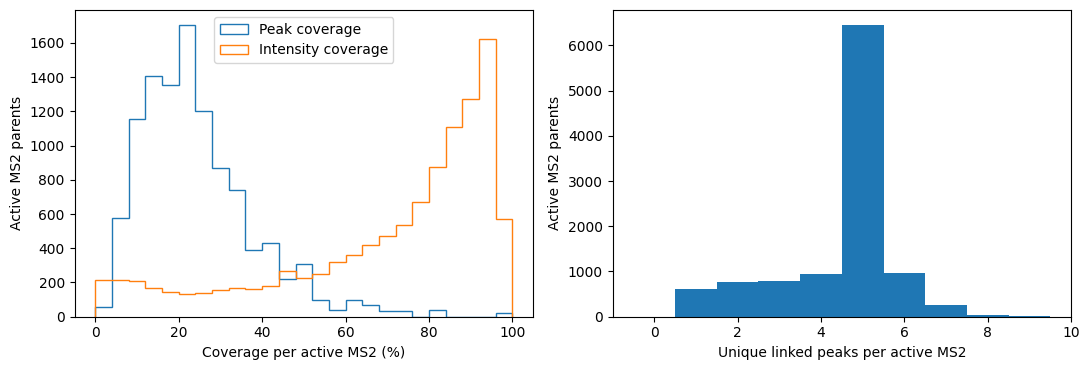

In [53]:
figure, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for values, label in [(active_peak_coverage_pct, "Peak coverage"), (active_intensity_coverage_pct, "Intensity coverage")]:
    axes[0].hist(values[np.isfinite(values)], bins=np.linspace(0, 100, 26), histtype="step", label=label)
axes[0].set(xlabel="Coverage per active MS2 (%)", ylabel="Active MS2 parents")
axes[0].legend()
axes[1].hist(active_linked_peak_counts, bins=np.arange(max(active_linked_peak_counts, default=0) + 2) - 0.5)
axes[1].set(xlabel="Unique linked peaks per active MS2", ylabel="Active MS2 parents")
figure.tight_layout()
save_report_plot("active_ms2_coverage", "Peak and intensity coverage, and linked-peak counts in active MS2 parents")
plt.show()

block5_details[2] = "\n\n".join([
    "### Intensity coverage in active MS2 parents",
    "Linked peaks contribute intensity once. The pooled ratio sums raw linked intensities and divides by "
    "raw total intensity across valid active parents; the per-parent distribution weights parents equally. "
    "Parents with nonfinite/negative intensities or nonpositive total intensity are excluded and counted below.",
    intensity_pooled_table, intensity_distribution_table, report_images["active_ms2_coverage"],
])

#### Collision-energy selection

Keep parent MS2 energy separate from child MS3 energy. Parent statistics count each MS2 parent and each linked peak once. Child-energy statistics and the cross-table count individual **resolved MS3 links**, including multiple children of one peak. These child counts therefore exclude orphan MS3 spectra.

Energy values are taken directly from `collision_energy`, without unit conversion or rounding for grouping; missing/nonfinite values form an `Unknown` category. Intensity coverage uses valid active parents only. These are descriptive comparisons, not explanations of acquisition choices.

In [54]:
def collision_energy_key(spectrum):
    try:
        value = float(spectrum.metadata.get("collision_energy"))
    except (TypeError, ValueError):
        return "Unknown"
    return value if np.isfinite(value) else "Unknown"


ms2_energy_counts = Counter(collision_energy_key(parent) for parent in ms2_spectra)
active_parent_energies = np.array([collision_energy_key(parent) for parent in active_ms2.values()], dtype=object)
active_energy_counts = Counter(active_parent_energies)
parent_energies = sorted(ms2_energy_counts, key=lambda energy: (isinstance(energy, str), energy))

In [55]:
parent_energy_distribution_table = report_table(
    ["Parent MS2 CE", "All MS2", "% of all MS2", "Active parents", "% of active parents"], [
        [energy, ms2_energy_counts[energy], report_percent(ms2_energy_counts[energy], len(ms2_spectra)),
         active_energy_counts[energy], report_percent(active_energy_counts[energy], len(active_ms2))]
        for energy in parent_energies
    ],
)
display(Markdown(parent_energy_distribution_table))

| Parent MS2 CE | All MS2 | % of all MS2 | Active parents | % of active parents |
| --- | --- | --- | --- | --- |
| 15.00 | 2,813 | 8.94 | 2,750 | 25.35 |
| 20.00 | 10,208 | 32.44 | 0 | 0.00 |
| 30.00 | 6,173 | 19.62 | 5,875 | 54.15 |
| 45.00 | 2,109 | 6.70 | 2,034 | 18.75 |
| 60.00 | 10,154 | 32.27 | 185 | 1.71 |
| 75.00 | 6 | 0.02 | 6 | 0.06 |

In [56]:
parent_energy_rows = []
for energy in parent_energies:
    selected = active_parent_energies == energy
    total_parents, active_parents = ms2_energy_counts[energy], active_energy_counts[energy]
    peaks = active_peak_counts[selected].sum()
    linked = active_linked_peak_counts[selected].sum()
    intensity_coverage = report_percent(
        np.nansum(active_linked_intensity[selected]), np.nansum(active_total_intensity[selected])
    )
    parent_energy_rows.append([
        energy, total_parents, active_parents, report_percent(active_parents, total_parents),
        peaks, linked, report_percent(linked, peaks), intensity_coverage, (selected & valid_active_intensity).sum(),
    ])
parent_energy_coverage_table = report_table(
    ["Parent MS2 CE", "All MS2", "Active", "Active (%)", "Peaks in active", "Linked peaks",
     "Peak coverage (%)", "Intensity coverage (%)", "Valid intensity parents"], parent_energy_rows,
)
display(Markdown(parent_energy_coverage_table))

| Parent MS2 CE | All MS2 | Active | Active (%) | Peaks in active | Linked peaks | Peak coverage (%) | Intensity coverage (%) | Valid intensity parents |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 15.00 | 2,813 | 2,750 | 97.76 | 47,385 | 11,775 | 24.85 | 78.00 | 2,750 |
| 20.00 | 10,208 | 0 | 0.00 | 0 | 0 | — | — | 0 |
| 30.00 | 6,173 | 5,875 | 95.17 | 138,321 | 26,400 | 19.09 | 79.52 | 5,875 |
| 45.00 | 2,109 | 2,034 | 96.44 | 75,553 | 9,475 | 12.54 | 69.98 | 2,034 |
| 60.00 | 10,154 | 185 | 1.82 | 13,245 | 900 | 6.80 | 53.15 | 185 |
| 75.00 | 6 | 6 | 100.00 | 665 | 26 | 3.91 | 31.78 | 6 |

#### MS2 energy choices within each feature forest

For every `feature_id`, show the set of all observed MS2 energies and the set belonging to active MS2 parents (at least one resolved MS3 child). Multiple active energies are kept. `None` means no spectra in that group; `Unknown` means a spectrum exists but its energy is missing/nonfinite.

The summary groups features with the same available/active energy sets. Expand the full table to inspect every feature, or use the CSV for filtering.

In [57]:
def format_energy_set(energies):
    energies = sorted(energies, key=lambda energy: (isinstance(energy, str), energy))
    labels = [str(int(energy)) if isinstance(energy, float) and energy.is_integer() else str(energy)
              for energy in energies]
    return "{" + ", ".join(labels) + "}" if labels else "None"


feature_energy_rows = []
for feature_id, forest in sorted(forests.items()):
    parents = {node_id: spectrum for node_id, spectrum in forest.nodes.items() if spectrum.ms_level == 2}
    active = [parent for node_id, parent in parents.items() if (feature_id, node_id) in active_parent_keys]
    energies = {collision_energy_key(parent) for parent in parents.values()}
    active_energies = {collision_energy_key(parent) for parent in active}
    feature_energy_rows.append([
        feature_id, format_energy_set(energies), format_energy_set(active_energies), len(parents), len(active),
    ])

In [58]:
feature_energy_columns = ["Feature ID", "All MS2 energies", "Active MS2 energies", "MS2 spectra", "Active MS2 parents"]
feature_energy_table = report_table(feature_energy_columns, feature_energy_rows)
feature_energy_patterns = Counter((row[1], row[2]) for row in feature_energy_rows)
feature_energy_pattern_table = report_table(["All MS2 energies", "Active MS2 energies", "Feature forests"], [
    [energies, active_energies, count] for (energies, active_energies), count in feature_energy_patterns.most_common()
])
feature_energy_details = (
    f"<details>\n<summary>All {len(feature_energy_rows):,} feature forests: MS2 energy choices</summary>\n\n"
    + feature_energy_table + "\n\n</details>"
)
feature_energy_note = (
    "Active energies belong to MS2 spectra with at least one resolved MS3 child; multiple active energies are kept. "
    "None means no spectra in that group; Unknown means a spectrum exists with missing/nonfinite energy. "
    "The pattern summary counts feature forests, not parent spectra."
)

In [59]:
import csv

feature_energy_csv_path = report_image_dir / "feature_ms2_energy_choices.csv"
with feature_energy_csv_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(feature_energy_columns)
    writer.writerows(feature_energy_rows)

feature_energy_csv_link = f"[All feature forests (CSV)]({feature_energy_csv_path.relative_to(report_dir).as_posix()})"
display(Markdown("\n\n".join([feature_energy_pattern_table, feature_energy_csv_link, feature_energy_details])))

| All MS2 energies | Active MS2 energies | Feature forests |
| --- | --- | --- |
| {20, 30, 60} | {30} | 5,103 |
| {15, 20, 60} | {15} | 1,976 |
| {20, 45, 60} | {45} | 1,604 |
| {15, 20, 30, 60} | {15, 30} | 522 |
| {20, 30, 45, 60} | {30, 45} | 210 |
| {15, 20, 30, 60} | {15} | 131 |
| {20, 60} | {60} | 119 |
| {15, 20, 45, 60} | {15, 45} | 105 |
| {20, 30, 60} | None | 58 |
| {20} | None | 51 |
| {20, 30, 45, 60} | {45} | 44 |
| {20, 45, 60} | {45, 60} | 36 |
| {20, 60} | None | 33 |
| {20, 45, 60} | None | 22 |
| {15, 20, 30, 60} | {30} | 18 |
| {45, 60} | {45} | 18 |
| {20, 45} | None | 16 |
| {20, 30} | None | 14 |
| {60} | {60} | 13 |
| {20, 30} | {30} | 12 |
| {15, 20, 45, 60} | {45} | 12 |
| {20, 30, 45, 60} | {30} | 8 |
| {15, 20, 60} | None | 7 |
| {60} | None | 5 |
| {15, 20, 60} | {15, 60} | 4 |
| {15, 20, 45, 60} | {15} | 4 |
| {15, 20, 60} | {60} | 4 |
| {20, 60, 75} | {60, 75} | 4 |
| {20, 45, 60} | {60} | 4 |
| {15, 20} | {15} | 3 |
| {30} | None | 3 |
| {45} | None | 3 |
| {20, 45} | {45} | 2 |
| {15, 60} | {15} | 2 |
| {15, 60} | None | 2 |
| {45, 60} | None | 2 |
| {45} | {45} | 2 |
| {15} | {15} | 1 |
| {15, 20, 30, 45, 60} | {15, 30, 45} | 1 |
| {15, 30, 60} | {15, 30} | 1 |
| {60, 75} | {60, 75} | 1 |
| {20, 60, 75} | {75} | 1 |

[All feature forests (CSV)](MSnLib_stats_report_files/feature_ms2_energy_choices.csv)

<details>
<summary>All 10,181 feature forests: MS2 energy choices</summary>

| Feature ID | All MS2 energies | Active MS2 energies | MS2 spectra | Active MS2 parents |
| --- | --- | --- | --- | --- |
| 20240502_pluskal_enamine_5007_A10_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A10_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A10_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A10_id_MSn_positive.mzML msn trees:13 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_A10_id_MSn_positive.mzML msn trees:14 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_A10_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A10_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A10_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A10_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A10_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_A11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A11_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A11_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5007_A11_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A11_id_MSn_positive.mzML msn trees:5 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_A11_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A11_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A11_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_A12_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A12_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A12_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A12_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A12_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A12_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A12_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A12_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A13_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A13_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A13_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A13_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A13_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A13_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A13_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A14_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A14_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A14_id_MSn_positive.mzML msn trees:15 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_A14_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A14_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A14_id_MSn_positive.mzML msn trees:18 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_A14_id_MSn_positive.mzML msn trees:19 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A15_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A15_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A15_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A15_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A15_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A15_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A15_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A15_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5007_A15_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A16_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A16_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A16_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A16_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5007_A16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A17_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A17_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A17_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A17_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_A17_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A17_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A18_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A18_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A18_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A18_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A18_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5007_A18_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A18_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5007_A19_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A19_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A19_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A19_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A19_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A19_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A19_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A19_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A20_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A20_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A20_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A20_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A20_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A20_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A20_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A21_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A21_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A21_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A21_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A21_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A21_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A22_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A22_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A22_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A22_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A22_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A3_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A3_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5007_A3_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A3_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A3_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A3_id_MSn_positive.mzML msn trees:8 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5007_A3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A4_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A4_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A4_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A4_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A4_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A4_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A4_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A5_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A5_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5007_A5_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A5_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_A5_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A5_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A5_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A5_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A5_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A5_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A6_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A6_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A6_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A6_id_MSn_positive.mzML msn trees:13 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_A6_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A6_id_MSn_positive.mzML msn trees:6 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_A6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A6_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A7_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A7_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A7_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A7_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A7_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A7_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A7_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A8_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A8_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A8_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A8_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A8_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A8_id_MSn_positive.mzML msn trees:6 | {20, 45} | None | 2 | 0 |
| 20240502_pluskal_enamine_5007_A8_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_A8_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_A8_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A9_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A9_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_A9_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A9_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A9_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_A9_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B10_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B10_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B10_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B10_id_MSn_positive.mzML msn trees:14 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5007_B10_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5007_B10_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B10_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B10_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B11_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B11_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B11_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B11_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B11_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_B11_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B11_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B11_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B12_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B12_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B12_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B12_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B12_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B12_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B12_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B12_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B13_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B13_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_B13_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B13_id_MSn_positive.mzML msn trees:14 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_B13_id_MSn_positive.mzML msn trees:2 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_B13_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B13_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B13_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B14_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B14_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B14_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B14_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B14_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_B14_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B15_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B15_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B15_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B15_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B15_id_MSn_positive.mzML msn trees:4 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_B15_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B15_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B15_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B16_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B16_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B16_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B16_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B16_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B16_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B16_id_MSn_positive.mzML msn trees:9 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_B17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B17_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B17_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B17_id_MSn_positive.mzML msn trees:13 | {60} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_B17_id_MSn_positive.mzML msn trees:2 | {15, 20} | {15} | 2 | 1 |
| 20240502_pluskal_enamine_5007_B17_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B17_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B17_id_MSn_positive.mzML msn trees:6 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_B17_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B17_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_B17_id_MSn_positive.mzML msn trees:9 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_B18_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B18_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B18_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B18_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B18_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B18_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B18_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B18_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B19_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B19_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B19_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B19_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B19_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B19_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B19_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B19_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B20_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B20_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B20_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B20_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B20_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B20_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B21_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B21_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B21_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B21_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B21_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B21_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B22_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B22_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B22_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B22_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B22_id_MSn_positive.mzML msn trees:8 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_B3_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B3_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B3_id_MSn_positive.mzML msn trees:13 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5007_B3_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B3_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B3_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B3_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B3_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B4_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_B4_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B4_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B4_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B4_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B4_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B4_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B4_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B5_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B5_id_MSn_positive.mzML msn trees:14 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_B5_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B5_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B5_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B5_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B5_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B6_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B6_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B6_id_MSn_positive.mzML msn trees:14 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_B6_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B6_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B6_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B6_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_B6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B7_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B7_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B7_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B7_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B7_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B7_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B7_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B7_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B7_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B8_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B8_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B8_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B8_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B8_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B8_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B8_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B8_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B9_id_MSn_positive.mzML msn trees:10 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_B9_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B9_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_B9_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B9_id_MSn_positive.mzML msn trees:5 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_B9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_B9_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C10_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C10_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C10_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C10_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C10_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C10_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_C10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C11_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C11_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C11_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C11_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C11_id_MSn_positive.mzML msn trees:5 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5007_C11_id_MSn_positive.mzML msn trees:6 | {20, 30} | None | 2 | 0 |
| 20240502_pluskal_enamine_5007_C11_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C12_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C12_id_MSn_positive.mzML msn trees:10 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5007_C12_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C12_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C12_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C12_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C12_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C12_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C12_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5007_C13_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C13_id_MSn_positive.mzML msn trees:11 | {30} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_C13_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C13_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C13_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C13_id_MSn_positive.mzML msn trees:6 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_C13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C13_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_C14_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C14_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C14_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C14_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C14_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_C14_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C15_id_MSn_positive.mzML msn trees:12 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_C15_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C15_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C15_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C15_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C15_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C16_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C16_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C16_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C16_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C16_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C16_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C16_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C17_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C17_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C17_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C17_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C17_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C17_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C18_id_MSn_positive.mzML msn trees:0 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C18_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C18_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C18_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C18_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C18_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C18_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C19_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C19_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_C19_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C19_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C19_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C19_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_C19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C20_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C20_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C20_id_MSn_positive.mzML msn trees:12 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_C20_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C20_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_C20_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C20_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C21_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C21_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C21_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C21_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_C21_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C21_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C21_id_MSn_positive.mzML msn trees:7 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_C21_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_C22_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C22_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C22_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C22_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C22_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C22_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C22_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_C3_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C3_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C3_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C3_id_MSn_positive.mzML msn trees:14 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_C3_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C3_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C3_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C4_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C4_id_MSn_positive.mzML msn trees:1 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_C4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C4_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C4_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C4_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C4_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C4_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C4_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C4_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C5_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C5_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C5_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C5_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C5_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C5_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C5_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C6_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C6_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C6_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C6_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C6_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C6_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C7_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C7_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_C7_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C7_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C7_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C7_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C7_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C7_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_C8_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C8_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C8_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C8_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C8_id_MSn_positive.mzML msn trees:6 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_C8_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C8_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_C9_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C9_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C9_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C9_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C9_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_C9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C9_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_C9_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_D10_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D10_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D10_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D10_id_MSn_positive.mzML msn trees:4 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_D10_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D10_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D10_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D11_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D11_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D11_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D11_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D11_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D11_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D11_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D12_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D12_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D12_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D12_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D12_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D12_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D12_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D12_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D13_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5007_D13_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_D13_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_D13_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D13_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D13_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D14_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D14_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D14_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D14_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D14_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D14_id_MSn_positive.mzML msn trees:16 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_D14_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D14_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D15_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D15_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D15_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D15_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D15_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D15_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D15_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D15_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_D16_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_D16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D16_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D16_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D16_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D16_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D17_id_MSn_positive.mzML msn trees:10 | {20, 45} | None | 2 | 0 |
| 20240502_pluskal_enamine_5007_D17_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D17_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D17_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D17_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D17_id_MSn_positive.mzML msn trees:7 | {20, 45} | None | 2 | 0 |
| 20240502_pluskal_enamine_5007_D17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D18_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D18_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D18_id_MSn_positive.mzML msn trees:13 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_D18_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D18_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D18_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D19_id_MSn_positive.mzML msn trees:10 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_D19_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D19_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D19_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D19_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D19_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D19_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D19_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_D19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D20_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D20_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D20_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D20_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D20_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D20_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_D20_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D21_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_D21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D21_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D21_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D21_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D21_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D21_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D21_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D21_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D22_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D22_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D22_id_MSn_positive.mzML msn trees:15 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_D22_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D22_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5007_D22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D22_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D3_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D3_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D3_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D3_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D3_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D3_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D4_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D4_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D4_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D4_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D4_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_D4_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D4_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D4_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D5_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D5_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D5_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D5_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D5_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D5_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D6_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D6_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D6_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D6_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D7_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D7_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D7_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D7_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D7_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D7_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D8_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D8_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D8_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D8_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D8_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D8_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D9_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D9_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D9_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D9_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D9_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D9_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_D9_id_MSn_positive.mzML msn trees:6 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_D9_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5007_E10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E10_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E10_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E10_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E10_id_MSn_positive.mzML msn trees:2 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_E10_id_MSn_positive.mzML msn trees:3 | {20, 30, 45, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5007_E10_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_E10_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E10_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E11_id_MSn_positive.mzML msn trees:10 | {60} | {60} | 1 | 1 |
| 20240502_pluskal_enamine_5007_E11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E11_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E11_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E11_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E11_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E11_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E12_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E12_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E12_id_MSn_positive.mzML msn trees:14 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_E12_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E12_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E12_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E13_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E13_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E13_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E13_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E13_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E13_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E13_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E13_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E13_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E14_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E14_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E14_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E14_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_E14_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E14_id_MSn_positive.mzML msn trees:5 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_E14_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E14_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E15_id_MSn_positive.mzML msn trees:10 | {20, 30} | {30} | 2 | 1 |
| 20240502_pluskal_enamine_5007_E15_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_E15_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_E15_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E15_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E15_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E15_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E15_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E15_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_E16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E16_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E16_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E16_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E16_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E16_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_E16_id_MSn_positive.mzML msn trees:8 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_E16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E17_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_E17_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5007_E17_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E17_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E17_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E17_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E18_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E18_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E18_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E18_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E18_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E18_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E19_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E19_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E19_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E19_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E19_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_E19_id_MSn_positive.mzML msn trees:7 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_E19_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E20_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E20_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E20_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E20_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E20_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E20_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E20_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E20_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E21_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E21_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E21_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E21_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E21_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E21_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E22_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E22_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E22_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E22_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E22_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E22_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E3_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E3_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E3_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5007_E3_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E3_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E3_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E3_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E3_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E3_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E4_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5007_E4_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E4_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E4_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E4_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E4_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E4_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E4_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E4_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E5_id_MSn_positive.mzML msn trees:10 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_E5_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E5_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E5_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E5_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E5_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E5_id_MSn_positive.mzML msn trees:5 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_E5_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E5_id_MSn_positive.mzML msn trees:9 | {20, 45} | {45} | 2 | 1 |
| 20240502_pluskal_enamine_5007_E6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E6_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E6_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E6_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E6_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E6_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E6_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_E7_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E7_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E7_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E7_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E7_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E7_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E7_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E7_id_MSn_positive.mzML msn trees:9 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_E8_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E8_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E8_id_MSn_positive.mzML msn trees:3 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_E8_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E8_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E8_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E8_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E9_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E9_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E9_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E9_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E9_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E9_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_E9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F10_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F10_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F10_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F10_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F10_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F10_id_MSn_positive.mzML msn trees:5 | {15, 20, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5007_F10_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F10_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F11_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F11_id_MSn_positive.mzML msn trees:10 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_F11_id_MSn_positive.mzML msn trees:2 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_F11_id_MSn_positive.mzML msn trees:3 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_F11_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F11_id_MSn_positive.mzML msn trees:5 | {60} | {60} | 1 | 1 |
| 20240502_pluskal_enamine_5007_F11_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F11_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F12_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F12_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F12_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_F12_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F12_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F12_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F12_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F12_id_MSn_positive.mzML msn trees:6 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_F12_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F12_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F13_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F13_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F13_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F13_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F13_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F13_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F13_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F14_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F14_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F14_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F14_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F14_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F14_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_F14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F15_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F15_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F15_id_MSn_positive.mzML msn trees:2 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_F15_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F15_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F15_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F15_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F15_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F16_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F16_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F16_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F16_id_MSn_positive.mzML msn trees:12 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_F16_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F16_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F16_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F16_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F16_id_MSn_positive.mzML msn trees:8 | {20, 45} | {45} | 2 | 1 |
| 20240502_pluskal_enamine_5007_F16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F17_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_F17_id_MSn_positive.mzML msn trees:11 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5007_F17_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F17_id_MSn_positive.mzML msn trees:14 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_F17_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F17_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_F17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F18_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F18_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F18_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F18_id_MSn_positive.mzML msn trees:3 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_F18_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F18_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F18_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F19_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F19_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F19_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F19_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F19_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F19_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F19_id_MSn_positive.mzML msn trees:6 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_F19_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F19_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F19_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F20_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F20_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5007_F20_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F20_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F20_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F20_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F20_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F20_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F21_id_MSn_positive.mzML msn trees:1 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_F21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F21_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F21_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F21_id_MSn_positive.mzML msn trees:4 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5007_F21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F21_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F21_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F21_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F22_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F22_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F22_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F22_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F22_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F22_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F3_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F3_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F3_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F3_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_F3_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F3_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F3_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F4_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F4_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F4_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F4_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F4_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F4_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F4_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F5_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F5_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F5_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F5_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F5_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F5_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_F6_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F6_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F6_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F6_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F6_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F6_id_MSn_positive.mzML msn trees:4 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_F6_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F6_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F7_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F7_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F7_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F7_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F7_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F7_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F7_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F7_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F7_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F8_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F8_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F8_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F8_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F8_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F8_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_F8_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F8_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F9_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F9_id_MSn_positive.mzML msn trees:1 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_F9_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F9_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F9_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F9_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_F9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F9_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_F9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G10_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G10_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G10_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G10_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G10_id_MSn_positive.mzML msn trees:14 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5007_G10_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G10_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G10_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G10_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G10_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_G11_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G11_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G11_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G11_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G11_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G11_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G11_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G12_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G12_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G12_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G12_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G12_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G12_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G12_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G13_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G13_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G13_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G13_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G13_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G13_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G13_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G14_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G14_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G14_id_MSn_positive.mzML msn trees:14 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_G14_id_MSn_positive.mzML msn trees:5 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_G14_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G14_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G15_id_MSn_positive.mzML msn trees:10 | {20, 30, 45, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5007_G15_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G15_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G15_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G15_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G15_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G15_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G16_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_G16_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G16_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G16_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G16_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G17_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G17_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_G17_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G17_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G17_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G18_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G18_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G18_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G18_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G18_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G18_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G19_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G19_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G19_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G19_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G19_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G19_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_G20_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G20_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G20_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G20_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G20_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G20_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G20_id_MSn_positive.mzML msn trees:8 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_G20_id_MSn_positive.mzML msn trees:9 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_G21_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G21_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G21_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G21_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G22_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G22_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G22_id_MSn_positive.mzML msn trees:11 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_G22_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G22_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G22_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G22_id_MSn_positive.mzML msn trees:5 | {20, 30} | None | 2 | 0 |
| 20240502_pluskal_enamine_5007_G22_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G3_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G3_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_G3_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G3_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G3_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G3_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G3_id_MSn_positive.mzML msn trees:8 | {45} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_G3_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G4_id_MSn_positive.mzML msn trees:11 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_G4_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G4_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G4_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G4_id_MSn_positive.mzML msn trees:16 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_G4_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G4_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G4_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G5_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G5_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G5_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G5_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G5_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G5_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G6_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G6_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G6_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G6_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G6_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G6_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5007_G6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G7_id_MSn_positive.mzML msn trees:12 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_G7_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G7_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G7_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G7_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G7_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G7_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5007_G7_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G8_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G8_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G8_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G8_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_G8_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_G8_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G8_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G8_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G8_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5007_G9_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G9_id_MSn_positive.mzML msn trees:12 | {45} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_G9_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G9_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G9_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G9_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_G9_id_MSn_positive.mzML msn trees:8 | {20, 30} | None | 2 | 0 |
| 20240502_pluskal_enamine_5007_G9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H10_id_MSn_positive.mzML msn trees:10 | {20, 30} | None | 2 | 0 |
| 20240502_pluskal_enamine_5007_H10_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H10_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H10_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H10_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H10_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_H11_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H11_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H11_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H11_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H11_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H11_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H12_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H12_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H12_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H12_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H12_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H12_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H12_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H13_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H13_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H13_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H13_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H13_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H13_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H14_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H14_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H14_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H14_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H14_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H14_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H14_id_MSn_positive.mzML msn trees:9 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_H15_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H15_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H15_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H15_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H15_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H15_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H15_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H15_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H16_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H16_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H16_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H16_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H16_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_H16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H17_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H17_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H17_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H17_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H17_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H17_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H18_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H18_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H18_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H18_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H18_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H18_id_MSn_positive.mzML msn trees:17 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H18_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H19_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H19_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H19_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H19_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H19_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H19_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H19_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_H19_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_H20_id_MSn_positive.mzML msn trees:10 | {15, 20, 45, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_H20_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H20_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H20_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H20_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H20_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5007_H20_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_H20_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H20_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H21_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H21_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H21_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H21_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H21_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H21_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H21_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H22_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H22_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H22_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_H22_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H22_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H3_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H3_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H3_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H3_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H3_id_MSn_positive.mzML msn trees:4 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5007_H3_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H3_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H4_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H4_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H4_id_MSn_positive.mzML msn trees:3 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_H4_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H4_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H4_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H4_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H4_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H5_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H5_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5007_H5_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H5_id_MSn_positive.mzML msn trees:8 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_H5_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H6_id_MSn_positive.mzML msn trees:10 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5007_H6_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H6_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_H6_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H6_id_MSn_positive.mzML msn trees:5 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_H6_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_H6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H7_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H7_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H7_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H7_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_H7_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H7_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H8_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H8_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H8_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H8_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H8_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H8_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H8_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H8_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H9_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H9_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_H9_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H9_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H9_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H9_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H9_id_MSn_positive.mzML msn trees:6 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_H9_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_H9_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I10_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I10_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I10_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I10_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I10_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I10_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I10_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I11_id_MSn_positive.mzML msn trees:1 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_I11_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I11_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I11_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I11_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I11_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I11_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_I12_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I12_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I12_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I12_id_MSn_positive.mzML msn trees:14 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_I12_id_MSn_positive.mzML msn trees:17 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I12_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I12_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I13_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I13_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I13_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I13_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I13_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I13_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I13_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I13_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I14_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I14_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I14_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I14_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I14_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I14_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I14_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I14_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I14_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I14_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I15_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I15_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I15_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I15_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I15_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I15_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_I15_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I15_id_MSn_positive.mzML msn trees:8 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_I15_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I16_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_I16_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I16_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I16_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I16_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I16_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I16_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I17_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I17_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I17_id_MSn_positive.mzML msn trees:12 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_I17_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I17_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I17_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I17_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I17_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I18_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I18_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I18_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I18_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I18_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I18_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I19_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I19_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I19_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I19_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I19_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I19_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I19_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I19_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I20_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I20_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I20_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I20_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I20_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I20_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I20_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I21_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I21_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I21_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I21_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I21_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I21_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I22_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I22_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I22_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I22_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I22_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I22_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I22_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I22_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I22_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I3_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I3_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I3_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I3_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I3_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I3_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I3_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I3_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I4_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I4_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I4_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I4_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I4_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I4_id_MSn_positive.mzML msn trees:9 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_I5_id_MSn_positive.mzML msn trees:0 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I5_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I5_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I5_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I5_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I5_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I5_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I6_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I6_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I6_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I6_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I6_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I6_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I7_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I7_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I7_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I7_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I7_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I7_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I7_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_I8_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I8_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I8_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I8_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I8_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I8_id_MSn_positive.mzML msn trees:7 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_I8_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_I9_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I9_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I9_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I9_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I9_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I9_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I9_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {60} | 3 | 1 |
| 20240502_pluskal_enamine_5007_I9_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J10_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J10_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J10_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J10_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J11_id_MSn_positive.mzML msn trees:0 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J11_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J11_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J11_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_J11_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J11_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_J11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J12_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J12_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J12_id_MSn_positive.mzML msn trees:2 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_J12_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J12_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J12_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J12_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J12_id_MSn_positive.mzML msn trees:9 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_J13_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J13_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J13_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J13_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J13_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J13_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J13_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J14_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J14_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J14_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J14_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J14_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J14_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J14_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J14_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J15_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J15_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J15_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J15_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J15_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J15_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J15_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J15_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J15_id_MSn_positive_20240503085441.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J15_id_MSn_positive_20240503085441.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J15_id_MSn_positive_20240503085441.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J15_id_MSn_positive_20240503085441.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J15_id_MSn_positive_20240503085441.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J15_id_MSn_positive_20240503085441.mzML msn trees:5 | {45, 60} | {45} | 2 | 1 |
| 20240502_pluskal_enamine_5007_J15_id_MSn_positive_20240503085441.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J15_id_MSn_positive_20240503085441.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J16_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J16_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J16_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J16_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J16_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J16_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J16_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J16_id_MSn_positive_20240503085832.mzML msn trees:0 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J16_id_MSn_positive_20240503085832.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J16_id_MSn_positive_20240503085832.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J16_id_MSn_positive_20240503085832.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J16_id_MSn_positive_20240503085832.mzML msn trees:3 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_J16_id_MSn_positive_20240503085832.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J16_id_MSn_positive_20240503085832.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J16_id_MSn_positive_20240503085832.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J17_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J17_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J17_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J17_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J17_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J17_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J17_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J17_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_J17_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J17_id_MSn_positive_20240503090216.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J17_id_MSn_positive_20240503090216.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J17_id_MSn_positive_20240503090216.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J17_id_MSn_positive_20240503090216.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J17_id_MSn_positive_20240503090216.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J17_id_MSn_positive_20240503090216.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J17_id_MSn_positive_20240503090216.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J17_id_MSn_positive_20240503090216.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J17_id_MSn_positive_20240503090216.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J18_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J18_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J18_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J18_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J18_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_J18_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J18_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J18_id_MSn_positive_20240503090600.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J18_id_MSn_positive_20240503090600.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J18_id_MSn_positive_20240503090600.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J18_id_MSn_positive_20240503090600.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J18_id_MSn_positive_20240503090600.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_J18_id_MSn_positive_20240503090600.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J18_id_MSn_positive_20240503090600.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J18_id_MSn_positive_20240503090600.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J19_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J19_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J19_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J19_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J19_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J19_id_MSn_positive_20240503090944.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J19_id_MSn_positive_20240503090944.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J19_id_MSn_positive_20240503090944.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J19_id_MSn_positive_20240503090944.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J19_id_MSn_positive_20240503090944.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J19_id_MSn_positive_20240503090944.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J20_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J20_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J20_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J20_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J20_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J20_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J20_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J20_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J20_id_MSn_positive_20240503091330.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J20_id_MSn_positive_20240503091330.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J20_id_MSn_positive_20240503091330.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J20_id_MSn_positive_20240503091330.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J20_id_MSn_positive_20240503091330.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J20_id_MSn_positive_20240503091330.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J20_id_MSn_positive_20240503091330.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J20_id_MSn_positive_20240503091330.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J21_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J21_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_J21_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J21_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J21_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J21_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J21_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J21_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J22_id_MSn_positive.mzML msn trees:0 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J22_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J22_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J22_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J22_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J22_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J3_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J3_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J3_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J3_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J3_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5007_J3_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J4_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J4_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J4_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5007_J4_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J4_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J4_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J4_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J5_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J5_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J5_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J5_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J5_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J5_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J5_id_MSn_positive.mzML msn trees:9 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_J6_id_MSn_positive.mzML msn trees:10 | {45, 60} | {45} | 2 | 1 |
| 20240502_pluskal_enamine_5007_J6_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J6_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J6_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J6_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J6_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J7_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J7_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J7_id_MSn_positive.mzML msn trees:13 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_J7_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J7_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J7_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J7_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J7_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J8_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J8_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J8_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J8_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J8_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J8_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J8_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J8_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J8_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5007_J8_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J9_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_J9_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J9_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J9_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J9_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J9_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_J9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K10_id_MSn_positive.mzML msn trees:1 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_K10_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K10_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K10_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K10_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K10_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K10_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K11_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K11_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K11_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K11_id_MSn_positive.mzML msn trees:13 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_K11_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K11_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K11_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_K11_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K12_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K12_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K12_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K12_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K12_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K12_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K12_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K12_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K13_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K13_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_K13_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K13_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5007_K13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K13_id_MSn_positive.mzML msn trees:8 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_K13_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K14_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K14_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K14_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K14_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K14_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K14_id_MSn_positive.mzML msn trees:8 | {20, 45} | None | 2 | 0 |
| 20240502_pluskal_enamine_5007_K14_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K15_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K15_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K15_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K15_id_MSn_positive.mzML msn trees:3 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_K15_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K15_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K15_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K16_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K16_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K16_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K16_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K16_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K17_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_K17_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K17_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K17_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K17_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K17_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K17_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K18_id_MSn_positive.mzML msn trees:10 | {20, 30} | {30} | 2 | 1 |
| 20240502_pluskal_enamine_5007_K18_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K18_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K18_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K18_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K18_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K19_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K19_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K19_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K19_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K19_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K19_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K19_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K19_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K20_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K20_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K20_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K20_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K20_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_K20_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K20_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5007_K20_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K20_id_MSn_positive.mzML msn trees:8 | {15, 20, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5007_K20_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K21_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K21_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K21_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K21_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K21_id_MSn_positive.mzML msn trees:7 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_K21_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K21_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K22_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K22_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K22_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5007_K22_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K22_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K22_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K3_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K3_id_MSn_positive.mzML msn trees:11 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_K3_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5007_K3_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K3_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K3_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K4_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K4_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K4_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K4_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K4_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K4_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_K5_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_K5_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K5_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K5_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K5_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5007_K5_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K5_id_MSn_positive.mzML msn trees:9 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_K6_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K6_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K6_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K6_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K6_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K6_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K7_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K7_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K7_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K7_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K7_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K7_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K7_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K7_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K8_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K8_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K8_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K8_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K8_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K8_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K8_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K8_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_K9_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K9_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K9_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K9_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K9_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K9_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_K9_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L10_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_L10_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L10_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L10_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L10_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_L11_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L11_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L11_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L11_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L11_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L11_id_MSn_positive.mzML msn trees:6 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_L11_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L12_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L12_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_L12_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L12_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L12_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L12_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L12_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L13_id_MSn_positive.mzML msn trees:10 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_L13_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L13_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L13_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L13_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L13_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L14_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L14_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L14_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L14_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L14_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L15_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L15_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L15_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L15_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L15_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L15_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L15_id_MSn_positive.mzML msn trees:6 | {20, 45} | None | 2 | 0 |
| 20240502_pluskal_enamine_5007_L15_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L15_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L15_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L16_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_L16_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L16_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L16_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_L16_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L16_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L17_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L17_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L17_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_L17_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_L17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L18_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L18_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L18_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_L18_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L18_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L18_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L18_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L19_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L19_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L19_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L19_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L19_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L19_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L19_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L20_id_MSn_positive.mzML msn trees:10 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5007_L20_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L20_id_MSn_positive.mzML msn trees:12 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5007_L20_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L20_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L20_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L20_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L21_id_MSn_positive.mzML msn trees:12 | {20, 45} | None | 2 | 0 |
| 20240502_pluskal_enamine_5007_L21_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L21_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L21_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L21_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L22_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L22_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L22_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L22_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L22_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L22_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L3_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L3_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L3_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L3_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L3_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L3_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L4_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L4_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L4_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L4_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_L4_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5007_L4_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_L4_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L5_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L5_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L5_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L5_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L5_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L5_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L5_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L6_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L6_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L6_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L6_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L6_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L7_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L7_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L7_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L7_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L7_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L7_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L8_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L8_id_MSn_positive.mzML msn trees:3 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_L8_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L8_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L8_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L8_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_L8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L9_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L9_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L9_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L9_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L9_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L9_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L9_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_L9_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_L9_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M10_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_M10_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M10_id_MSn_positive.mzML msn trees:3 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5007_M10_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M10_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M10_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M11_id_MSn_positive.mzML msn trees:10 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_M11_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M11_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M11_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M11_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M11_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M11_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M12_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M12_id_MSn_positive.mzML msn trees:12 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_M12_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M12_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M12_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M12_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_M13_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M13_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M13_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M13_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M13_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M13_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M13_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M13_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_M14_id_MSn_positive.mzML msn trees:10 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_M14_id_MSn_positive.mzML msn trees:2 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_M14_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M14_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M14_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M14_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_M14_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M15_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M15_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M15_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M15_id_MSn_positive.mzML msn trees:4 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_M15_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M15_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_M15_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M16_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M16_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_M16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M16_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M17_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M17_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M17_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M17_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M17_id_MSn_positive.mzML msn trees:6 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_M17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M17_id_MSn_positive_20240503130525.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M17_id_MSn_positive_20240503130525.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M17_id_MSn_positive_20240503130525.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M17_id_MSn_positive_20240503130525.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M17_id_MSn_positive_20240503130525.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M17_id_MSn_positive_20240503130525.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M17_id_MSn_positive_20240503130525.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M18_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M18_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M18_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M18_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M18_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M18_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M18_id_MSn_positive_20240503130918.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M18_id_MSn_positive_20240503130918.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M18_id_MSn_positive_20240503130918.mzML msn trees:14 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_M18_id_MSn_positive_20240503130918.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M18_id_MSn_positive_20240503130918.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M18_id_MSn_positive_20240503130918.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M18_id_MSn_positive_20240503130918.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M18_id_MSn_positive_20240503130918.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M18_id_MSn_positive_20240503130918.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M19_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M19_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M19_id_MSn_positive.mzML msn trees:5 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_M19_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M19_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M19_id_MSn_positive_20240503131302.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M19_id_MSn_positive_20240503131302.mzML msn trees:11 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5007_M19_id_MSn_positive_20240503131302.mzML msn trees:4 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_M19_id_MSn_positive_20240503131302.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M19_id_MSn_positive_20240503131302.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M19_id_MSn_positive_20240503131302.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M19_id_MSn_positive_20240503131302.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M20_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M20_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M20_id_MSn_positive.mzML msn trees:13 | {15, 20, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5007_M20_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M20_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M20_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M20_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M20_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M20_id_MSn_positive_20240503131647.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M20_id_MSn_positive_20240503131647.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M20_id_MSn_positive_20240503131647.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M20_id_MSn_positive_20240503131647.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M20_id_MSn_positive_20240503131647.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M20_id_MSn_positive_20240503131647.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M20_id_MSn_positive_20240503131647.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M20_id_MSn_positive_20240503131647.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M21_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M21_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M21_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M21_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M21_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M21_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M21_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M21_id_MSn_positive_20240503132038.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M21_id_MSn_positive_20240503132038.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M21_id_MSn_positive_20240503132038.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M21_id_MSn_positive_20240503132038.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M21_id_MSn_positive_20240503132038.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M21_id_MSn_positive_20240503132038.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_M21_id_MSn_positive_20240503132038.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M21_id_MSn_positive_20240503132038.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M22_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M22_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M22_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M22_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M22_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M22_id_MSn_positive.mzML msn trees:6 | {20, 60, 75} | {60, 75} | 3 | 2 |
| 20240502_pluskal_enamine_5007_M22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M22_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M22_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_M22_id_MSn_positive_20240503132422.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M22_id_MSn_positive_20240503132422.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M22_id_MSn_positive_20240503132422.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M22_id_MSn_positive_20240503132422.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M22_id_MSn_positive_20240503132422.mzML msn trees:5 | {20, 60, 75} | {60, 75} | 3 | 2 |
| 20240502_pluskal_enamine_5007_M22_id_MSn_positive_20240503132422.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M22_id_MSn_positive_20240503132422.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M22_id_MSn_positive_20240503132422.mzML msn trees:8 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_M22_id_MSn_positive_20240503132422.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M3_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M3_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M3_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M3_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M3_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M3_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M3_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M3_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M4_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M4_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M4_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_M4_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M4_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M4_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M5_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M5_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M5_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M5_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M5_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M5_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5007_M5_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_M5_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M5_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M6_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M6_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M6_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M6_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_M6_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_M6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M7_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M7_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_M7_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M7_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M7_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M7_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M7_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M7_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M7_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M7_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_M8_id_MSn_positive.mzML msn trees:10 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_M8_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M8_id_MSn_positive.mzML msn trees:13 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_M8_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M8_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M8_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M8_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M9_id_MSn_positive.mzML msn trees:10 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_M9_id_MSn_positive.mzML msn trees:2 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_M9_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M9_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M9_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M9_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_M9_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N10_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N10_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N10_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N10_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N10_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N10_id_MSn_positive.mzML msn trees:9 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_N11_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N11_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N11_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N11_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N11_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N11_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N11_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N11_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N12_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N12_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N12_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N12_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N12_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N12_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N12_id_MSn_positive.mzML msn trees:6 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_N12_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N13_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N13_id_MSn_positive.mzML msn trees:12 | {20, 30} | {30} | 2 | 1 |
| 20240502_pluskal_enamine_5007_N13_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_N13_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N13_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N13_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N13_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N13_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N13_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N14_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N14_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N14_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N14_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N14_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_N14_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N14_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N15_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N15_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N15_id_MSn_positive.mzML msn trees:4 | {20, 30} | {30} | 2 | 1 |
| 20240502_pluskal_enamine_5007_N15_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N15_id_MSn_positive.mzML msn trees:6 | {15, 20} | {15} | 2 | 1 |
| 20240502_pluskal_enamine_5007_N15_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N15_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N15_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N16_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N16_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N16_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N16_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N16_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N17_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N17_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N17_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N17_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_N17_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N17_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N18_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5007_N18_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_N18_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N18_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N18_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_N18_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N18_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N18_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N19_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_N19_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N19_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N19_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N19_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_N19_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N19_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N20_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N20_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_N20_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N20_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N20_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N20_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N20_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N21_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N21_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N21_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N21_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N21_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N21_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N21_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N22_id_MSn_positive.mzML msn trees:10 | {45, 60} | {45} | 2 | 1 |
| 20240502_pluskal_enamine_5007_N22_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N22_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N22_id_MSn_positive.mzML msn trees:6 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5007_N22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N22_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N22_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N3_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_N3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N3_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N3_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N3_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N3_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N3_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N3_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N4_id_MSn_positive.mzML msn trees:12 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_N4_id_MSn_positive.mzML msn trees:13 | {20, 30, 45, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5007_N4_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N4_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N4_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N4_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_N4_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N5_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_N5_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N5_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N5_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N5_id_MSn_positive.mzML msn trees:18 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_N5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N5_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N6_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5007_N6_id_MSn_positive.mzML msn trees:12 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5007_N6_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N6_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N6_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N6_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N6_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N6_id_MSn_positive.mzML msn trees:9 | {20, 45} | None | 2 | 0 |
| 20240502_pluskal_enamine_5007_N7_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N7_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N7_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_N7_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_N7_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N7_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N7_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N8_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5007_N8_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N8_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N8_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N8_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N8_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N8_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N8_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N9_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N9_id_MSn_positive.mzML msn trees:14 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_N9_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N9_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N9_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_N9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N9_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_N9_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O10_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5007_O10_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O10_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O10_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O10_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O10_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_O10_id_MSn_positive.mzML msn trees:8 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_O10_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O11_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O11_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O11_id_MSn_positive.mzML msn trees:5 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_O11_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O11_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O11_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O11_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O12_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O12_id_MSn_positive.mzML msn trees:2 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_O12_id_MSn_positive.mzML msn trees:4 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_O12_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O12_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O12_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O12_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O12_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O13_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O13_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O13_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O13_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O13_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O13_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O13_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O13_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O14_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O14_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O14_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O14_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_O14_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O14_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O14_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O15_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O15_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O15_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O15_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O15_id_MSn_positive.mzML msn trees:5 | {45, 60} | {45} | 2 | 1 |
| 20240502_pluskal_enamine_5007_O15_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O15_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O15_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O16_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O16_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O16_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5007_O16_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_O16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O16_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O16_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O17_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O17_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O17_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O17_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5007_O17_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O17_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O17_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O18_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O18_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O18_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O18_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O18_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O18_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O18_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O19_id_MSn_positive.mzML msn trees:11 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_O19_id_MSn_positive.mzML msn trees:12 | {20, 30} | {30} | 2 | 1 |
| 20240502_pluskal_enamine_5007_O19_id_MSn_positive.mzML msn trees:14 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_O19_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O19_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O19_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O19_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O20_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O20_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O20_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O20_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O20_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O20_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O21_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O21_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O21_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O21_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O21_id_MSn_positive.mzML msn trees:17 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_O21_id_MSn_positive.mzML msn trees:6 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_O21_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O21_id_MSn_positive.mzML msn trees:8 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_O22_id_MSn_positive.mzML msn trees:10 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_O22_id_MSn_positive.mzML msn trees:13 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_O22_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O22_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O22_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O22_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O22_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_O3_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O3_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O3_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O3_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O3_id_MSn_positive.mzML msn trees:17 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O3_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_O3_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O4_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O4_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O4_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O4_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O4_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O4_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_O4_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O5_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O5_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O5_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O5_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5007_O5_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O5_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O5_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O6_id_MSn_positive.mzML msn trees:10 | {60} | {60} | 1 | 1 |
| 20240502_pluskal_enamine_5007_O6_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O6_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O6_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_O6_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O6_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O6_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_O6_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O6_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5007_O7_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O7_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O7_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O7_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O7_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O7_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O7_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O8_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O8_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O8_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O8_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O8_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O8_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O8_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O8_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_O9_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O9_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O9_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O9_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O9_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O9_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_O9_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_O9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P10_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P10_id_MSn_positive.mzML msn trees:12 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_P10_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P10_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P10_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P10_id_MSn_positive.mzML msn trees:16 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_P10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P10_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_P11_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P11_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P11_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P11_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P11_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P11_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P12_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P12_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P12_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5007_P12_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P12_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P12_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P12_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P12_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P12_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P13_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P13_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P13_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P13_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P13_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P13_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P14_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P14_id_MSn_positive.mzML msn trees:2 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_P14_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P14_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P14_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P14_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P14_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P14_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P15_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P15_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P15_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P15_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P15_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_P15_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P15_id_MSn_positive.mzML msn trees:8 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5007_P15_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_P16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P16_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P16_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P17_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_P17_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P17_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P17_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P17_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_P17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P18_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P18_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P18_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P18_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P18_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P18_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P18_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P19_id_MSn_positive.mzML msn trees:1 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5007_P19_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P19_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P19_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P19_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P19_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P19_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P20_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P20_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P20_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P20_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P20_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P20_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P20_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P20_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P20_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P20_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P21_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P21_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P21_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P21_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P21_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P21_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P21_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P22_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P22_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P22_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5007_P22_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P22_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P22_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P3_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P3_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P3_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P3_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P3_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P3_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P4_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_P4_id_MSn_positive.mzML msn trees:11 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5007_P4_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P4_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P4_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P4_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5007_P4_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P4_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P5_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P5_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P5_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P5_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P5_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P5_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_P5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P5_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P6_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P6_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P6_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P6_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P6_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P6_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P6_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P7_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P7_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P7_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P7_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P7_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5007_P7_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P7_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P7_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5007_P8_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P8_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P8_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P8_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P8_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P8_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P8_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P9_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P9_id_MSn_positive.mzML msn trees:11 | {60} | {60} | 1 | 1 |
| 20240502_pluskal_enamine_5007_P9_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P9_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P9_id_MSn_positive.mzML msn trees:7 | {60} | {60} | 1 | 1 |
| 20240502_pluskal_enamine_5007_P9_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5007_P9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A10_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A10_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A10_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A10_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A10_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A10_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A10_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5008_A10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A10_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A11_id_MSn_positive.mzML msn trees:10 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_A11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A11_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A11_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A11_id_MSn_positive.mzML msn trees:14 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_A11_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A11_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A11_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A12_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A12_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A12_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A12_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A12_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A12_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A12_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A13_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5008_A13_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A13_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A13_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A13_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A13_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A13_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A14_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A14_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A14_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_A14_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A14_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A14_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A14_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A14_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A15_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A15_id_MSn_positive.mzML msn trees:11 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_A15_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A15_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A15_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A15_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A15_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5008_A15_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A15_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A15_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A16_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A16_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A16_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A16_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A17_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A17_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A17_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A17_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A18_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_A18_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A18_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A18_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A18_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A18_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A19_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A19_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A19_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A19_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A19_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A19_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A19_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A19_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_A19_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A20_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A20_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A20_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A20_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A20_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A20_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A20_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_A21_id_MSn_positive.mzML msn trees:11 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5008_A21_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A21_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A21_id_MSn_positive.mzML msn trees:6 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_A21_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A21_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A22_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_A22_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_A22_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A22_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A22_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A22_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A22_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_A22_id_MSn_positive.mzML msn trees:9 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5008_A3_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A3_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A3_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A3_id_MSn_positive.mzML msn trees:17 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A3_id_MSn_positive.mzML msn trees:19 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A3_id_MSn_positive.mzML msn trees:20 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A4_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A4_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A4_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A4_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A4_id_MSn_positive.mzML msn trees:17 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_A4_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A4_id_MSn_positive.mzML msn trees:21 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A5_id_MSn_positive.mzML msn trees:11 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_A5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A5_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A5_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A5_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A5_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A6_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_A6_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A6_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A6_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A6_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A6_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A6_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A6_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A7_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A7_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A7_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A7_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A7_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A7_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A7_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A8_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A8_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A8_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A8_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A8_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A8_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A8_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A9_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A9_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A9_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A9_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A9_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A9_id_MSn_positive.mzML msn trees:17 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A9_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_A9_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B10_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B10_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B10_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B10_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B10_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B10_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B11_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B11_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B11_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B11_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_B11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B11_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B12_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B12_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B12_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B12_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B12_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B12_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B12_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B13_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B13_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B13_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B13_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B13_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B13_id_MSn_positive.mzML msn trees:5 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_B13_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B13_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B14_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B14_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B14_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B14_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B14_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B14_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B14_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B15_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B15_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B15_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B15_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B15_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B15_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B15_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B16_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B16_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B16_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B16_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B16_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B17_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B17_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B17_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B17_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B17_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B17_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B18_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_B18_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B18_id_MSn_positive.mzML msn trees:12 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_B18_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B18_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B19_id_MSn_positive.mzML msn trees:11 | {45, 60} | {45} | 2 | 1 |
| 20240502_pluskal_enamine_5008_B19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B19_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B19_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B19_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B19_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B19_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B20_id_MSn_positive.mzML msn trees:11 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_B20_id_MSn_positive.mzML msn trees:12 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5008_B20_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B20_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B20_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B20_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B20_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B21_id_MSn_positive.mzML msn trees:10 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_B21_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B21_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B21_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B21_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B21_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B21_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B21_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B22_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B22_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B22_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B22_id_MSn_positive.mzML msn trees:13 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_B22_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B22_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B22_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B3_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_B3_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_B3_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B3_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B3_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B3_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B3_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B4_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_B4_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_B4_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B4_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B4_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B5_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B5_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B5_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B5_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_B5_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B5_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B5_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B6_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B6_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B6_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B6_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B6_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B7_id_MSn_positive.mzML msn trees:10 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_B7_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B7_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B7_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B7_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B7_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B7_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B8_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B8_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B8_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B8_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B8_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B8_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B8_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B9_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B9_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B9_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B9_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B9_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B9_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_B9_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C10_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C10_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C10_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C11_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C11_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C11_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C11_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C11_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C11_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C11_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C11_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_C12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C12_id_MSn_positive.mzML msn trees:11 | {15, 60} | {15} | 2 | 1 |
| 20240502_pluskal_enamine_5008_C12_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C12_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C12_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C12_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C12_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C12_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C12_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C13_id_MSn_positive.mzML msn trees:11 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_C13_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C13_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C13_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C13_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C13_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C13_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C13_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C14_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C14_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C14_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C14_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C14_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C14_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C14_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C15_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C15_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C15_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C15_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C15_id_MSn_positive.mzML msn trees:15 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5008_C15_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C15_id_MSn_positive.mzML msn trees:18 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5008_C15_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C16_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_C16_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C16_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C16_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C16_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C16_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_C17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C17_id_MSn_positive.mzML msn trees:2 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_C17_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C17_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C17_id_MSn_positive.mzML msn trees:5 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_C17_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C17_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C18_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_C18_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C18_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C18_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C18_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_C18_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_C19_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C19_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C19_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C19_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C19_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C19_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_C19_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C20_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C20_id_MSn_positive.mzML msn trees:12 | {45, 60} | {45} | 2 | 1 |
| 20240502_pluskal_enamine_5008_C20_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C20_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_C20_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C20_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C20_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C21_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C21_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C21_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C21_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5008_C21_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_C21_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C22_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C22_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C22_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_C22_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C22_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C22_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C22_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_C22_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C3_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C3_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C3_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C3_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C3_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C3_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C3_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_C4_id_MSn_positive.mzML msn trees:11 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_C4_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C4_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C4_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C4_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C4_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C4_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C4_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C5_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C5_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C5_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C5_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C5_id_MSn_positive.mzML msn trees:4 | {20, 30} | {30} | 2 | 1 |
| 20240502_pluskal_enamine_5008_C5_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C5_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_C5_id_MSn_positive.mzML msn trees:9 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_C6_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C6_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C6_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_C6_id_MSn_positive.mzML msn trees:2 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_C6_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C6_id_MSn_positive.mzML msn trees:6 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_C6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C7_id_MSn_positive.mzML msn trees:12 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_C7_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_C7_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C7_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C7_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C7_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_C7_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_C7_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C8_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C8_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C8_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C8_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C8_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C9_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C9_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_C9_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C9_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C9_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C9_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_C9_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D10_id_MSn_positive.mzML msn trees:13 | {20, 30, 45, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5008_D10_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D10_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D10_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D10_id_MSn_positive.mzML msn trees:17 | {15, 20, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5008_D10_id_MSn_positive.mzML msn trees:19 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D11_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D11_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D11_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D11_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D11_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D11_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_D11_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D12_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D12_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_D12_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D12_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D12_id_MSn_positive.mzML msn trees:15 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_D12_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_D12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D13_id_MSn_positive.mzML msn trees:10 | {15} | {15} | 1 | 1 |
| 20240502_pluskal_enamine_5008_D13_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D13_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D13_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D13_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D13_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D13_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5008_D13_id_MSn_positive.mzML msn trees:9 | {45, 60} | {45} | 2 | 1 |
| 20240502_pluskal_enamine_5008_D14_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D14_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D14_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D14_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D14_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_D14_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D14_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_D14_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D15_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D15_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D15_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D15_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D15_id_MSn_positive.mzML msn trees:5 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_D15_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D15_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_D15_id_MSn_positive.mzML msn trees:9 | {15, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5008_D16_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D16_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D16_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D16_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D16_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D17_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_D17_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D17_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D17_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D17_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D17_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D18_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D18_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D18_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D18_id_MSn_positive.mzML msn trees:4 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_D18_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_D18_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D18_id_MSn_positive.mzML msn trees:8 | {20, 30} | None | 2 | 0 |
| 20240502_pluskal_enamine_5008_D18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D19_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D19_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D19_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D19_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D19_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D19_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D20_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D20_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_D20_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D20_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D20_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_D20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D21_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_D21_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D21_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D21_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D21_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D22_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D22_id_MSn_positive.mzML msn trees:14 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_D22_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D22_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D22_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D22_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D22_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D22_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D3_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D3_id_MSn_positive.mzML msn trees:11 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_D3_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D3_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D3_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D3_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D3_id_MSn_positive.mzML msn trees:16 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_D3_id_MSn_positive.mzML msn trees:17 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D3_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D4_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D4_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D4_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D4_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D4_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D4_id_MSn_positive.mzML msn trees:7 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_D4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D4_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D5_id_MSn_positive.mzML msn trees:10 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_D5_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D5_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D5_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_D5_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D5_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D5_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D6_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D6_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D6_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D6_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D6_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D7_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D7_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D7_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D7_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D7_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D7_id_MSn_positive.mzML msn trees:8 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_D7_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D8_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D8_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D8_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D8_id_MSn_positive.mzML msn trees:15 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_D8_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D8_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D8_id_MSn_positive.mzML msn trees:19 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D9_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D9_id_MSn_positive.mzML msn trees:3 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_D9_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D9_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D9_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_D9_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E10_id_MSn_positive.mzML msn trees:11 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5008_E10_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E10_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E10_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E11_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E11_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E11_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E11_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E11_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E11_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E11_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E12_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E12_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E12_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E12_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_E12_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E12_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E13_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5008_E13_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E13_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E13_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E13_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E13_id_MSn_positive.mzML msn trees:6 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_E13_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E13_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E14_id_MSn_positive.mzML msn trees:10 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_E14_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E14_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E14_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E14_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E14_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_E14_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E15_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E15_id_MSn_positive.mzML msn trees:11 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_E15_id_MSn_positive.mzML msn trees:12 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5008_E15_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E15_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E15_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E15_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E15_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E16_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E16_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E16_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_E16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E16_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E16_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E17_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E17_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E17_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_E17_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E17_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E17_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E17_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_E18_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E18_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E18_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E18_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E18_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E18_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E19_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E19_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_E19_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E19_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E19_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E20_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_E20_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E20_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E20_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E20_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E20_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E20_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E21_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E21_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E21_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E21_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E21_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E21_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E21_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E22_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E22_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E22_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E22_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E22_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E22_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E22_id_MSn_positive.mzML msn trees:18 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E22_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E22_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E3_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E3_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E3_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E3_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E3_id_MSn_positive.mzML msn trees:7 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_E3_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E4_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5008_E4_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E4_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E4_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E5_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E5_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E5_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E5_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E5_id_MSn_positive.mzML msn trees:5 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_E5_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_E5_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E6_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E6_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E6_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E6_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E6_id_MSn_positive.mzML msn trees:16 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_E6_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E7_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_E7_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E7_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E7_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E7_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E7_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E7_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_E7_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E8_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E8_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E8_id_MSn_positive.mzML msn trees:14 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_E8_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E8_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E9_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E9_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E9_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E9_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_E9_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_E9_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F10_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F10_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F10_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F10_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F10_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F11_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F11_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F11_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F11_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F11_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F11_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F11_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F12_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F12_id_MSn_positive.mzML msn trees:12 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_F12_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F12_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F12_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F12_id_MSn_positive.mzML msn trees:5 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5008_F12_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5008_F13_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F13_id_MSn_positive.mzML msn trees:3 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_F13_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F13_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F13_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_F13_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F13_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F14_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_F14_id_MSn_positive.mzML msn trees:13 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5008_F14_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F14_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F14_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F14_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F14_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_F14_id_MSn_positive.mzML msn trees:8 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5008_F15_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F15_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F15_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F15_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F15_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F15_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F15_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F15_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F15_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F16_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F16_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_F16_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F16_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F16_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F16_id_MSn_positive.mzML msn trees:15 | {20, 45} | None | 2 | 0 |
| 20240502_pluskal_enamine_5008_F16_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F16_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F16_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F17_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F17_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F17_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F17_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F17_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F17_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F17_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F18_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F18_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F18_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_F18_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F18_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F19_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F19_id_MSn_positive.mzML msn trees:12 | {20, 30} | None | 2 | 0 |
| 20240502_pluskal_enamine_5008_F19_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F19_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F19_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F19_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F19_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F19_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F20_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F20_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F20_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F20_id_MSn_positive.mzML msn trees:3 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_F20_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F20_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F20_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F20_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F21_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F21_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F21_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F21_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F21_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F21_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F21_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F22_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F22_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F22_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F22_id_MSn_positive.mzML msn trees:3 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_F22_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F22_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F3_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F3_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F3_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F3_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F3_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F3_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_F3_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F4_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F4_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_F4_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F4_id_MSn_positive.mzML msn trees:13 | {45, 60} | {45} | 2 | 1 |
| 20240502_pluskal_enamine_5008_F4_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_F4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F4_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F4_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_F4_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F5_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_F5_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F5_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F5_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F5_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F5_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F5_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F6_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F6_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F6_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F6_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F7_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F7_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F7_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F7_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F7_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F7_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F7_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F7_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F8_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F8_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F8_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F8_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F8_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F8_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {60} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F8_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F8_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F9_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F9_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F9_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F9_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 45, 60} | {15, 30, 45} | 5 | 3 |
| 20240502_pluskal_enamine_5008_F9_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F9_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_F9_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G10_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G10_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G10_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G10_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G10_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G10_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_G10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G10_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G11_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G11_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5008_G11_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G11_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G11_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G11_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G12_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G12_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G12_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G12_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_G12_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_G12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G13_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G13_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G13_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G13_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_G13_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G13_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G13_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G14_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G14_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G14_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G14_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G14_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5008_G14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G14_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G15_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G15_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G15_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G15_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G15_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G15_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G15_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G16_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G16_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G16_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G16_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G16_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G16_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G16_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_G17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G17_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G17_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G17_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G17_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G17_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G17_id_MSn_positive.mzML msn trees:7 | {45, 60} | {45} | 2 | 1 |
| 20240502_pluskal_enamine_5008_G17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G18_id_MSn_positive.mzML msn trees:11 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_G18_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G18_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G19_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_G19_id_MSn_positive.mzML msn trees:11 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5008_G19_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G19_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G19_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G19_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G19_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G19_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G19_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_G20_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_G20_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G20_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G20_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G20_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G20_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G20_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G21_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G21_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G21_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G21_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G21_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G21_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_G22_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G22_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G22_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G22_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_G22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G3_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G3_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G3_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G3_id_MSn_positive.mzML msn trees:4 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_G3_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G3_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G3_id_MSn_positive.mzML msn trees:8 | {20, 30} | None | 2 | 0 |
| 20240502_pluskal_enamine_5008_G3_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G4_id_MSn_positive.mzML msn trees:13 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_G4_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G4_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G4_id_MSn_positive.mzML msn trees:6 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_G4_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G5_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G5_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G5_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G5_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G5_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G5_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G5_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G5_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G5_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G6_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G6_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G6_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G6_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G6_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G6_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G7_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G7_id_MSn_positive.mzML msn trees:2 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_G7_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G7_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G7_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G7_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G7_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G8_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G8_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G8_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5008_G8_id_MSn_positive.mzML msn trees:6 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_G8_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G8_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G9_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G9_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G9_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_G9_id_MSn_positive.mzML msn trees:13 | {45, 60} | {45} | 2 | 1 |
| 20240502_pluskal_enamine_5008_G9_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_G9_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H10_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H10_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H10_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_H10_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H10_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H10_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H11_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H11_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H11_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H11_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H11_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H11_id_MSn_positive.mzML msn trees:9 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5008_H12_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H12_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H12_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H12_id_MSn_positive.mzML msn trees:5 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_H12_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H12_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H12_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H13_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H13_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H13_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H13_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H13_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H13_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H13_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H14_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H14_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H14_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H14_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H14_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H14_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H15_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H15_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H15_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H15_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H15_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H15_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H15_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H15_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H16_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_H16_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H16_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H16_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H16_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_H16_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H16_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H16_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_H17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H17_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H17_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H17_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H17_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H17_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H17_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_H18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H18_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H18_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H18_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H18_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H18_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H19_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_H19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H19_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H19_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H19_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H19_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H19_id_MSn_positive.mzML msn trees:7 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_H19_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_H20_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H20_id_MSn_positive.mzML msn trees:11 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_H20_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H20_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H20_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H20_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H21_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H21_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H21_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H21_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H21_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H21_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H21_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H22_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H22_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H22_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H22_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_H22_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H3_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H3_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H3_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H3_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H4_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H4_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H4_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H4_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H4_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H4_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H4_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_H4_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H4_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H5_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H5_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H5_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H5_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H5_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_H5_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H6_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H6_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H6_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H6_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H6_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H6_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H7_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H7_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H7_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H7_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H7_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H7_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H7_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H7_id_MSn_positive.mzML msn trees:9 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_H8_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H8_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H8_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H8_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H8_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H8_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5008_H8_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_H9_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H9_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H9_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_H9_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I10_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I10_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I10_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I10_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I11_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I11_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_I11_id_MSn_positive.mzML msn trees:12 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_I11_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I11_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I11_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I11_id_MSn_positive.mzML msn trees:9 | {15, 30, 60} | {15, 30} | 3 | 2 |
| 20240502_pluskal_enamine_5008_I12_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I12_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_I12_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I12_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I12_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I12_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I12_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I12_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I13_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_I13_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_I13_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I13_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I13_id_MSn_positive.mzML msn trees:14 | {45, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5008_I13_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I13_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I14_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I14_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I14_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5008_I14_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I14_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I14_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I15_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I15_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I15_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I15_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I15_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I15_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_I15_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I15_id_MSn_positive.mzML msn trees:9 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_I16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I16_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I16_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I16_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I16_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I17_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I17_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I17_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_I17_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I17_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I17_id_MSn_positive.mzML msn trees:16 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_I17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I18_id_MSn_positive.mzML msn trees:11 | {60} | {60} | 1 | 1 |
| 20240502_pluskal_enamine_5008_I18_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I18_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I18_id_MSn_positive.mzML msn trees:8 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_I19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I19_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I19_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I19_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I19_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I19_id_MSn_positive.mzML msn trees:19 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_I19_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I20_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I20_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I20_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I20_id_MSn_positive.mzML msn trees:3 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5008_I20_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I20_id_MSn_positive.mzML msn trees:6 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_I20_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_I20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I21_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5008_I21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I21_id_MSn_positive.mzML msn trees:12 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5008_I21_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I21_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I21_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I21_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I22_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I22_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I22_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I22_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I22_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I22_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I3_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I3_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I3_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I3_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I3_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I3_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I3_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I4_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I4_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I4_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I4_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I4_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I4_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I4_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I4_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I5_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I5_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I5_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I5_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I5_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I5_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I5_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_I5_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I6_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I6_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I6_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I6_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I6_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_I6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I6_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I7_id_MSn_positive.mzML msn trees:10 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_I7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I7_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I7_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I7_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I7_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I7_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I7_id_MSn_positive.mzML msn trees:8 | {15, 20, 45, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_I8_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I8_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I8_id_MSn_positive.mzML msn trees:13 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_I8_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I8_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I8_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I8_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I9_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I9_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I9_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I9_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I9_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I9_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I9_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_I9_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J10_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J10_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J10_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J10_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J10_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J10_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J11_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J11_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J11_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J11_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_J11_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J11_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J11_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J12_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J12_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J12_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J12_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J12_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J12_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J12_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J13_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J13_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J13_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J13_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J13_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J13_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J13_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J13_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_J14_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_J14_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J14_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J14_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J14_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J14_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J14_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J14_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J14_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J15_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J15_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J15_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J15_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J15_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J15_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J15_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J15_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J16_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J16_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J16_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J16_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_J16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J16_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J17_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J17_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J17_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J17_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J17_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J17_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J18_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J18_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J18_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J18_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J18_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J18_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J19_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J19_id_MSn_positive.mzML msn trees:13 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5008_J19_id_MSn_positive.mzML msn trees:15 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_J19_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J19_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J19_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J19_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J20_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_J20_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J20_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_J20_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J20_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J20_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J21_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J21_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J21_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J21_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J21_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J21_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J21_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J21_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J22_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J22_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_J22_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_J22_id_MSn_positive.mzML msn trees:13 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_J22_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J22_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J22_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J22_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J3_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J3_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J3_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J3_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J3_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_J3_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J3_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_J3_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J3_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J4_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_J4_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J4_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_J4_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J4_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J4_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J4_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J5_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J5_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_J5_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J5_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J5_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J5_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J6_id_MSn_positive.mzML msn trees:12 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_J6_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J6_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J6_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J6_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_J6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J6_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J7_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J7_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J7_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J7_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J7_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J7_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J7_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_J8_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J8_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J8_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J8_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J8_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J8_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J8_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J8_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J9_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J9_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J9_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J9_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J9_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J9_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_J9_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K10_id_MSn_positive.mzML msn trees:10 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_K10_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K10_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K10_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K10_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K10_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K11_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K11_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K11_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K11_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K11_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K11_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K11_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_K12_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K12_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K12_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K12_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K12_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K12_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K13_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K13_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5008_K13_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K13_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K13_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K13_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K13_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K14_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K14_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K14_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K14_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K14_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K14_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K14_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K14_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K15_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K15_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K15_id_MSn_positive.mzML msn trees:12 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_K15_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K15_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K15_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K15_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_K15_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K16_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K16_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K16_id_MSn_positive.mzML msn trees:3 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_K16_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_K16_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K16_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K16_id_MSn_positive.mzML msn trees:8 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_K16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K17_id_MSn_positive.mzML msn trees:10 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5008_K17_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K17_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K17_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K17_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K17_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K18_id_MSn_positive.mzML msn trees:11 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_K18_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_K18_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K18_id_MSn_positive.mzML msn trees:5 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_K18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K18_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K19_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K19_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K19_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K19_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K19_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K19_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_K20_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K20_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K20_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K20_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K20_id_MSn_positive.mzML msn trees:15 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5008_K20_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K20_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K21_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K21_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K21_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K21_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K21_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K21_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K21_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K21_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K22_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K22_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K22_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K22_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K22_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K22_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_K22_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K3_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K3_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K3_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K3_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K3_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K3_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K4_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K4_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K4_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K4_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_K4_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K4_id_MSn_positive.mzML msn trees:8 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_K4_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K5_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_K5_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K5_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K5_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K5_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K5_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_K5_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K6_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K6_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K6_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5008_K6_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K6_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K6_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K6_id_MSn_positive.mzML msn trees:8 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_K7_id_MSn_positive.mzML msn trees:10 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_K7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K7_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K7_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K7_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K7_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K7_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K7_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_K8_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K8_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K8_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K8_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K8_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K8_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_K8_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K8_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K9_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K9_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K9_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K9_id_MSn_positive.mzML msn trees:13 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5008_K9_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K9_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_K9_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L10_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L10_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L10_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L10_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L10_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L10_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L10_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L10_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L11_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L11_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L11_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L11_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L11_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_L11_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L11_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L11_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L11_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L12_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L12_id_MSn_positive.mzML msn trees:12 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_L12_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L12_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L12_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L12_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L12_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L13_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L13_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L13_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5008_L13_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L13_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L13_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L13_id_MSn_positive.mzML msn trees:6 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_L13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L14_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L14_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L14_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L14_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L14_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L14_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L14_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L15_id_MSn_positive.mzML msn trees:10 | {20, 45} | None | 2 | 0 |
| 20240502_pluskal_enamine_5008_L15_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L15_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L15_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L15_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L15_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L15_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_L15_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L16_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L16_id_MSn_positive.mzML msn trees:3 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_L16_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L16_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L16_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_L16_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L16_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L17_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L17_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L17_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L17_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L17_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L17_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L18_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L18_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_L18_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L18_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L18_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L18_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L19_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L19_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L19_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L19_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L19_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L19_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L19_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L19_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L20_id_MSn_positive.mzML msn trees:10 | {60} | {60} | 1 | 1 |
| 20240502_pluskal_enamine_5008_L20_id_MSn_positive.mzML msn trees:12 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_L20_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_L20_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L20_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L20_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L20_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L21_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L21_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L21_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L21_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L21_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L21_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L21_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L21_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_L22_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L22_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L22_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L22_id_MSn_positive.mzML msn trees:14 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_L22_id_MSn_positive.mzML msn trees:15 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_L22_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L22_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L3_id_MSn_positive.mzML msn trees:10 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_L3_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L3_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_L3_id_MSn_positive.mzML msn trees:14 | {20, 30} | None | 2 | 0 |
| 20240502_pluskal_enamine_5008_L3_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L3_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L3_id_MSn_positive.mzML msn trees:18 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L3_id_MSn_positive.mzML msn trees:19 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L3_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L4_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_L4_id_MSn_positive.mzML msn trees:12 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5008_L4_id_MSn_positive.mzML msn trees:13 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_L4_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L4_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L4_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_L5_id_MSn_positive.mzML msn trees:1 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_L5_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L5_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L5_id_MSn_positive.mzML msn trees:4 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_L5_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_L5_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L5_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L5_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_L5_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L6_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L6_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L6_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L6_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L6_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L6_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L6_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L7_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L7_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L7_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L7_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L7_id_MSn_positive.mzML msn trees:15 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_L7_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L7_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L8_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L8_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_L8_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L8_id_MSn_positive.mzML msn trees:16 | {20, 30, 45, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5008_L8_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L8_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_L8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L8_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L9_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L9_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L9_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L9_id_MSn_positive.mzML msn trees:5 | {60, 75} | {60, 75} | 2 | 2 |
| 20240502_pluskal_enamine_5008_L9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L9_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_L9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M10_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M10_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M10_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M10_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M10_id_MSn_positive.mzML msn trees:15 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_M10_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M10_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M10_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_M10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M11_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M11_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M11_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M11_id_MSn_positive.mzML msn trees:15 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5008_M11_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M11_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M11_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M11_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M12_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M12_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_M12_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M12_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M12_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M12_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M12_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_M13_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_M13_id_MSn_positive.mzML msn trees:12 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_M13_id_MSn_positive.mzML msn trees:14 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_M13_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M13_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M13_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M13_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M14_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M14_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M14_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M14_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M14_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M14_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_M14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M14_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M15_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M15_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_M15_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M15_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M15_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M15_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {60} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M15_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M15_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M16_id_MSn_positive.mzML msn trees:12 | {60} | None | 1 | 0 |
| 20240502_pluskal_enamine_5008_M16_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_M16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M16_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M17_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M17_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M17_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M17_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M17_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M17_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M18_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M18_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M18_id_MSn_positive.mzML msn trees:13 | {20, 45} | None | 2 | 0 |
| 20240502_pluskal_enamine_5008_M18_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M18_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M18_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M18_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_M18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M19_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M19_id_MSn_positive.mzML msn trees:4 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5008_M19_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M19_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M19_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M20_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M20_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M20_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M20_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_M20_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M20_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M21_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M21_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M21_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M21_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_M21_id_MSn_positive.mzML msn trees:5 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_M21_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M21_id_MSn_positive.mzML msn trees:8 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_M21_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_M22_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M22_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M22_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M22_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M22_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M22_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M22_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M22_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_M3_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M3_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M3_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M3_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M3_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M3_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M3_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_M3_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M4_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M4_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M4_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M4_id_MSn_positive.mzML msn trees:15 | {20, 45} | None | 2 | 0 |
| 20240502_pluskal_enamine_5008_M4_id_MSn_positive.mzML msn trees:16 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_M4_id_MSn_positive.mzML msn trees:17 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_M4_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M4_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M4_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M5_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M5_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M5_id_MSn_positive.mzML msn trees:3 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_M5_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M5_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_M5_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_M5_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M6_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_M6_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M6_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M6_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M6_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M6_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M6_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M7_id_MSn_positive.mzML msn trees:10 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_M7_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M7_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M7_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M7_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_M7_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M7_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_M8_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M8_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M8_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M8_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M8_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M8_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_M8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M8_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M9_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M9_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M9_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M9_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M9_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_M9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N10_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_N10_id_MSn_positive.mzML msn trees:12 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5008_N10_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N10_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N10_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N11_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N11_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N11_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N11_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N11_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_N11_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N11_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N12_id_MSn_positive.mzML msn trees:1 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_N12_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N12_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N12_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N12_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N12_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N12_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N12_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_N12_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_N13_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N13_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N13_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N13_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_N13_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N13_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N14_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N14_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N14_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N14_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N14_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N14_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N15_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N15_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N15_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_N15_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N15_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N15_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N15_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N16_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N16_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_N16_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N16_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N16_id_MSn_positive.mzML msn trees:8 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_N16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N17_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_N17_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N17_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N17_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N17_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N18_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N18_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N18_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N18_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N18_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N18_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N19_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_N19_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N19_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N19_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N19_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N19_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N19_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_N20_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N20_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N20_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N20_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N20_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N20_id_MSn_positive.mzML msn trees:8 | {15, 20, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5008_N20_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N21_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N21_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N21_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N21_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_N21_id_MSn_positive.mzML msn trees:6 | {45, 60} | {45} | 2 | 1 |
| 20240502_pluskal_enamine_5008_N21_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N21_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_N22_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N22_id_MSn_positive.mzML msn trees:11 | {60} | {60} | 1 | 1 |
| 20240502_pluskal_enamine_5008_N22_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N22_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N22_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N22_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N3_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N3_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N3_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N3_id_MSn_positive.mzML msn trees:15 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_N3_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N3_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N3_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N4_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N4_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_N4_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N4_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N4_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N4_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N4_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N5_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N5_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N5_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N5_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N5_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_N5_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N5_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N5_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N6_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N6_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N6_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N6_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N6_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N6_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_N7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N7_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N7_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N7_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N7_id_MSn_positive.mzML msn trees:16 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_N7_id_MSn_positive.mzML msn trees:17 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N7_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N7_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N8_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N8_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N8_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N8_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N8_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N8_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N8_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_N8_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N9_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N9_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N9_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N9_id_MSn_positive.mzML msn trees:13 | {20, 45} | None | 2 | 0 |
| 20240502_pluskal_enamine_5008_N9_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N9_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N9_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N9_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_N9_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O10_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O10_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O10_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O10_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O10_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O10_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_O10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O11_id_MSn_positive.mzML msn trees:10 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_O11_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O11_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O11_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_O11_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O11_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O11_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O11_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O12_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O12_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O12_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O12_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O12_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O12_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O12_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O13_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O13_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O13_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5008_O13_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O13_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O13_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O14_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O14_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O14_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O14_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_O14_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O14_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O15_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O15_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O15_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O15_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O15_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O15_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_O15_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O15_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O16_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O16_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O16_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O16_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O16_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O16_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O16_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O17_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O17_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O17_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O17_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O17_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O17_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O17_id_MSn_positive.mzML msn trees:8 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5008_O18_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O18_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O18_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O18_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O18_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O18_id_MSn_positive.mzML msn trees:6 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5008_O18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O18_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O19_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O19_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O19_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O19_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O19_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O19_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O19_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O20_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_O20_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O20_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O20_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O20_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O20_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O20_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O21_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O21_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O21_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_O21_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O21_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_O22_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O22_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O22_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O22_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O22_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O22_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O22_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O3_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O3_id_MSn_positive.mzML msn trees:11 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_O3_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O3_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O3_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O3_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O3_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O4_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O4_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O4_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O4_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O4_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O4_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O4_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O4_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_O5_id_MSn_positive.mzML msn trees:10 | {60} | None | 1 | 0 |
| 20240502_pluskal_enamine_5008_O5_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O5_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_O5_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O5_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O5_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O6_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O6_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O6_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O6_id_MSn_positive.mzML msn trees:17 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O6_id_MSn_positive.mzML msn trees:18 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O6_id_MSn_positive.mzML msn trees:19 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O6_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_O7_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5008_O7_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O7_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O7_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O7_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O7_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O8_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_O8_id_MSn_positive.mzML msn trees:14 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_O8_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O8_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O8_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O9_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O9_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O9_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O9_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O9_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O9_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_O9_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P10_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P10_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P10_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P10_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P10_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P11_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P11_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P11_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P11_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P11_id_MSn_positive.mzML msn trees:8 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5008_P11_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P12_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P12_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P12_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_P12_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P12_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P12_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P12_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P12_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_P12_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P13_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P13_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P13_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P13_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P13_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P13_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P13_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P13_id_MSn_positive.mzML msn trees:9 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5008_P14_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P14_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P14_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P14_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P14_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P14_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P14_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P15_id_MSn_positive.mzML msn trees:10 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_P15_id_MSn_positive.mzML msn trees:11 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5008_P15_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P15_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5008_P15_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P15_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P15_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P15_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P16_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P16_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P16_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P16_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P16_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P16_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P16_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P17_id_MSn_positive.mzML msn trees:10 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_P17_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P17_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P17_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P17_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_P17_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P17_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P18_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P18_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P18_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P18_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P18_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_P18_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P19_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P19_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P19_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P19_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P19_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P19_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_P19_id_MSn_positive.mzML msn trees:9 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_P20_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P20_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P20_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P20_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P20_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P20_id_MSn_positive.mzML msn trees:6 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_P20_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5008_P21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P21_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P21_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P21_id_MSn_positive.mzML msn trees:7 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_P21_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P21_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P22_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P22_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P22_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P22_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P22_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P3_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P3_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P3_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P3_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P3_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P3_id_MSn_positive.mzML msn trees:7 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5008_P3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P4_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P4_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P4_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P4_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P4_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P4_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P4_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P5_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P5_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P5_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P5_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P5_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P5_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P5_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P6_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P6_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P6_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_P6_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P7_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P7_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P7_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P7_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_P7_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P7_id_MSn_positive.mzML msn trees:6 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5008_P7_id_MSn_positive.mzML msn trees:7 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5008_P7_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P8_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P8_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P8_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P8_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P8_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_P8_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5008_P8_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P9_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5008_P9_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P9_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P9_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P9_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P9_id_MSn_positive.mzML msn trees:5 | {45, 60} | {45} | 2 | 1 |
| 20240502_pluskal_enamine_5008_P9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5008_P9_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A10_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A10_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_A10_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A10_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A10_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A11_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A11_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A11_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A11_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A11_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_A11_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A11_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A12_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A12_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A12_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A12_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A12_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A12_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A12_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A13_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A13_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A13_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A13_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A13_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A14_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A14_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A14_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A14_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A14_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A14_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A14_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A14_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A15_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A15_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A15_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A15_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A15_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A15_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A15_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A15_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A16_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A16_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A16_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A16_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A16_id_MSn_positive.mzML msn trees:5 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_A16_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A16_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_A16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A17_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A17_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A17_id_MSn_positive.mzML msn trees:13 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_A17_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A17_id_MSn_positive.mzML msn trees:3 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_A17_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A17_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5009_A18_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A18_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A18_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_A18_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A18_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A18_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_A18_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_A19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A19_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_A19_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A19_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A19_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A19_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A19_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A19_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A19_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A20_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A20_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_A20_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A20_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A20_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A20_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A21_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A21_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A21_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A21_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A21_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A21_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A21_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A22_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A22_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A22_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A22_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A22_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A3_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A3_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A3_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A3_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A3_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5009_A3_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A3_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A4_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A4_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A4_id_MSn_positive.mzML msn trees:5 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_A4_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A4_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A4_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A5_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A5_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A5_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A5_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A5_id_MSn_positive.mzML msn trees:4 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_A5_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A6_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A6_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A6_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A6_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A6_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A6_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A7_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A7_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_A7_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A7_id_MSn_positive.mzML msn trees:13 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5009_A7_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A7_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A7_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A8_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A8_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A8_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A8_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A8_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A8_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_A8_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A9_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A9_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A9_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A9_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A9_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_A9_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_A9_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5009_B10_id_MSn_positive.mzML msn trees:1 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_B10_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B10_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B10_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B10_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B10_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B11_id_MSn_positive.mzML msn trees:10 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_B11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B11_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B11_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B11_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B11_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B11_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_B11_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B12_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_B12_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B12_id_MSn_positive.mzML msn trees:14 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_B12_id_MSn_positive.mzML msn trees:15 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_B12_id_MSn_positive.mzML msn trees:4 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_B12_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B12_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_B12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B13_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B13_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B13_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B13_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B13_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B13_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B13_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B14_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B14_id_MSn_positive.mzML msn trees:10 | {20, 30} | None | 2 | 0 |
| 20240502_pluskal_enamine_5009_B14_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B14_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B14_id_MSn_positive.mzML msn trees:6 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_B14_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B14_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B14_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B15_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B15_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B15_id_MSn_positive.mzML msn trees:3 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_B15_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B15_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B15_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B15_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B16_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B16_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B16_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B16_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B16_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B16_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B17_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B17_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B17_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B17_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B17_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B17_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B18_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B18_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B18_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B18_id_MSn_positive.mzML msn trees:15 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_B18_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B18_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B18_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_B18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B19_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B19_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B19_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B19_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B19_id_MSn_positive.mzML msn trees:6 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_B19_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B20_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_B20_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_B20_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B20_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B20_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B20_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B20_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B21_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B21_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B21_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B21_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B21_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B21_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_B22_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B22_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B22_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B22_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B22_id_MSn_positive.mzML msn trees:4 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_B22_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B3_id_MSn_positive.mzML msn trees:1 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_B3_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B3_id_MSn_positive.mzML msn trees:2 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_B3_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B3_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B3_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B4_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B4_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B4_id_MSn_positive.mzML msn trees:4 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_B4_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B4_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B4_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B5_id_MSn_positive.mzML msn trees:1 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_B5_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B5_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B5_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B5_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B5_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B5_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B5_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B6_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_B6_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B6_id_MSn_positive.mzML msn trees:14 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_B6_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B6_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B6_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B6_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_B6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B7_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B7_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B7_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B7_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B7_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B7_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B8_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B8_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B8_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B8_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B8_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_B8_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B8_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B8_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B9_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B9_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B9_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B9_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_B9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B9_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_B9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C10_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C10_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C10_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C10_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C10_id_MSn_positive.mzML msn trees:19 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C10_id_MSn_positive.mzML msn trees:20 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C11_id_MSn_positive.mzML msn trees:10 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5009_C11_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C11_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C11_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_C11_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C11_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C11_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C12_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C12_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C12_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C12_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C12_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_C12_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_C12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C13_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C13_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C13_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C13_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C13_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C13_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C14_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C14_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C14_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C14_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C14_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C14_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C15_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C15_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C15_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C15_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C15_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C15_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C15_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C15_id_MSn_positive.mzML msn trees:8 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_C15_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C16_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5009_C16_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C16_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C16_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_C16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C16_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C17_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C17_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C17_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C17_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C17_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C17_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C17_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C18_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C18_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_C18_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C18_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C18_id_MSn_positive.mzML msn trees:16 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_C18_id_MSn_positive.mzML msn trees:17 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C18_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5009_C19_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5009_C19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C19_id_MSn_positive.mzML msn trees:11 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_C19_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_C19_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C19_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C19_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C19_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C19_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C20_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C20_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C20_id_MSn_positive.mzML msn trees:4 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_C20_id_MSn_positive.mzML msn trees:5 | {20, 30, 45, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5009_C20_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_C20_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_C20_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C21_id_MSn_positive.mzML msn trees:10 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5009_C21_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C21_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C21_id_MSn_positive.mzML msn trees:15 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_C21_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C21_id_MSn_positive.mzML msn trees:19 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C21_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C21_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_C22_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C22_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C22_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C22_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C22_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C22_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C3_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C3_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C3_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C3_id_MSn_positive.mzML msn trees:6 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_C3_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_C3_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C4_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C4_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C4_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C4_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_C4_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C4_id_MSn_positive.mzML msn trees:9 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_C5_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C5_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C5_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C5_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C5_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_C5_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C6_id_MSn_positive.mzML msn trees:0 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C6_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C6_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C6_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C6_id_MSn_positive.mzML msn trees:4 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_C6_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C6_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C7_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_C7_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_C7_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C7_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C7_id_MSn_positive.mzML msn trees:16 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_C7_id_MSn_positive.mzML msn trees:6 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_C7_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C8_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C8_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C8_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C8_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C8_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C8_id_MSn_positive.mzML msn trees:5 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_C8_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C8_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C9_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C9_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C9_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C9_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5009_C9_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C9_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_C9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D10_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D10_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D10_id_MSn_positive.mzML msn trees:13 | {60} | {60} | 1 | 1 |
| 20240502_pluskal_enamine_5009_D10_id_MSn_positive.mzML msn trees:15 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_D10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D10_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D11_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D11_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D11_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D11_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D11_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D11_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D11_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D11_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D12_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D12_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D12_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_D12_id_MSn_positive.mzML msn trees:15 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_D12_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D12_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D13_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D13_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D13_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D13_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D13_id_MSn_positive.mzML msn trees:3 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_D13_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D13_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D13_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D14_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D14_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D14_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_D14_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D14_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D14_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D15_id_MSn_positive.mzML msn trees:0 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D15_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D15_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5009_D15_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D15_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D15_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_D15_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D15_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D16_id_MSn_positive.mzML msn trees:0 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D16_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D16_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D16_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D16_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D16_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_D16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D17_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D17_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D17_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_D17_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D17_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D17_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D17_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D18_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5009_D18_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_D18_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D18_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D18_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D18_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D18_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D19_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D19_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D19_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5009_D19_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D19_id_MSn_positive.mzML msn trees:15 | {20, 45} | None | 2 | 0 |
| 20240502_pluskal_enamine_5009_D19_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D19_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D19_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D20_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D20_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D20_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D20_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D20_id_MSn_positive.mzML msn trees:17 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D20_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D20_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D21_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D21_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D21_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D21_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D21_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D21_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D22_id_MSn_positive.mzML msn trees:11 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_D22_id_MSn_positive.mzML msn trees:14 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_D22_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D22_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D22_id_MSn_positive.mzML msn trees:17 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_D22_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D22_id_MSn_positive.mzML msn trees:21 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D3_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D3_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D3_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D3_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5009_D3_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D3_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D3_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D4_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D4_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D4_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_D4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D4_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D4_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D5_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D5_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D5_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D5_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D5_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_D6_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D6_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D6_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D6_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D6_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D6_id_MSn_positive.mzML msn trees:6 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5009_D6_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5009_D7_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D7_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D7_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D7_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D7_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D7_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D7_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_D8_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D8_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D8_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D8_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D8_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D8_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D8_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D8_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D9_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D9_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D9_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D9_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D9_id_MSn_positive.mzML msn trees:15 | {20, 45} | None | 2 | 0 |
| 20240502_pluskal_enamine_5009_D9_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D9_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_D9_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E10_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E10_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E10_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E11_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E11_id_MSn_positive.mzML msn trees:11 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_E11_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E11_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E11_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E11_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E11_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E11_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E11_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E12_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E12_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E12_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E12_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E12_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E12_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E12_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E12_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E13_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E13_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E13_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E13_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E13_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E14_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E14_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_E14_id_MSn_positive.mzML msn trees:12 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5009_E14_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E14_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E14_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E14_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_E14_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E15_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E15_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E15_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E15_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E15_id_MSn_positive.mzML msn trees:15 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_E15_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E15_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E15_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E15_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E16_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E16_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E16_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E16_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E16_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E16_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_E17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E17_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E17_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E17_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E17_id_MSn_positive.mzML msn trees:17 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E17_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E17_id_MSn_positive.mzML msn trees:20 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E17_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E18_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E18_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_E18_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E18_id_MSn_positive.mzML msn trees:4 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_E18_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_E18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E18_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E19_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_E19_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E19_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E19_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E19_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E19_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E19_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E20_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E20_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E20_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E20_id_MSn_positive.mzML msn trees:3 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_E20_id_MSn_positive.mzML msn trees:5 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_E20_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_E20_id_MSn_positive.mzML msn trees:7 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_E20_id_MSn_positive.mzML msn trees:8 | {20, 30} | {30} | 2 | 1 |
| 20240502_pluskal_enamine_5009_E20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E21_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5009_E21_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E21_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E21_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E21_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E22_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E22_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E22_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E22_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E22_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E22_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E3_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E3_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E3_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E3_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E3_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E3_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E3_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E3_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E4_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E4_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E4_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E4_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E4_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E4_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E4_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E4_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E4_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E4_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E5_id_MSn_positive.mzML msn trees:10 | {15, 20, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5009_E5_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E5_id_MSn_positive.mzML msn trees:6 | {60} | {60} | 1 | 1 |
| 20240502_pluskal_enamine_5009_E5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E5_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5009_E6_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E6_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E6_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E6_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E6_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E6_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E6_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E7_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E7_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E7_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E7_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E7_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E7_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E7_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E7_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E8_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E8_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E8_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E8_id_MSn_positive.mzML msn trees:14 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_E8_id_MSn_positive.mzML msn trees:15 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_E8_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E8_id_MSn_positive.mzML msn trees:17 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5009_E8_id_MSn_positive.mzML msn trees:18 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E8_id_MSn_positive.mzML msn trees:20 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E9_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E9_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E9_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E9_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E9_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E9_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E9_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_E9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F10_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F10_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F10_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F11_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F11_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F11_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F11_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F11_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F11_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F11_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F12_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F12_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F12_id_MSn_positive.mzML msn trees:13 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_F12_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F12_id_MSn_positive.mzML msn trees:16 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_F12_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_F12_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F13_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_F13_id_MSn_positive.mzML msn trees:11 | {15, 20, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5009_F13_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F13_id_MSn_positive.mzML msn trees:3 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_F13_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5009_F13_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F13_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F14_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F14_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F14_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F14_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F14_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F14_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_F15_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F15_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F15_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F15_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F15_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F15_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F15_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F15_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F15_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F15_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_F16_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F16_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F16_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F16_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F16_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F17_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F17_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F17_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F17_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F17_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F17_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F18_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F18_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5009_F18_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F18_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F18_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F18_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F19_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F19_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F19_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F19_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F19_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F19_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F20_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F20_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F20_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F20_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F20_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F20_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F20_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F20_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F20_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_F21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F21_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F21_id_MSn_positive.mzML msn trees:12 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5009_F21_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F21_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F21_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_F21_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F21_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F21_id_MSn_positive.mzML msn trees:9 | {20, 30} | None | 2 | 0 |
| 20240502_pluskal_enamine_5009_F22_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F22_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F22_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F22_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F22_id_MSn_positive.mzML msn trees:7 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_F22_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F3_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F3_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F3_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F3_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F3_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F3_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F3_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F4_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F4_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F4_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F4_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F4_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F4_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F4_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F4_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F5_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F5_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F5_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F5_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F5_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F5_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F5_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F6_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F6_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F6_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F6_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F6_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F6_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F6_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F7_id_MSn_positive.mzML msn trees:10 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5009_F7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F7_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F7_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F7_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F7_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F7_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F7_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F8_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F8_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F8_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F8_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F8_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F8_id_MSn_positive.mzML msn trees:9 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_F9_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F9_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F9_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F9_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F9_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_F9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G10_id_MSn_positive.mzML msn trees:11 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_G10_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5009_G10_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G10_id_MSn_positive.mzML msn trees:16 | {20, 30} | {30} | 2 | 1 |
| 20240502_pluskal_enamine_5009_G10_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G10_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G10_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G11_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G11_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G11_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G11_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G11_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G11_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G11_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G12_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G12_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G12_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G12_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G12_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G12_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G12_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G13_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G13_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G13_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G13_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G13_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G13_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G13_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G13_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G14_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G14_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G14_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G14_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G14_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G14_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G14_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G15_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G15_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G15_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {60} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G15_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G15_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G15_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G15_id_MSn_positive.mzML msn trees:6 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_G15_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G16_id_MSn_positive.mzML msn trees:10 | {15, 20, 45, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_G16_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G16_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G16_id_MSn_positive.mzML msn trees:5 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_G16_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G16_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G17_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G17_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G17_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G17_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G17_id_MSn_positive.mzML msn trees:5 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5009_G17_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G18_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G18_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G18_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G18_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G19_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_G19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G19_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G19_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G19_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G19_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G19_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G19_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G20_id_MSn_positive.mzML msn trees:10 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_G20_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G20_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G20_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G20_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G20_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G20_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G21_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G21_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G21_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G21_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G21_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G21_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G21_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G22_id_MSn_positive.mzML msn trees:10 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_G22_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G22_id_MSn_positive.mzML msn trees:14 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_G22_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G22_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G22_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G3_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G3_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G3_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G3_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G3_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G3_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G3_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G4_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G4_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G4_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G4_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_G4_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G4_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G4_id_MSn_positive.mzML msn trees:9 | {45, 60} | {45} | 2 | 1 |
| 20240502_pluskal_enamine_5009_G5_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G5_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G5_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_G5_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G5_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_G6_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G6_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G6_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G6_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G6_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G6_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G6_id_MSn_positive.mzML msn trees:8 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_G6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G7_id_MSn_positive.mzML msn trees:10 | {45, 60} | {45} | 2 | 1 |
| 20240502_pluskal_enamine_5009_G7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G7_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G7_id_MSn_positive.mzML msn trees:13 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_G7_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G7_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G7_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G7_id_MSn_positive.mzML msn trees:8 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_G8_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G8_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G8_id_MSn_positive.mzML msn trees:14 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_G8_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G8_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G8_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G8_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G8_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G9_id_MSn_positive.mzML msn trees:11 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_G9_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G9_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G9_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G9_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G9_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_G9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H10_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_H10_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H10_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H10_id_MSn_positive.mzML msn trees:14 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_H10_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H10_id_MSn_positive.mzML msn trees:17 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H10_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5009_H10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H11_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H11_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5009_H11_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H11_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H11_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H11_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H11_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H12_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H12_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H12_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H12_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H12_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H12_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H12_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H12_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H13_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H13_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H13_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H13_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H13_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H13_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H13_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H14_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H14_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H14_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H14_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H14_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H14_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H14_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H14_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H15_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H15_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H15_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H15_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H15_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H15_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H16_id_MSn_positive.mzML msn trees:10 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5009_H16_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H16_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H16_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H16_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H16_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H17_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_H17_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H17_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H17_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H17_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H17_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H18_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H18_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H18_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_H18_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H19_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H19_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H19_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_H19_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H20_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H20_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H20_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H20_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H20_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H20_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H21_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H21_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H21_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H21_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H21_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H21_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H22_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H22_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H22_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H22_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H22_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H22_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H22_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H22_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H22_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H3_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H3_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H3_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H3_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H3_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_H3_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H4_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H4_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H4_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_H4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H4_id_MSn_positive.mzML msn trees:8 | {15, 20, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5009_H4_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H5_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H5_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_H5_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H5_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H5_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H6_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_H6_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H6_id_MSn_positive.mzML msn trees:2 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_H6_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H6_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H6_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H7_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H7_id_MSn_positive.mzML msn trees:2 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_H7_id_MSn_positive.mzML msn trees:3 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_H7_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H7_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_H7_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H7_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H8_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H8_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H8_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H8_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H8_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H8_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H8_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H8_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H9_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H9_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H9_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H9_id_MSn_positive.mzML msn trees:17 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H9_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H9_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_H9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I10_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I10_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I10_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I10_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I10_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I10_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I11_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I11_id_MSn_positive.mzML msn trees:12 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5009_I11_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I11_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I11_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I11_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I11_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I11_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I11_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I12_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I12_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5009_I12_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I12_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I12_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I12_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I12_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_I12_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I13_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I13_id_MSn_positive.mzML msn trees:12 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_I13_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I13_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I13_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I13_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I14_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I14_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I14_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I14_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I14_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I14_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I14_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I15_id_MSn_positive.mzML msn trees:10 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_I15_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I15_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I15_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I15_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I15_id_MSn_positive.mzML msn trees:7 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5009_I15_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I15_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I16_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I16_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_I16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I16_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I16_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5009_I16_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I16_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5009_I16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I17_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I17_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I17_id_MSn_positive.mzML msn trees:14 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_I17_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I17_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I17_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I17_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_I18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I18_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I18_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I18_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_I18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I18_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I19_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I19_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I19_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I19_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I19_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I19_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I20_id_MSn_positive.mzML msn trees:10 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_I20_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I20_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I20_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I20_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I20_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I20_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I20_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I21_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I21_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I21_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I21_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I21_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I22_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I22_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I22_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I22_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I22_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I22_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_I22_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I22_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I3_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I3_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I3_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I3_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I3_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I3_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I3_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I3_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_I4_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I4_id_MSn_positive.mzML msn trees:2 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_I4_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I4_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I4_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I4_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I4_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I5_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I5_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I5_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I5_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I5_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I6_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I6_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I6_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I6_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I6_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I6_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I6_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I7_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I7_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I7_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I7_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_I7_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I7_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_I7_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I8_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I8_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I8_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I8_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I8_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I8_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I8_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I9_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I9_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I9_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I9_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I9_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_I9_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J10_id_MSn_positive.mzML msn trees:11 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_J10_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J10_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J10_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_J10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J11_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J11_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J11_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_J11_id_MSn_positive.mzML msn trees:13 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_J11_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J11_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J11_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J11_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J12_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J12_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J12_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J12_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J12_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J12_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J13_id_MSn_positive.mzML msn trees:10 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_J13_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J13_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5009_J13_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J13_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J13_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J13_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_J13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J14_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J14_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J14_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J14_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J14_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J14_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J14_id_MSn_positive.mzML msn trees:3 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_J14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J15_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J15_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J15_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J15_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_J15_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J15_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_J15_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J16_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J16_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J16_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J16_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J16_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_J16_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_J16_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_J17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J17_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J17_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J17_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J17_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J17_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J18_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_J18_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J18_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J18_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J18_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J18_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J19_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J19_id_MSn_positive.mzML msn trees:12 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_J19_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J19_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J20_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J20_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J20_id_MSn_positive.mzML msn trees:3 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_J20_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J20_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J20_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J20_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J21_id_MSn_positive.mzML msn trees:11 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5009_J21_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J21_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J21_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J21_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J21_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J22_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J22_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J22_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J22_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J22_id_MSn_positive.mzML msn trees:8 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_J22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J3_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J3_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J3_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J3_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J3_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J3_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J4_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J4_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J4_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J4_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J4_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J4_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J5_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J5_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J5_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J5_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J5_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J5_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J5_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J6_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J6_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J6_id_MSn_positive.mzML msn trees:13 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_J6_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_J6_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J6_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_J6_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J6_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_J7_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_J7_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J7_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J7_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J7_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J7_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5009_J7_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J8_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J8_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J8_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J8_id_MSn_positive.mzML msn trees:16 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_J8_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J8_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_J9_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J9_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J9_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J9_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J9_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_J9_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_J9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K10_id_MSn_positive.mzML msn trees:1 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_K10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K10_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_K10_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K10_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_K10_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K11_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K11_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K11_id_MSn_positive.mzML msn trees:12 | {30} | None | 1 | 0 |
| 20240502_pluskal_enamine_5009_K11_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K11_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K11_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K11_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K11_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K12_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K12_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K12_id_MSn_positive.mzML msn trees:14 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_K12_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K12_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_K12_id_MSn_positive.mzML msn trees:8 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_K12_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K13_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K13_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K13_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K13_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K13_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K13_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K13_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K13_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K14_id_MSn_positive.mzML msn trees:1 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_K14_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K14_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K14_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K14_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_K14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K14_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K15_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K15_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_K15_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K15_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K15_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K15_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K15_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K16_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K16_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K16_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K16_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K17_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K17_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K17_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K17_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K17_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K17_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K18_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_K18_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K18_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K18_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K18_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_K18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K19_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K19_id_MSn_positive.mzML msn trees:12 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_K19_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K19_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K19_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K19_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K19_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_K19_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_K20_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K20_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K20_id_MSn_positive.mzML msn trees:15 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_K20_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5009_K20_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K20_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K20_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_K21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K21_id_MSn_positive.mzML msn trees:13 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_K21_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K21_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K21_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K21_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K21_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K22_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K22_id_MSn_positive.mzML msn trees:11 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_K22_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K22_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K22_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K22_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K22_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K22_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K3_id_MSn_positive.mzML msn trees:0 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K3_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K3_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K3_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K3_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K3_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K3_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K3_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K3_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K4_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K4_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K4_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K4_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K4_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5009_K4_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_K5_id_MSn_positive.mzML msn trees:1 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_K5_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K5_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K5_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K5_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K5_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5009_K5_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K6_id_MSn_positive.mzML msn trees:10 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_K6_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K6_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K6_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K6_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K6_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K7_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K7_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K7_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K7_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K7_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K7_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K7_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K7_id_MSn_positive.mzML msn trees:9 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5009_K8_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_K8_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K8_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K8_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K8_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K8_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K8_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K9_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K9_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K9_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K9_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K9_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K9_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K9_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_K9_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L10_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_L10_id_MSn_positive.mzML msn trees:12 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_L10_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L10_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L10_id_MSn_positive.mzML msn trees:16 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_L10_id_MSn_positive.mzML msn trees:17 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_L10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L10_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L11_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L11_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L11_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L11_id_MSn_positive.mzML msn trees:18 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_L11_id_MSn_positive.mzML msn trees:19 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L12_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_L12_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L12_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L13_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L13_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L13_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5009_L13_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L13_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L13_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_L13_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L14_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L14_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L14_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L14_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L14_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L14_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L15_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L15_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L15_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L15_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L15_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L15_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L15_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L16_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L16_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L16_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L16_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L16_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L17_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L17_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L17_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L17_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L17_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L17_id_MSn_positive.mzML msn trees:6 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_L17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L17_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L18_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L18_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L18_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L18_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L18_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_L18_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L18_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L19_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_L19_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L19_id_MSn_positive.mzML msn trees:14 | {15, 20, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5009_L19_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L19_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L19_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L20_id_MSn_positive.mzML msn trees:10 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_L20_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L20_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L20_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L20_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L20_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L20_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L20_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L21_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L21_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L21_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L21_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L21_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L21_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L22_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L22_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L22_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L22_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_L22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L22_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L3_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L3_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L3_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L3_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L3_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L3_id_MSn_positive.mzML msn trees:6 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_L3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L4_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L4_id_MSn_positive.mzML msn trees:13 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_L4_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5009_L4_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L4_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L4_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L5_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L5_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L5_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L5_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L5_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L5_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L6_id_MSn_positive.mzML msn trees:10 | {20, 30} | {30} | 2 | 1 |
| 20240502_pluskal_enamine_5009_L6_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L6_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L6_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L6_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L6_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L7_id_MSn_positive.mzML msn trees:10 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_L7_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L7_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L7_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L7_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L7_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5009_L7_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L7_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L8_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L8_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L8_id_MSn_positive.mzML msn trees:13 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_L8_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L8_id_MSn_positive.mzML msn trees:15 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_L8_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L8_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_L8_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L9_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L9_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5009_L9_id_MSn_positive.mzML msn trees:2 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_L9_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L9_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L9_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_L9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M10_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M10_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M10_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M10_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M10_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M10_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_M11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M11_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M11_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M11_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M11_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M11_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_M12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M12_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M12_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M12_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M12_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M12_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M12_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M12_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_M13_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M13_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M13_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M13_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M13_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_M14_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M14_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M14_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M14_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M14_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M14_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M15_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M15_id_MSn_positive.mzML msn trees:12 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_M15_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M15_id_MSn_positive.mzML msn trees:2 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_M15_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M15_id_MSn_positive.mzML msn trees:5 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_M15_id_MSn_positive.mzML msn trees:7 | {20, 30} | None | 2 | 0 |
| 20240502_pluskal_enamine_5009_M15_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M16_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M16_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M16_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M17_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M17_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M17_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M17_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M17_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M17_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M18_id_MSn_positive.mzML msn trees:10 | {45} | {45} | 1 | 1 |
| 20240502_pluskal_enamine_5009_M18_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M18_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_M18_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M18_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M18_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_M18_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M19_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5009_M19_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M19_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M19_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M19_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M19_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_M19_id_MSn_positive.mzML msn trees:8 | {20, 30} | {30} | 2 | 1 |
| 20240502_pluskal_enamine_5009_M20_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M20_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_M20_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M20_id_MSn_positive.mzML msn trees:14 | {45, 60} | {45} | 2 | 1 |
| 20240502_pluskal_enamine_5009_M20_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M20_id_MSn_positive.mzML msn trees:7 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_M20_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M21_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M21_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M21_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M21_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M21_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M21_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M21_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M22_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M22_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M22_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M22_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5009_M22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M22_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M3_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M3_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M3_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M3_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M3_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M3_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M3_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_M4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M4_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M4_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M4_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M4_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M4_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M5_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M5_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_M5_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_M5_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M5_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M5_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5009_M6_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M6_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M6_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M6_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M6_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M7_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M7_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M7_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M7_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M7_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M7_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M7_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M7_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M7_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M7_id_MSn_positive.mzML msn trees:9 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5009_M8_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M8_id_MSn_positive.mzML msn trees:2 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_M8_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M8_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_M8_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M8_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_M8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M8_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M9_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M9_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M9_id_MSn_positive.mzML msn trees:13 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_M9_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M9_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M9_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M9_id_MSn_positive.mzML msn trees:18 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_M9_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N10_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N10_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N10_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N10_id_MSn_positive.mzML msn trees:7 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_N10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N11_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_N11_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N11_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N11_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N11_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N11_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_N11_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N11_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N11_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N12_id_MSn_positive.mzML msn trees:0 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_N12_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N12_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N12_id_MSn_positive.mzML msn trees:3 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_N12_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N12_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N12_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N13_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N13_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N13_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N13_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N13_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_N13_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N13_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N13_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N14_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N14_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N14_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N14_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N14_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N14_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_N15_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N15_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N15_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N15_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N15_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N15_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N15_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N16_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N16_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N16_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N17_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_N17_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_N17_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_N17_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N17_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N18_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N18_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N18_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N18_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N18_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N18_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N18_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N19_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N19_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N19_id_MSn_positive.mzML msn trees:12 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_N19_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N19_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N19_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N19_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N19_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N20_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N20_id_MSn_positive.mzML msn trees:2 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5009_N20_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N20_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N20_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N20_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N20_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N20_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N21_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N21_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_N21_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N21_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N21_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N21_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N22_id_MSn_positive.mzML msn trees:0 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_N22_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N22_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N22_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N3_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N3_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N3_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N3_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N3_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N4_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N4_id_MSn_positive.mzML msn trees:10 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_N4_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N4_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N4_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N4_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N4_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_N4_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N5_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N5_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N5_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {60} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N5_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N5_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N5_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_N5_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N6_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_N6_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N6_id_MSn_positive.mzML msn trees:4 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_N6_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N6_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N7_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N7_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N7_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N7_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N7_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N7_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N7_id_MSn_positive.mzML msn trees:8 | {20, 45} | None | 2 | 0 |
| 20240502_pluskal_enamine_5009_N7_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N8_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N8_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N8_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N8_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N8_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N8_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N9_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N9_id_MSn_positive.mzML msn trees:2 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_N9_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N9_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N9_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_N9_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O10_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O10_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O10_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_O10_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O10_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_O10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O11_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O11_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O11_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O11_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O11_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O11_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_O12_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O12_id_MSn_positive.mzML msn trees:13 | {45} | {45} | 1 | 1 |
| 20240502_pluskal_enamine_5009_O12_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O12_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O12_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O12_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O13_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O13_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O13_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O13_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O14_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O14_id_MSn_positive.mzML msn trees:11 | {15, 20, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5009_O14_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O14_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O14_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O14_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O15_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O15_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O15_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O15_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O15_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O15_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O16_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O16_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_O16_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O16_id_MSn_positive.mzML msn trees:17 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O16_id_MSn_positive.mzML msn trees:18 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O17_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O17_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O17_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O17_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O17_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O17_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O18_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O18_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O18_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O18_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O18_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O18_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_O18_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O19_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O19_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O19_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O19_id_MSn_positive.mzML msn trees:4 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_O19_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O19_id_MSn_positive.mzML msn trees:6 | {20, 30} | None | 2 | 0 |
| 20240502_pluskal_enamine_5009_O19_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_O19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O20_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O20_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O20_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O20_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O20_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5009_O20_id_MSn_positive.mzML msn trees:9 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_O21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O21_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O21_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O21_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_O21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O21_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O21_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O22_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_O22_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O22_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O22_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O22_id_MSn_positive.mzML msn trees:7 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_O22_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_O3_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O3_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O3_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O3_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_O3_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O3_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O4_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O4_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O4_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O4_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O4_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O4_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5009_O5_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O5_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O5_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O5_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O5_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O5_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O5_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O6_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O6_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O6_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O6_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O6_id_MSn_positive.mzML msn trees:17 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_O6_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O6_id_MSn_positive.mzML msn trees:19 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O6_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O7_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O7_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O7_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O7_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O7_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O7_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O7_id_MSn_positive.mzML msn trees:18 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O7_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O8_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O8_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O8_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O8_id_MSn_positive.mzML msn trees:6 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5009_O8_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O8_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_O8_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O9_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O9_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O9_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O9_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O9_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O9_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_O9_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P10_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P10_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P10_id_MSn_positive.mzML msn trees:5 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_P10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P11_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P11_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P11_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P11_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P11_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P11_id_MSn_positive.mzML msn trees:18 | {15, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5009_P11_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P12_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P12_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P12_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P12_id_MSn_positive.mzML msn trees:18 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P12_id_MSn_positive.mzML msn trees:19 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P12_id_MSn_positive.mzML msn trees:20 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P13_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P13_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P13_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P13_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P13_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P13_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_P13_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P13_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P13_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P14_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P14_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P14_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P14_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P14_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5009_P14_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P14_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P14_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5009_P15_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P15_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5009_P15_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P15_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_P15_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P15_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P15_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P15_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P16_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P16_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P16_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P16_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P16_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P16_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P16_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P17_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P17_id_MSn_positive.mzML msn trees:4 | {20, 30, 45, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5009_P17_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P17_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P17_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P17_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_P17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P18_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P18_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P18_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P18_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P18_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P19_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P19_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P19_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P19_id_MSn_positive.mzML msn trees:16 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_P19_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P19_id_MSn_positive.mzML msn trees:7 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_P19_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P20_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P20_id_MSn_positive.mzML msn trees:11 | {20, 30} | None | 2 | 0 |
| 20240502_pluskal_enamine_5009_P20_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P20_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P20_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P20_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P20_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P21_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P21_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P21_id_MSn_positive.mzML msn trees:13 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_P21_id_MSn_positive.mzML msn trees:14 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5009_P21_id_MSn_positive.mzML msn trees:15 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_P21_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P22_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P22_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P22_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P22_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P22_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P22_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P22_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_P3_id_MSn_positive.mzML msn trees:10 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5009_P3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P3_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P3_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P3_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P3_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P3_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P4_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P4_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P4_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P4_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P4_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P4_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P4_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P4_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P5_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5009_P5_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P5_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P5_id_MSn_positive.mzML msn trees:6 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5009_P5_id_MSn_positive.mzML msn trees:7 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5009_P5_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P6_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P6_id_MSn_positive.mzML msn trees:14 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5009_P6_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P6_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P6_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P6_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P6_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P6_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P7_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P7_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P7_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P7_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P7_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P7_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P7_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P8_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P8_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P8_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P8_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P8_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P8_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P8_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P8_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P9_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P9_id_MSn_positive.mzML msn trees:12 | {45, 60} | {45} | 2 | 1 |
| 20240502_pluskal_enamine_5009_P9_id_MSn_positive.mzML msn trees:14 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5009_P9_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P9_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P9_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5009_P9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A10_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A10_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A10_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A10_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A11_id_MSn_positive.mzML msn trees:0 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A11_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A11_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A11_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A11_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A11_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A11_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A11_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_A12_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A12_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A12_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A12_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A12_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A12_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_A12_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A13_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A13_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A13_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A13_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A13_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A13_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A13_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A13_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A14_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A14_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A14_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A14_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A14_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A14_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A14_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_A14_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A15_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_A15_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_A15_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A15_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A15_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A15_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A15_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A15_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A16_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A16_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A16_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_A16_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A16_id_MSn_positive.mzML msn trees:7 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_A16_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A17_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A17_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A17_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A17_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A17_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A17_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A17_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A18_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A18_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A18_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5010_A18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A18_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A19_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A19_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A19_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A19_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A19_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A19_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A19_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A19_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A20_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A20_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A20_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A20_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A20_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A20_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A20_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A20_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A21_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A21_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A21_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A21_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A21_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A21_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A21_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A22_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A22_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A22_id_MSn_positive.mzML msn trees:14 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_A22_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A22_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A22_id_MSn_positive.mzML msn trees:18 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A22_id_MSn_positive.mzML msn trees:19 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A3_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A3_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A3_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A3_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A3_id_MSn_positive.mzML msn trees:19 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A3_id_MSn_positive.mzML msn trees:20 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A4_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A4_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A4_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A4_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A4_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A5_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A5_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A5_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A5_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A5_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A5_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A5_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A5_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5010_A6_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A6_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A6_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A6_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A6_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A6_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A6_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A6_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A7_id_MSn_positive.mzML msn trees:0 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_A7_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A7_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A7_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A7_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A7_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A7_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A7_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A7_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A7_id_MSn_positive.mzML msn trees:8 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_A8_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A8_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A8_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A8_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A8_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A8_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A8_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A8_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A9_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A9_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A9_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A9_id_MSn_positive.mzML msn trees:4 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_A9_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A9_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_A9_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_A9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B10_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_B10_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B10_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B10_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B10_id_MSn_positive.mzML msn trees:3 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_B10_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B11_id_MSn_positive.mzML msn trees:11 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_B11_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B11_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B11_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B11_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B11_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B11_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B12_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B12_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B12_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B12_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B12_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B13_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B13_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B13_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B13_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B13_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B13_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B13_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B13_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B14_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B14_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B14_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B14_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B14_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B14_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B14_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B15_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B15_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B15_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B15_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B15_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B15_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B15_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B16_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B16_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B16_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B16_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B16_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B16_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_B17_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B17_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B17_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B17_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B17_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B17_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B17_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_B18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B18_id_MSn_positive.mzML msn trees:11 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5010_B18_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B18_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B18_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B18_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B19_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B19_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B19_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B19_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B19_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5010_B19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B20_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B20_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B20_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B20_id_MSn_positive.mzML msn trees:2 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_B20_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B20_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B20_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B21_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B21_id_MSn_positive.mzML msn trees:14 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_B21_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B21_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B21_id_MSn_positive.mzML msn trees:17 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_B21_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B22_id_MSn_positive.mzML msn trees:0 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B22_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B22_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B22_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B22_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B22_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B22_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B3_id_MSn_positive.mzML msn trees:10 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_B3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B3_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B3_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B3_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B3_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B3_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B3_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B4_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B4_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B4_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B4_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_B4_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B4_id_MSn_positive.mzML msn trees:9 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5010_B5_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B5_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B5_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B5_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_B5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B5_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B6_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B6_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B6_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B6_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B6_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B7_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B7_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B7_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B7_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B7_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B7_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B7_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B8_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B8_id_MSn_positive.mzML msn trees:10 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_B8_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B8_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B8_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B8_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B8_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B8_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B9_id_MSn_positive.mzML msn trees:10 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_B9_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B9_id_MSn_positive.mzML msn trees:5 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_B9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_B9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C10_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C10_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_C10_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C10_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C10_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C10_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C10_id_MSn_positive.mzML msn trees:17 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C10_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C11_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C11_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C11_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C11_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C11_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_C12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C12_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C12_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C12_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_C12_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C12_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_C12_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C12_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C13_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C13_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C13_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C13_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C13_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5010_C13_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C14_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C14_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_C14_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C14_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C14_id_MSn_positive.mzML msn trees:17 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_C14_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C14_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C14_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C15_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C15_id_MSn_positive.mzML msn trees:11 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5010_C15_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C15_id_MSn_positive.mzML msn trees:13 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_C15_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C15_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C15_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C15_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C15_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C16_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C16_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C16_id_MSn_positive.mzML msn trees:2 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5010_C16_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C16_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C16_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C16_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C17_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C17_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C17_id_MSn_positive.mzML msn trees:17 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C17_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C17_id_MSn_positive.mzML msn trees:8 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_C17_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C18_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C18_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C18_id_MSn_positive.mzML msn trees:4 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_C18_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C18_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C18_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C19_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C19_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C19_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C19_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C19_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C19_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C19_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C19_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C20_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C20_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C20_id_MSn_positive.mzML msn trees:12 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5010_C20_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C20_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C20_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C20_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C20_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C21_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C21_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C21_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C21_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C21_id_MSn_positive.mzML msn trees:6 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_C21_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C21_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C21_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C22_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C22_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C22_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C22_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C22_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C22_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C3_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C3_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C3_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C3_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C3_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C3_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C3_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C4_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C4_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C4_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C4_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C4_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C4_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C4_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C4_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C4_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C5_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_C5_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C5_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C5_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C5_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C5_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C6_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C6_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C6_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C6_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C6_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C6_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C6_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_C6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C7_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C7_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_C7_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C7_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C7_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C7_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C7_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C8_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C8_id_MSn_positive.mzML msn trees:13 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_C8_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C8_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C8_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C8_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C8_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C9_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C9_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C9_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C9_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C9_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_C9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5010_D10_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_D10_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D10_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D10_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5010_D10_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D10_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D10_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D10_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_D11_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D11_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D11_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_D11_id_MSn_positive.mzML msn trees:15 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_D11_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D11_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D11_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D12_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D12_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D12_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D12_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D12_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D12_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D13_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_D13_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D13_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D13_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D13_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D13_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D13_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D13_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_D14_id_MSn_positive.mzML msn trees:10 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_D14_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D14_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D14_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D14_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D14_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D15_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_D15_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_D15_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D15_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D15_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D15_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D15_id_MSn_positive.mzML msn trees:8 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5010_D15_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D16_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D16_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D16_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D16_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D16_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D16_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D16_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D16_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D17_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D17_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D17_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D17_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D17_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_D17_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D17_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D18_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D18_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D18_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D18_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D19_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D19_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D19_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D19_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D19_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D19_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D20_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D20_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D20_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D20_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D20_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D20_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D21_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_D21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D21_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D21_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D21_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D21_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_D21_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D21_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_D22_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D22_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D22_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D22_id_MSn_positive.mzML msn trees:5 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_D22_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D22_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D3_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D3_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D3_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D3_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D3_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D3_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D4_id_MSn_positive.mzML msn trees:0 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D4_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D4_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D4_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_D4_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D4_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D4_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5010_D5_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D5_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_D5_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D5_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D5_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D5_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D5_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D6_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D6_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D6_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D6_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D6_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D6_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D6_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D6_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D7_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D7_id_MSn_positive.mzML msn trees:11 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_D7_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D7_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D7_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D7_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D7_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D7_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D8_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D8_id_MSn_positive.mzML msn trees:2 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_D8_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D8_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D8_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D8_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D9_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D9_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D9_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D9_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D9_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_D9_id_MSn_positive.mzML msn trees:7 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_D9_id_MSn_positive.mzML msn trees:8 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_D9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E10_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E10_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E10_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E10_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_E10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E10_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5010_E11_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E11_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E11_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E11_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E11_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E11_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E11_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E11_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E12_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E12_id_MSn_positive.mzML msn trees:12 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_E12_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E12_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E12_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E12_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E13_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_E13_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E13_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E13_id_MSn_positive.mzML msn trees:4 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_E13_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_E13_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E13_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E13_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E14_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E14_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_E14_id_MSn_positive.mzML msn trees:12 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5010_E14_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E14_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E14_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E14_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E15_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E15_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E15_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E15_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E15_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E15_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E15_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E15_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_E16_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E16_id_MSn_positive.mzML msn trees:1 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_E16_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E16_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E16_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_E16_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E16_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E17_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E17_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E17_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_E17_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_E17_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E17_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E18_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E18_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E18_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_E18_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E18_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_E18_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E19_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E19_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E19_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E19_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E19_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E19_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E20_id_MSn_positive.mzML msn trees:1 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E20_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E20_id_MSn_positive.mzML msn trees:3 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_E20_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E20_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E20_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E20_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_E20_id_MSn_positive.mzML msn trees:9 | {60} | {60} | 1 | 1 |
| 20240502_pluskal_enamine_5010_E21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E21_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E21_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E21_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E21_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E21_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E21_id_MSn_positive.mzML msn trees:7 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5010_E21_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E21_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E22_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E22_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E22_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E22_id_MSn_positive.mzML msn trees:14 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_E22_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E22_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E22_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E22_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_E22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E3_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E3_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E3_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E3_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_E3_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E3_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E4_id_MSn_positive.mzML msn trees:0 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E4_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E4_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E4_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E4_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E4_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_E5_id_MSn_positive.mzML msn trees:0 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E5_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_E5_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E5_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E5_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E5_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E5_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E5_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E5_id_MSn_positive.mzML msn trees:8 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5010_E6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E6_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E6_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E6_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5010_E6_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E6_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E6_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E6_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E7_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E7_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E7_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E7_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E7_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E7_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E7_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_E8_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E8_id_MSn_positive.mzML msn trees:10 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_E8_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E8_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E8_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E8_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E8_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E8_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E9_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E9_id_MSn_positive.mzML msn trees:14 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_E9_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E9_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E9_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E9_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E9_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_E9_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F10_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5010_F10_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F10_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F11_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F11_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F11_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F11_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F11_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F11_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F11_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F11_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F12_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F12_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F12_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F12_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F12_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F12_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_F12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F13_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F13_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F13_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F13_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F13_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F13_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F13_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F14_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F14_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F14_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F14_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F14_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F14_id_MSn_positive.mzML msn trees:5 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_F14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F14_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F15_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F15_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F15_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F15_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F15_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F15_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F15_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F15_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F16_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F16_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F16_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5010_F16_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F17_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F17_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F17_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F17_id_MSn_positive.mzML msn trees:16 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_F17_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F17_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F17_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F18_id_MSn_positive.mzML msn trees:1 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_F18_id_MSn_positive.mzML msn trees:10 | {15, 20} | {15} | 2 | 1 |
| 20240502_pluskal_enamine_5010_F18_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F18_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F18_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_F18_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F18_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F19_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F19_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F19_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F19_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F19_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F19_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F19_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F20_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F20_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F20_id_MSn_positive.mzML msn trees:12 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_F20_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F20_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F20_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_F20_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F20_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F21_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F21_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F21_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F21_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F21_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F21_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_F22_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_F22_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F22_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F22_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F22_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F22_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F3_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F3_id_MSn_positive.mzML msn trees:3 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_F3_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F3_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F3_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F3_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F4_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_F4_id_MSn_positive.mzML msn trees:11 | {45} | None | 1 | 0 |
| 20240502_pluskal_enamine_5010_F4_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F4_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F4_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F4_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F4_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F4_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F5_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_F5_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F5_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F5_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F5_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F5_id_MSn_positive.mzML msn trees:7 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_F5_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F5_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F6_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F6_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F6_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_F6_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_F6_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F6_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F7_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F7_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F7_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F7_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_F7_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F7_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F8_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F8_id_MSn_positive.mzML msn trees:3 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_F8_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F8_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F8_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F8_id_MSn_positive.mzML msn trees:7 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_F8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F8_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F9_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F9_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F9_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F9_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F9_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F9_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_F9_id_MSn_positive.mzML msn trees:9 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_G10_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G10_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_G10_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G10_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G11_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G11_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G11_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G11_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G11_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G11_id_MSn_positive.mzML msn trees:9 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5010_G12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G12_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G12_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G12_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G12_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G12_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G12_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G12_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G13_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G13_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G13_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_G13_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G13_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G13_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G14_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G14_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G14_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G14_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G14_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G15_id_MSn_positive.mzML msn trees:10 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_G15_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G15_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G15_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G15_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G15_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G15_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G15_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G15_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G16_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_G16_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G16_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G16_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G16_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G16_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G17_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_G17_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G17_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G17_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G17_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G17_id_MSn_positive.mzML msn trees:5 | {20, 30} | None | 2 | 0 |
| 20240502_pluskal_enamine_5010_G17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G17_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G18_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G18_id_MSn_positive.mzML msn trees:3 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_G18_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G18_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G18_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G18_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G19_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_G19_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G19_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G19_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G19_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G19_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G20_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G20_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G20_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G20_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G20_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G20_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G20_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G21_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G21_id_MSn_positive.mzML msn trees:15 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_G21_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G21_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G21_id_MSn_positive.mzML msn trees:19 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G21_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G21_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_G21_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G22_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G22_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G22_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G22_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G22_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G22_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G22_id_MSn_positive.mzML msn trees:7 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_G22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G3_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G3_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G3_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G3_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G3_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5010_G3_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G4_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G4_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G4_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G4_id_MSn_positive.mzML msn trees:5 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_G4_id_MSn_positive.mzML msn trees:6 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_G4_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G4_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G4_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5010_G5_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G5_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G5_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_G5_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G5_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G5_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G5_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G5_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G6_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G6_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {60} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G6_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G6_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G6_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G6_id_MSn_positive.mzML msn trees:16 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_G6_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G7_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G7_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G7_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_G7_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G7_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G7_id_MSn_positive.mzML msn trees:8 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_G7_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G8_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G8_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G8_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G8_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G8_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_G8_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_G8_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G8_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G9_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G9_id_MSn_positive.mzML msn trees:1 | {20, 60, 75} | {75} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G9_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G9_id_MSn_positive.mzML msn trees:13 | {15, 20, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5010_G9_id_MSn_positive.mzML msn trees:2 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_G9_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G9_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_G9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H10_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_H10_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H10_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H10_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H10_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H10_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H10_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H10_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H11_id_MSn_positive.mzML msn trees:0 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H11_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H11_id_MSn_positive.mzML msn trees:5 | {60} | {60} | 1 | 1 |
| 20240502_pluskal_enamine_5010_H11_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_H11_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H11_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H12_id_MSn_positive.mzML msn trees:12 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_H12_id_MSn_positive.mzML msn trees:13 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5010_H12_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H12_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H12_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_H12_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H12_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H13_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H13_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H13_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H13_id_MSn_positive.mzML msn trees:2 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5010_H13_id_MSn_positive.mzML msn trees:3 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5010_H13_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H13_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H13_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_H14_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H14_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H14_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H14_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H14_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H14_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_H14_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H15_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_H15_id_MSn_positive.mzML msn trees:11 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_H15_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H15_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H15_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H15_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_H15_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_H16_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H16_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H16_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H16_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H16_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H16_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H17_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_H17_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H17_id_MSn_positive.mzML msn trees:14 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_H17_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H17_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H17_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H17_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H18_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H18_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H18_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H18_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H18_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H18_id_MSn_positive.mzML msn trees:5 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_H18_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H18_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H19_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_H19_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H19_id_MSn_positive.mzML msn trees:2 | {45, 60} | {45} | 2 | 1 |
| 20240502_pluskal_enamine_5010_H19_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H19_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H19_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H19_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H20_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H20_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H20_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H20_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H20_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H20_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H20_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H20_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H21_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H21_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H21_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H21_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H21_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H21_id_MSn_positive.mzML msn trees:19 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H21_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H21_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H22_id_MSn_positive.mzML msn trees:1 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_H22_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H22_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H22_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H22_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_H22_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H3_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H3_id_MSn_positive.mzML msn trees:11 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5010_H3_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H3_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H3_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H3_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H3_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H3_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H3_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H4_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H4_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H4_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H4_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H4_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H4_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H5_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H5_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H5_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H5_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H5_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H5_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H5_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H6_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H6_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H6_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H6_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H6_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H6_id_MSn_positive.mzML msn trees:17 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H6_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H7_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H7_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H7_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H7_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H7_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H7_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H7_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H7_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H8_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H8_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H8_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H8_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H8_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H8_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H8_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H9_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H9_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H9_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H9_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H9_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H9_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H9_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_H9_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I10_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I10_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I10_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I10_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I10_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I11_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I11_id_MSn_positive.mzML msn trees:14 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_I11_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I11_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I11_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I11_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I11_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I12_id_MSn_positive.mzML msn trees:10 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_I12_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I12_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I12_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I12_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I12_id_MSn_positive.mzML msn trees:16 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_I12_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I12_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I12_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I13_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I13_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I13_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I13_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I13_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I14_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I14_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I14_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I14_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I14_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I14_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I14_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I14_id_MSn_positive.mzML msn trees:7 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_I14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I14_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I15_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I15_id_MSn_positive.mzML msn trees:11 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_I15_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I15_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I15_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I15_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I15_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I16_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I16_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I16_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I16_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I16_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I16_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I16_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I17_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I17_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I17_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I17_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I17_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I17_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I17_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I17_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I18_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I18_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_I18_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I18_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I18_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I18_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I18_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I18_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I19_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I19_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I19_id_MSn_positive.mzML msn trees:5 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_I19_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_I19_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I19_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I20_id_MSn_positive.mzML msn trees:1 | {30} | None | 1 | 0 |
| 20240502_pluskal_enamine_5010_I20_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I20_id_MSn_positive.mzML msn trees:11 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_I20_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I20_id_MSn_positive.mzML msn trees:13 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_I20_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I20_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I20_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I20_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I21_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I21_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_I21_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I21_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I21_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I21_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I21_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I21_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I21_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I22_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5010_I22_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I22_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I22_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I22_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I3_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I3_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_I3_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I3_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_I3_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I3_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I4_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I4_id_MSn_positive.mzML msn trees:14 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_I4_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I4_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I4_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_I4_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I4_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_I5_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I5_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I5_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I5_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I5_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I5_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I6_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I6_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I6_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I6_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_I6_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I6_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I6_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_I7_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I7_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I7_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I7_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I7_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I7_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I7_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I7_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I7_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I7_id_MSn_positive.mzML msn trees:9 | {20, 45} | None | 2 | 0 |
| 20240502_pluskal_enamine_5010_I8_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_I8_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I8_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I8_id_MSn_positive.mzML msn trees:2 | {60} | {60} | 1 | 1 |
| 20240502_pluskal_enamine_5010_I8_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_I8_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I8_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I8_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5010_I8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I9_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I9_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I9_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I9_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I9_id_MSn_positive.mzML msn trees:19 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I9_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_I9_id_MSn_positive.mzML msn trees:7 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_I9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J10_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J10_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J10_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J10_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J10_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J11_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J11_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J11_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J11_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J11_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J11_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J11_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_J12_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J12_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J12_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J12_id_MSn_positive.mzML msn trees:17 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_J12_id_MSn_positive.mzML msn trees:18 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J12_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J12_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_J12_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J13_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J13_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J13_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J13_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J13_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J13_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J14_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J14_id_MSn_positive.mzML msn trees:12 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_J14_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J14_id_MSn_positive.mzML msn trees:16 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_J14_id_MSn_positive.mzML msn trees:18 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J14_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J14_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J14_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J15_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J15_id_MSn_positive.mzML msn trees:11 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_J15_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_J15_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J15_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J15_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J15_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J16_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J16_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J16_id_MSn_positive.mzML msn trees:4 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_J16_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J16_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J16_id_MSn_positive.mzML msn trees:8 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_J16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J17_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J17_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J17_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J17_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J17_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J17_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J17_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J17_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J18_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J18_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J18_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J18_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J18_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J18_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J18_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J19_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J19_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J19_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J19_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J19_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J19_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J19_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J20_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J20_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J20_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J20_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J20_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J20_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J20_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J21_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J21_id_MSn_positive.mzML msn trees:13 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_J21_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J21_id_MSn_positive.mzML msn trees:17 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_J21_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J21_id_MSn_positive.mzML msn trees:19 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J21_id_MSn_positive.mzML msn trees:21 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J21_id_MSn_positive.mzML msn trees:22 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J21_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J22_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J22_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J22_id_MSn_positive.mzML msn trees:14 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_J22_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J22_id_MSn_positive.mzML msn trees:3 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_J22_id_MSn_positive.mzML msn trees:5 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_J22_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J3_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J3_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J3_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J3_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J3_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J3_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J4_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J4_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5010_J4_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J4_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J4_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J4_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J4_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J5_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_J5_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_J5_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J5_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J5_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J5_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J5_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J5_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J6_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J6_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J6_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J6_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J6_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J6_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J7_id_MSn_positive.mzML msn trees:12 | {20, 30} | {30} | 2 | 1 |
| 20240502_pluskal_enamine_5010_J7_id_MSn_positive.mzML msn trees:15 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_J7_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J7_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J7_id_MSn_positive.mzML msn trees:20 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J7_id_MSn_positive.mzML msn trees:21 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J7_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J8_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J8_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J8_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J8_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J8_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_J8_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J8_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J8_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J8_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J9_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J9_id_MSn_positive.mzML msn trees:12 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_J9_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J9_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J9_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J9_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_J9_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J9_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_J9_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K10_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_K10_id_MSn_positive.mzML msn trees:13 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_K10_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K10_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K10_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K10_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K10_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_K10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K11_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K11_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K11_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K11_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K11_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K11_id_MSn_positive.mzML msn trees:4 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_K11_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K11_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K12_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K12_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K12_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K12_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K12_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K12_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K12_id_MSn_positive.mzML msn trees:9 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5010_K13_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K13_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K13_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K13_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K13_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K13_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K13_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K14_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K14_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_K14_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K14_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K14_id_MSn_positive.mzML msn trees:4 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_K14_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K14_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K15_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K15_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K15_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_K15_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K15_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K15_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K15_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K15_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_K15_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K16_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K16_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K16_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K16_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K16_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K16_id_MSn_positive.mzML msn trees:8 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_K16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K17_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K17_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K17_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K17_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K17_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_K18_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K18_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K18_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K18_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K18_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_K18_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K19_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K19_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K19_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K19_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K19_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K19_id_MSn_positive.mzML msn trees:18 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K19_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K20_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K20_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K20_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K20_id_MSn_positive.mzML msn trees:6 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_K20_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K20_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K20_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K21_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_K21_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K21_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K21_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K21_id_MSn_positive.mzML msn trees:18 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_K21_id_MSn_positive.mzML msn trees:19 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K21_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K22_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K22_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K22_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K22_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K22_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K22_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K3_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K3_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K3_id_MSn_positive.mzML msn trees:15 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_K3_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K3_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K3_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K4_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_K4_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K4_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K4_id_MSn_positive.mzML msn trees:18 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_K4_id_MSn_positive.mzML msn trees:19 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K4_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K4_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K5_id_MSn_positive.mzML msn trees:10 | {45, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5010_K5_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K5_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K5_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K5_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K6_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K6_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K6_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K6_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K6_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K6_id_MSn_positive.mzML msn trees:19 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K6_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K7_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K7_id_MSn_positive.mzML msn trees:11 | {15, 20, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5010_K7_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K7_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K7_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K7_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K7_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_K7_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K8_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K8_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_K8_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K8_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K8_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5010_K8_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K8_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_K8_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K9_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K9_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K9_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K9_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K9_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_K9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K9_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_K9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L10_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_L10_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L10_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L10_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L10_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L10_id_MSn_positive.mzML msn trees:19 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L10_id_MSn_positive.mzML msn trees:20 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_L10_id_MSn_positive.mzML msn trees:22 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L11_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L11_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L11_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L11_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L11_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L11_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L11_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L12_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L12_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L12_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L12_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L12_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L12_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L12_id_MSn_positive.mzML msn trees:6 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_L13_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L13_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L13_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L13_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L13_id_MSn_positive.mzML msn trees:4 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5010_L13_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_L13_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L13_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L14_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_L14_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L14_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L14_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L14_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L14_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L14_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L14_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L15_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L15_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L15_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L15_id_MSn_positive.mzML msn trees:13 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5010_L15_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L15_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L15_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L15_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_L15_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_L16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L16_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L16_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L16_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L16_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L16_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L16_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L16_id_MSn_positive.mzML msn trees:8 | {15, 20, 45, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_L17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L17_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L17_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L17_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L17_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5010_L17_id_MSn_positive.mzML msn trees:16 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_L17_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L17_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L17_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L18_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L18_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L18_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L18_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L18_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L18_id_MSn_positive.mzML msn trees:21 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L19_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L19_id_MSn_positive.mzML msn trees:13 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5010_L19_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L19_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L19_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L19_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L19_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L20_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L20_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L20_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L20_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L20_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L20_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L20_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L20_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L21_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L21_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L21_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_L21_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L21_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L21_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_L21_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L22_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L22_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L22_id_MSn_positive.mzML msn trees:15 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_L22_id_MSn_positive.mzML msn trees:17 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L22_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L22_id_MSn_positive.mzML msn trees:20 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L22_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5010_L3_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L3_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_L3_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L3_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L3_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L3_id_MSn_positive.mzML msn trees:7 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_L3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L4_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L4_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L4_id_MSn_positive.mzML msn trees:14 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_L4_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L4_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5010_L4_id_MSn_positive.mzML msn trees:19 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L4_id_MSn_positive.mzML msn trees:20 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_L4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L5_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L5_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L5_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L5_id_MSn_positive.mzML msn trees:19 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L5_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_L5_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_L5_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_L6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L6_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L6_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L6_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L6_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_L6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L7_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L7_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L7_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L7_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L8_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L8_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L8_id_MSn_positive.mzML msn trees:15 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_L8_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L8_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L8_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L9_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L9_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L9_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L9_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L9_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L9_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L9_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_L9_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_L9_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_M10_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M10_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M10_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M10_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M10_id_MSn_positive.mzML msn trees:17 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M10_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M11_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M11_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M11_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M11_id_MSn_positive.mzML msn trees:14 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_M11_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M11_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M11_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M11_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M11_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M12_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_M12_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M12_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M12_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M12_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M12_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_M12_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M13_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M13_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M13_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M13_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M13_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M13_id_MSn_positive.mzML msn trees:18 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_M13_id_MSn_positive.mzML msn trees:20 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M13_id_MSn_positive.mzML msn trees:21 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_M14_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M14_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M14_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_M14_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M14_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M14_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M15_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M15_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M15_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M15_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M15_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M15_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_M15_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M16_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M16_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M16_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M16_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M16_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M16_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M16_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M17_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M17_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M17_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M17_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M17_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M17_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M17_id_MSn_positive.mzML msn trees:20 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M17_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5010_M18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M18_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M18_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M18_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M18_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M18_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M18_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M18_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M18_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5010_M19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M19_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M19_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M19_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M19_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M19_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M19_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_M20_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M20_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M20_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M20_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M20_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M20_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M21_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M21_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M21_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M21_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M21_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M21_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M21_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M22_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M22_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M22_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M22_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M22_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M22_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M3_id_MSn_positive.mzML msn trees:10 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_M3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M3_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M3_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M3_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M3_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M3_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M3_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M4_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15, 60} | 3 | 2 |
| 20240502_pluskal_enamine_5010_M4_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M4_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M4_id_MSn_positive.mzML msn trees:4 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M4_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M5_id_MSn_positive.mzML msn trees:10 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_M5_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5010_M5_id_MSn_positive.mzML msn trees:12 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5010_M5_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M5_id_MSn_positive.mzML msn trees:17 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M5_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M5_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M5_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M6_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M6_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M6_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M6_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M6_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M6_id_MSn_positive.mzML msn trees:8 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_M6_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M7_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M7_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M7_id_MSn_positive.mzML msn trees:14 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_M7_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M7_id_MSn_positive.mzML msn trees:16 | {20, 60, 75} | {60, 75} | 3 | 2 |
| 20240502_pluskal_enamine_5010_M7_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M7_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M8_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M8_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M8_id_MSn_positive.mzML msn trees:13 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_M8_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M8_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M8_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M8_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M9_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M9_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M9_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M9_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M9_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M9_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_M9_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N10_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5010_N10_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N10_id_MSn_positive.mzML msn trees:15 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_N10_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N10_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N10_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N10_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N11_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N11_id_MSn_positive.mzML msn trees:11 | {60} | None | 1 | 0 |
| 20240502_pluskal_enamine_5010_N11_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N11_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N11_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N11_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N11_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N11_id_MSn_positive.mzML msn trees:9 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_N12_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N12_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N12_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N12_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N12_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N12_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N12_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N12_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N13_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N13_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N13_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N13_id_MSn_positive.mzML msn trees:13 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_N13_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N13_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N13_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N14_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N14_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N14_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_N14_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5010_N14_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N14_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N15_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N15_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N15_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N15_id_MSn_positive.mzML msn trees:5 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_N15_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N15_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N15_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N15_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N16_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N16_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N16_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N16_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N16_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5010_N16_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N16_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N16_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N17_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N17_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N17_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N17_id_MSn_positive.mzML msn trees:5 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5010_N17_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_N17_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N18_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N18_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N18_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N18_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N18_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_N18_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N18_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N19_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N19_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_N19_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N19_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N19_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N19_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N19_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N20_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N20_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N20_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N20_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N20_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N20_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N20_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N21_id_MSn_positive.mzML msn trees:0 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N21_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N21_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N21_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N21_id_MSn_positive.mzML msn trees:5 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_N21_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N21_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N22_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_N22_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N22_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N22_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N3_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N3_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N3_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N3_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N3_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_N3_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N3_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N4_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N4_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N4_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N4_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N4_id_MSn_positive.mzML msn trees:16 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_N4_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N4_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N5_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N5_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N5_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N5_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N5_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N5_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {60} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N5_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N6_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_N6_id_MSn_positive.mzML msn trees:12 | {20, 30} | {30} | 2 | 1 |
| 20240502_pluskal_enamine_5010_N6_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N6_id_MSn_positive.mzML msn trees:15 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_N6_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N6_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N7_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N7_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N7_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N7_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N7_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N7_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N7_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5010_N7_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_N7_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N7_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N8_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N8_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N8_id_MSn_positive.mzML msn trees:13 | {60} | None | 1 | 0 |
| 20240502_pluskal_enamine_5010_N8_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N8_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N8_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N8_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N8_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N8_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N9_id_MSn_positive.mzML msn trees:10 | {45, 60} | {45} | 2 | 1 |
| 20240502_pluskal_enamine_5010_N9_id_MSn_positive.mzML msn trees:13 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_N9_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N9_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N9_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N9_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_N9_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O10_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O10_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O10_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O10_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O10_id_MSn_positive.mzML msn trees:17 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O10_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O10_id_MSn_positive.mzML msn trees:19 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5010_O10_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O11_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O11_id_MSn_positive.mzML msn trees:11 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_O11_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_O11_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O11_id_MSn_positive.mzML msn trees:16 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O11_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O11_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O11_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O12_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O12_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_O12_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O12_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O12_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O12_id_MSn_positive.mzML msn trees:6 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_O12_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O12_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_O13_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O13_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O13_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O13_id_MSn_positive.mzML msn trees:4 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_O13_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O13_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O13_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O13_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O14_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O14_id_MSn_positive.mzML msn trees:4 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_O14_id_MSn_positive.mzML msn trees:5 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_O14_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O14_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O14_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_O15_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O15_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O15_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O15_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O15_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O15_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O15_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O16_id_MSn_positive.mzML msn trees:11 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5010_O16_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O16_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O16_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O16_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O16_id_MSn_positive.mzML msn trees:5 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_O16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O17_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O17_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O17_id_MSn_positive.mzML msn trees:2 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O17_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O17_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O17_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O17_id_MSn_positive.mzML msn trees:9 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_O18_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O18_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O18_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O18_id_MSn_positive.mzML msn trees:16 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_O18_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O18_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O18_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O18_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O18_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O19_id_MSn_positive.mzML msn trees:10 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_O19_id_MSn_positive.mzML msn trees:13 | {20, 30, 45, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5010_O19_id_MSn_positive.mzML msn trees:16 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O19_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O19_id_MSn_positive.mzML msn trees:4 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_O19_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O19_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O19_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O20_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O20_id_MSn_positive.mzML msn trees:3 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O20_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O20_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O20_id_MSn_positive.mzML msn trees:6 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_O20_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O21_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O21_id_MSn_positive.mzML msn trees:10 | {20, 60} | {60} | 2 | 1 |
| 20240502_pluskal_enamine_5010_O21_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O21_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O21_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O21_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O21_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O21_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O22_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O22_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O22_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O22_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O22_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_O22_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_O3_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O3_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O3_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O3_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O3_id_MSn_positive.mzML msn trees:15 | {15, 60} | {15} | 2 | 1 |
| 20240502_pluskal_enamine_5010_O3_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O3_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O3_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O4_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O4_id_MSn_positive.mzML msn trees:13 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O4_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O4_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O4_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O4_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O4_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O5_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O5_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O5_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O5_id_MSn_positive.mzML msn trees:15 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_O5_id_MSn_positive.mzML msn trees:4 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_O5_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O5_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O6_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O6_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O6_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O6_id_MSn_positive.mzML msn trees:17 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_O6_id_MSn_positive.mzML msn trees:19 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O6_id_MSn_positive.mzML msn trees:21 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O6_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O7_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O7_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O7_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O7_id_MSn_positive.mzML msn trees:17 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_O7_id_MSn_positive.mzML msn trees:18 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O7_id_MSn_positive.mzML msn trees:19 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O7_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {60} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O7_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O8_id_MSn_positive.mzML msn trees:1 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_O8_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O8_id_MSn_positive.mzML msn trees:12 | {20} | None | 1 | 0 |
| 20240502_pluskal_enamine_5010_O8_id_MSn_positive.mzML msn trees:13 | {20, 60} | None | 2 | 0 |
| 20240502_pluskal_enamine_5010_O8_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O8_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O8_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O8_id_MSn_positive.mzML msn trees:8 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O9_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O9_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O9_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O9_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O9_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O9_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_O9_id_MSn_positive.mzML msn trees:9 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P10_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P10_id_MSn_positive.mzML msn trees:2 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P10_id_MSn_positive.mzML msn trees:4 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_P10_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P10_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P10_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P10_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P10_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P11_id_MSn_positive.mzML msn trees:1 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P11_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P11_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P11_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P11_id_MSn_positive.mzML msn trees:2 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_P11_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P11_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P11_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P11_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P12_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P12_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P12_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5010_P12_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P12_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P12_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P12_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P13_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P13_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P13_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P13_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P13_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P13_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {30} | 4 | 1 |
| 20240502_pluskal_enamine_5010_P13_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P13_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P14_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P14_id_MSn_positive.mzML msn trees:11 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5010_P14_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P14_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P14_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P14_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P14_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P15_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P15_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P15_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P15_id_MSn_positive.mzML msn trees:14 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P15_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P15_id_MSn_positive.mzML msn trees:16 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P15_id_MSn_positive.mzML msn trees:17 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P15_id_MSn_positive.mzML msn trees:18 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P15_id_MSn_positive.mzML msn trees:19 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P15_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P16_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P16_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P16_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P16_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P16_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P16_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P16_id_MSn_positive.mzML msn trees:18 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5010_P16_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P17_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P17_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P17_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P17_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P17_id_MSn_positive.mzML msn trees:4 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P17_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P17_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P18_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_P18_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P18_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P18_id_MSn_positive.mzML msn trees:3 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P18_id_MSn_positive.mzML msn trees:5 | {15, 20, 45, 60} | {15, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_P18_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P18_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P18_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_P19_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P19_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P19_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P19_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P19_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P19_id_MSn_positive.mzML msn trees:9 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_P20_id_MSn_positive.mzML msn trees:1 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P20_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P20_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P20_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P20_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P20_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P20_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P21_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P21_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P21_id_MSn_positive.mzML msn trees:12 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P21_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P21_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P21_id_MSn_positive.mzML msn trees:5 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P21_id_MSn_positive.mzML msn trees:6 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P21_id_MSn_positive.mzML msn trees:8 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_P22_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P22_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P22_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P22_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | None | 3 | 0 |
| 20240502_pluskal_enamine_5010_P22_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P22_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P22_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P22_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P3_id_MSn_positive.mzML msn trees:11 | {15, 20, 30, 60} | {15} | 4 | 1 |
| 20240502_pluskal_enamine_5010_P3_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P3_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P3_id_MSn_positive.mzML msn trees:14 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P3_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P3_id_MSn_positive.mzML msn trees:16 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_P3_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P3_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P4_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P4_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P4_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P4_id_MSn_positive.mzML msn trees:14 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_P4_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P4_id_MSn_positive.mzML msn trees:2 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P4_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P4_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P4_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P4_id_MSn_positive.mzML msn trees:9 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P5_id_MSn_positive.mzML msn trees:10 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_P5_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P5_id_MSn_positive.mzML msn trees:12 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P5_id_MSn_positive.mzML msn trees:13 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P5_id_MSn_positive.mzML msn trees:14 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P5_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P5_id_MSn_positive.mzML msn trees:17 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P5_id_MSn_positive.mzML msn trees:7 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P6_id_MSn_positive.mzML msn trees:10 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P6_id_MSn_positive.mzML msn trees:3 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P6_id_MSn_positive.mzML msn trees:4 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P6_id_MSn_positive.mzML msn trees:5 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P6_id_MSn_positive.mzML msn trees:6 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P6_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P6_id_MSn_positive.mzML msn trees:9 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P7_id_MSn_positive.mzML msn trees:11 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P7_id_MSn_positive.mzML msn trees:13 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P7_id_MSn_positive.mzML msn trees:14 | {20, 30, 45, 60} | {30, 45} | 4 | 2 |
| 20240502_pluskal_enamine_5010_P7_id_MSn_positive.mzML msn trees:15 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P7_id_MSn_positive.mzML msn trees:6 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P7_id_MSn_positive.mzML msn trees:7 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P7_id_MSn_positive.mzML msn trees:8 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_P7_id_MSn_positive.mzML msn trees:9 | {20, 30, 45, 60} | {45} | 4 | 1 |
| 20240502_pluskal_enamine_5010_P8_id_MSn_positive.mzML msn trees:10 | {15, 20, 60} | {15} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P8_id_MSn_positive.mzML msn trees:11 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P8_id_MSn_positive.mzML msn trees:12 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_P8_id_MSn_positive.mzML msn trees:15 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P8_id_MSn_positive.mzML msn trees:5 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P8_id_MSn_positive.mzML msn trees:7 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P8_id_MSn_positive.mzML msn trees:8 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P8_id_MSn_positive.mzML msn trees:9 | {20, 60, 75} | {60, 75} | 3 | 2 |
| 20240502_pluskal_enamine_5010_P9_id_MSn_positive.mzML msn trees:10 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P9_id_MSn_positive.mzML msn trees:11 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P9_id_MSn_positive.mzML msn trees:12 | {20, 45, 60} | {45} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P9_id_MSn_positive.mzML msn trees:15 | {20, 30, 60} | {30} | 3 | 1 |
| 20240502_pluskal_enamine_5010_P9_id_MSn_positive.mzML msn trees:7 | {15, 20, 30, 60} | {15, 30} | 4 | 2 |
| 20240502_pluskal_enamine_5010_P9_id_MSn_positive.mzML msn trees:8 | {15, 20, 60} | {15} | 3 | 1 |

</details>

In [60]:
child_energy_counts = Counter()
parent_child_energy_counts = Counter()
for child_key, link in ms3_links.items():
    parent_energy = collision_energy_key(forest_spectra[link["parent"]])
    child_energy = collision_energy_key(forest_spectra[child_key])
    child_energy_counts[child_energy] += 1
    parent_child_energy_counts[(parent_energy, child_energy)] += 1

child_energies = sorted(child_energy_counts, key=lambda energy: (isinstance(energy, str), energy))
child_energy_distribution_table = report_table(["Child MS3 CE", "Resolved MS3 links", "% of links"], [
    [energy, child_energy_counts[energy], report_percent(child_energy_counts[energy], len(ms3_links))]
    for energy in child_energies
])
display(Markdown(child_energy_distribution_table))

| Child MS3 CE | Resolved MS3 links | % of links |
| --- | --- | --- |
| 20.00 | 46,490 | 33.06 |
| 40.00 | 47,633 | 33.88 |
| 60.00 | 46,490 | 33.06 |

In [61]:
energy_cross_counts = np.array([
    [parent_child_energy_counts[(parent, child)] for child in child_energies]
    for parent in parent_energies
], dtype=int).reshape(len(parent_energies), len(child_energies))
cross_rows = [[parent, *counts, counts.sum()] for parent, counts in zip(parent_energies, energy_cross_counts)]
cross_rows.append(["All parent energies", *energy_cross_counts.sum(axis=0), len(ms3_links)])
energy_crosstab_table = report_table(
    ["Parent MS2 CE", *[f"Child MS3 CE {energy}" for energy in child_energies], "Total MS3 links"], cross_rows,
)
display(Markdown(energy_crosstab_table))

| Parent MS2 CE | Child MS3 CE 20.0 | Child MS3 CE 40.0 | Child MS3 CE 60.0 | Total MS3 links |
| --- | --- | --- | --- | --- |
| 15.00 | 11,100 | 11,360 | 11,119 | 33,579 |
| 20.00 | 0 | 0 | 0 | 0 |
| 30.00 | 25,339 | 25,947 | 25,236 | 76,522 |
| 45.00 | 9,148 | 9,396 | 9,211 | 27,755 |
| 60.00 | 877 | 905 | 899 | 2,681 |
| 75.00 | 26 | 25 | 25 | 76 |
| All parent energies | 46,490 | 47,633 | 46,490 | 140,613 |

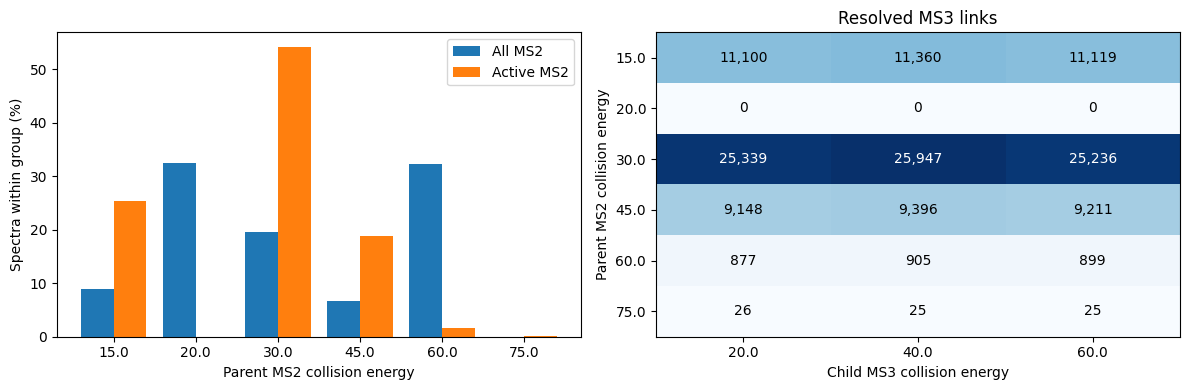

In [62]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4))
positions = np.arange(len(parent_energies))
for offset, counts, total, label in [(-0.2, ms2_energy_counts, len(ms2_spectra), "All MS2"),
                                     (0.2, active_energy_counts, len(active_ms2), "Active MS2")]:
    axes[0].bar(positions + offset, [report_percent(counts[energy], total) for energy in parent_energies], width=0.4, label=label)
axes[0].set(xticks=positions, xticklabels=[str(energy) for energy in parent_energies],
            xlabel="Parent MS2 collision energy", ylabel="Spectra within group (%)")
axes[0].legend()
if energy_cross_counts.size:
    heatmap = axes[1].imshow(energy_cross_counts, aspect="auto", cmap="Blues")
    for (row, column), count in np.ndenumerate(energy_cross_counts):
        axes[1].text(column, row, f"{count:,}", ha="center", va="center",
                     color="white" if count > energy_cross_counts.max() / 2 else "black")
    axes[1].set(xticks=np.arange(len(child_energies)), xticklabels=[str(e) for e in child_energies],
                yticks=positions, yticklabels=[str(e) for e in parent_energies],
                xlabel="Child MS3 collision energy", ylabel="Parent MS2 collision energy", title="Resolved MS3 links")
else:
    axes[1].text(0.5, 0.5, "No resolved MS3 links", ha="center")
    axes[1].axis("off")
figure.tight_layout()
save_report_plot("collision_energy_selection", "Parent energy distributions and counts of resolved MS3 links by parent and child energy")
plt.show()

In [63]:
block5_details[3] = "\n\n".join([
    "### Collision-energy selection",
    "Parent statistics count unique MS2 parents and linked (parent, peak index) pairs. "
    "Child statistics count individual resolved MS3 links, including repeated children of one peak; orphans are excluded. "
    "Energy is the stored collision_energy value, with no unit conversion or grouping-rounding; missing/nonfinite energy is Unknown. "
    "Intensity coverage pools raw intensities of valid active parents within each parent energy. "
    "These comparisons describe associations without establishing why particular energies were selected.",
    "#### Parent MS2 energy distributions", parent_energy_distribution_table,
    "#### Activity and coverage by parent MS2 energy", parent_energy_coverage_table,
    "#### MS2 energy choices within each feature forest", feature_energy_note,
    feature_energy_pattern_table, feature_energy_csv_link, feature_energy_details,
    "#### Child MS3 energy distribution", child_energy_distribution_table,
    "#### Parent MS2 energy × child MS3 energy (individual links)", energy_crosstab_table,
    report_images["collision_energy_selection"],
])

#### Peak-selection bias within active MS2 parents

Rank 1 is most intense; tied intensities share rank (`1 + number of more intense peaks`). Top-k includes all peaks with rank ≤ k, including ties. Percentages use the **actual number of eligible peaks**, including short spectra, rather than k times the number of parents.

For each rank, divide unique linked peaks at that rank by all peaks at that rank. Linked and unlinked relative intensities use each parent's maximum. These calculations use the same valid-intensity parents as above. Histogram groups are normalized separately for comparison; the complete rank table is saved as CSV.

In [64]:
selection_ranks, selection_linked, selection_relative_intensities = [], [], []

for (key, parent), valid in zip(active_ms2.items(), valid_active_intensity):
    if not valid:
        continue
    intensities = parent.intensity
    ranks = [1 + np.count_nonzero(intensities > value) for value in intensities]
    linked = np.zeros(len(parent.peaks), dtype=bool)
    linked[linked_indices_by_parent[key]] = True
    selection_ranks.extend(ranks)
    selection_linked.extend(linked)
    selection_relative_intensities.extend(100 * intensities / intensities.max())

selection_ranks = np.array(selection_ranks, dtype=int)
selection_linked = np.array(selection_linked, dtype=bool)
selection_relative_intensities = np.array(selection_relative_intensities)

In [65]:
import csv

rank_peak_counts = Counter(selection_ranks)
rank_linked_counts = Counter(selection_ranks[selection_linked])
rank_selection_rows = [
    [rank, total, rank_linked_counts[rank], report_percent(rank_linked_counts[rank], total)]
    for rank, total in sorted(rank_peak_counts.items())
]
rank_columns = ["Intensity rank", "Eligible peaks", "Linked peaks", "Link probability (%)"]
rank_selection_table = report_table(rank_columns, rank_selection_rows[:10])
display(Markdown("First 10 observed ranks:\n\n" + rank_selection_table))

rank_csv_path = report_image_dir / "ms2_peak_selection_by_rank.csv"
with rank_csv_path.open("w", newline="", encoding="utf-8") as file:
    writer = csv.writer(file)
    writer.writerow(rank_columns)
    writer.writerows(rank_selection_rows)

First 10 observed ranks:

| Intensity rank | Eligible peaks | Linked peaks | Link probability (%) |
| --- | --- | --- | --- |
| 1 | 10,850 | 8,949 | 82.48 |
| 2 | 10,850 | 8,047 | 74.17 |
| 3 | 10,807 | 7,075 | 65.47 |
| 4 | 10,715 | 6,524 | 60.89 |
| 5 | 10,569 | 6,131 | 58.01 |
| 6 | 10,363 | 4,338 | 41.86 |
| 7 | 10,141 | 2,304 | 22.72 |
| 8 | 9,911 | 1,410 | 14.23 |
| 9 | 9,651 | 864 | 8.95 |
| 10 | 9,327 | 614 | 6.58 |

In [66]:
top_rank_rows = []
for k in [1, 3, 5, 10]:
    eligible = selection_ranks <= k
    total = eligible.sum()
    linked = (eligible & selection_linked).sum()
    top_rank_rows.append(["Rank 1" if k == 1 else f"Top {k}", total, linked, report_percent(linked, total)])

top_rank_selection_table = report_table(["Peak group", "Eligible peaks", "Linked peaks", "Linked (%)"], top_rank_rows)
relative_selection_groups = {
    "Linked relative intensity (%)": selection_relative_intensities[selection_linked],
    "Unlinked relative intensity (%)": selection_relative_intensities[~selection_linked],
}
relative_selection_table = report_summary(relative_selection_groups)
display(Markdown(top_rank_selection_table + "\n\n" + relative_selection_table))

| Peak group | Eligible peaks | Linked peaks | Linked (%) |
| --- | --- | --- | --- |
| Rank 1 | 10,850 | 8,949 | 82.48 |
| Top 3 | 32,507 | 24,071 | 74.05 |
| Top 5 | 53,791 | 36,726 | 68.28 |
| Top 10 | 103,184 | 46,256 | 44.83 |

| Metric | N | Missing/nonfinite | Mean | Median | Q1 | Q3 | Min | Max |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Linked relative intensity (%) | 48,576 | 0 | 34.65 | 16.20 | 3.72 | 63.13 | 0.04 | 100.00 |
| Unlinked relative intensity (%) | 226,593 | 0 | 4.00 | 0.80 | 0.37 | 2.40 | 0.02 | 100.00 |

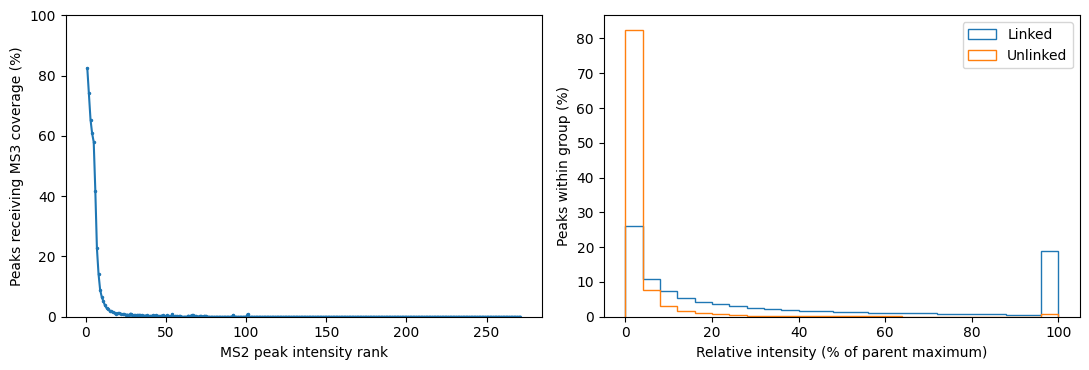

In [67]:
figure, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot([row[0] for row in rank_selection_rows], [row[3] for row in rank_selection_rows], ".-", markersize=3)
axes[0].set(xlabel="MS2 peak intensity rank", ylabel="Peaks receiving MS3 coverage (%)", ylim=(0, 100))
for label, values in relative_selection_groups.items():
    if len(values):
        axes[1].hist(values, bins=np.linspace(0, 100, 26), weights=np.full(len(values), 100 / len(values)),
                     histtype="step", label=label.split()[0])
axes[1].set(xlabel="Relative intensity (% of parent maximum)", ylabel="Peaks within group (%)")
if len(selection_relative_intensities):
    axes[1].legend()
figure.tight_layout()
save_report_plot("ms2_peak_selection_bias", "MS3 link probability by intensity rank and linked versus unlinked relative intensities")
plt.show()

block5_details[4] = "\n\n".join([
    "### Peak-selection bias within active MS2 parents",
    f"Uses {valid_active_intensity.sum():,} valid-intensity active parents; {(~valid_active_intensity).sum():,} excluded. "
    "Probability at a rank is linked peaks / all peaks at that rank. Rank 1 is most intense, ties share rank, "
    "and top-k includes every peak with rank <= k. Denominators count actual eligible peaks, including short spectra and ties.",
    "First 10 observed ranks:", rank_selection_table,
    f"[Complete rank table (CSV)]({rank_csv_path.relative_to(report_dir).as_posix()}). Tail ranks can have few eligible peaks; counts are included.",
    top_rank_selection_table, relative_selection_table,
    "Each linked or unlinked peak contributes once; relative intensity uses its parent's maximum. Histogram groups are normalized separately.",
    report_images["ms2_peak_selection_bias"],
])

#### Molecule-level supervision coverage

Use all identified molecules from Block 2, including molecules with zero linked peaks or active MS2 parents. Identify molecules by InChIKey, falling back to SMILES. Linked peaks remain distinct across different parent spectra; repeated MS3 children of one peak are counted once.

In [68]:
molecule_linked_peaks = Counter({molecule: 0 for molecule in molecule_count})
molecule_active_parents = Counter({molecule: 0 for molecule in molecule_count})
unidentified_active_parents = 0
unidentified_linked_peaks = 0

for key, parent in active_ms2.items():
    molecule = (parent.metadata.get("inchikey") or "").strip()
    molecule = molecule or (parent.smiles or "").strip()
    linked = len(linked_indices_by_parent[key])
    if molecule:
        molecule_linked_peaks[molecule] += linked
        molecule_active_parents[molecule] += 1
    else:
        unidentified_active_parents += 1
        unidentified_linked_peaks += linked

linked_peaks_per_molecule = np.array(list(molecule_linked_peaks.values()), dtype=int)
active_parents_per_molecule = np.array(list(molecule_active_parents.values()), dtype=int)

In [69]:
molecule_supervision_table = report_summary({
    "Unique linked MS2 peaks per molecule": linked_peaks_per_molecule,
    "Active MS2 parents per molecule": active_parents_per_molecule,
})
molecule_threshold_rows = [
    [minimum, np.count_nonzero(linked_peaks_per_molecule >= minimum),
     report_percent(np.count_nonzero(linked_peaks_per_molecule >= minimum), len(molecule_count))]
    for minimum in [1, 5, 10]
]
molecule_threshold_table = report_table(["At least N linked peaks", "Molecules", "% of all identified molecules"], molecule_threshold_rows)
display(Markdown(molecule_supervision_table + "\n\n" + molecule_threshold_table))
print(f"Excluded for missing molecule ID: {unidentified_active_parents:,} active parents, {unidentified_linked_peaks:,} linked peaks")

| Metric | N | Missing/nonfinite | Mean | Median | Q1 | Q3 | Min | Max |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Unique linked MS2 peaks per molecule | 9,544 | 0 | 5.09 | 5.00 | 5.00 | 5.00 | 0.00 | 20.00 |
| Active MS2 parents per molecule | 9,544 | 0 | 1.14 | 1.00 | 1.00 | 1.00 | 0.00 | 5.00 |

| At least N linked peaks | Molecules | % of all identified molecules |
| --- | --- | --- |
| 1 | 9,408 | 98.58 |
| 5 | 7,698 | 80.66 |
| 10 | 295 | 3.09 |

Excluded for missing molecule ID: 0 active parents, 0 linked peaks


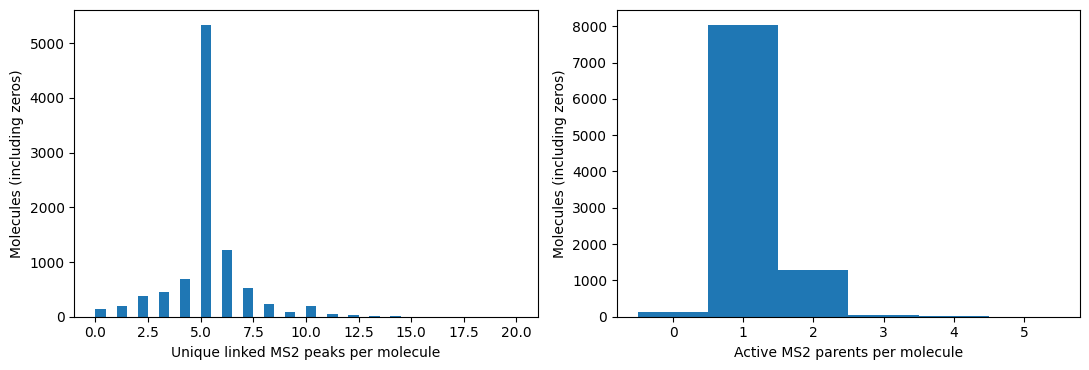

In [70]:
figure, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(linked_peaks_per_molecule, bins=40)
axes[0].set(xlabel="Unique linked MS2 peaks per molecule", ylabel="Molecules (including zeros)")
axes[1].hist(active_parents_per_molecule, bins=np.arange(max(active_parents_per_molecule, default=0) + 2) - 0.5)
axes[1].set(xlabel="Active MS2 parents per molecule", ylabel="Molecules (including zeros)")
figure.tight_layout()
save_report_plot("molecule_supervision_coverage", "Distributions of linked MS2 peaks and active MS2 parents across all identified molecules")
plt.show()

block5_details[5] = "\n\n".join([
    "### Molecule-level supervision coverage",
    f"Denominator: all {len(molecule_count):,} identified molecules from Block 2, including zeros. "
    "Identity uses InChIKey, falling back to SMILES. Linked peaks remain distinct across different MS2 parents; "
    "repeated MS3 children of the same parent peak count once.",
    molecule_supervision_table, molecule_threshold_table,
    f"Excluded for missing molecule ID: {unidentified_active_parents:,} active parents and {unidentified_linked_peaks:,} linked peaks.",
    report_images["molecule_supervision_coverage"],
])

In [71]:
report_sections[5] = "\n\n".join([
    "## Block 5 — MS2 → MS3 coverage",
    f"Use each MS3 spectrum's parsed MS2 parent and match the last `msn_precursor_mzs` value "
    f"to the nearest parent peak within {mz_tolerance:g} Da. Each (parent, peak index) counts once toward coverage.",
    f"**MS3 spectra matched to an MS2 peak: {len(ms3_links):,}.**",
    report_table(["Coverage measure", "Numerator", "Denominator", "Coverage (%)"], [
        ["MS2 spectra with at least one MS3 child", ms2_with_children, len(ms2_spectra), ms2_child_percentage],
        ["Global MS2 peak coverage", len(linked_peak_children), all_ms2_peak_count, 100 * global_peak_coverage],
        ["Peak coverage among MS2 spectra with MS3 children", len(linked_peak_children), peaks_in_ms2_with_children, 100 * peak_coverage_with_children],
    ]),
    "Global coverage uses all loaded MS2 peaks. Coverage among MS2 spectra with MS3 children uses "
    "only the peaks in MS2 spectra with at least one resolved MS3 child as its denominator; "
    "each linked peak still counts once. This is a pooled peak ratio within that subset. "
    "Per-spectrum coverage gives each nonempty MS2 spectrum "
    "equal weight, including zero coverage for spectra without links. Empty MS2 spectra have undefined coverage.",
    report_summary({"Per-spectrum MS2 peak coverage (%)": 100 * ms2_peak_coverage}),
    f"**Empty MS2 spectra (undefined coverage): {np.count_nonzero(np.isnan(ms2_peak_coverage)):,}.**",
    report_summary({"MS3 children per unique linked MS2 peak": list(linked_peak_children.values()),
                    "Linked MS2 peak intensity rank": linked_peak_ranks,
                    "Linked MS2 peak relative intensity (%)": linked_peak_relative_intensities}),
    "Intensity statistics count each linked MS2 peak once. Rank 1 is most intense, ties share rank, "
    "and relative intensity uses that parent's maximum. Undefined values are excluded and counted above.",
    "### Parent-link mass errors",
    "Each MS3 link contributes once. Signed error = matched MS2 peak m/z − isolated fragment m/z; 1 mDa = 0.001 Da.",
    report_summary({"Signed parent-link mass error (mDa)": 1000 * mass_errors_da}, decimals=6),
    report_images["linked_peak_distributions"],
])

report_sections[5] += "\n\n" + "\n\n".join(block5_details[number] for number in range(1, 6))


### Block 6 — Quality statistics

Numeric summaries exclude missing/nonfinite values and report their counts. For MS³+, a missing `isolation_window` falls back to the last `msn_isolation_windows` entry, describing the current fragmentation step. Collision energies use the stored values and units.

In [72]:
def quality_value(spectrum, field):
    value = spectrum.metadata.get(field)
    if field == "isolation_window" and value is None:
        windows = spectrum.metadata.get("msn_isolation_windows") or []
        value = windows[-1] if windows else None
    return float(value) if value is not None else np.nan

In [73]:
quality_fields = [
    "precursor_purity", "quality_explained_signals", "quality_explained_intensity",
    "collision_energy", "isolation_window",
]
quality_by_ms_level = {}
spectra_by_ms_level = {}

for ms_level in sorted(ms_level_count):
    group = [spectrum for spectrum in spectra if spectrum.ms_level == ms_level]
    spectra_by_ms_level[ms_level] = group
    quality_by_ms_level[ms_level] = {
        field: np.array([quality_value(spectrum, field) for spectrum in group])
        for field in quality_fields
    }

In [74]:
for ms_level, fields in quality_by_ms_level.items():
    print(f"\nMS{ms_level}")
    for field, values in fields.items():
        valid = np.isfinite(values)
        print(f"\n{field}: {valid.sum():,} observed; {(~valid).sum():,} missing/nonfinite")
        print_summary(values[valid])


MS2

precursor_purity: 31,463 observed; 0 missing/nonfinite
Mean: 0.97
Median: 0.98
Q1 (25%): 0.97
Q3 (75%): 0.99
Minimum: 0.03
Maximum: 1.00

quality_explained_signals: 31,440 observed; 23 missing/nonfinite
Mean: 0.81
Median: 0.86
Q1 (25%): 0.72
Q3 (75%): 0.94
Minimum: 0.07
Maximum: 1.00

quality_explained_intensity: 31,440 observed; 23 missing/nonfinite
Mean: 0.96
Median: 0.99
Q1 (25%): 0.97
Q3 (75%): 1.00
Minimum: 0.01
Maximum: 1.00

collision_energy: 31,463 observed; 0 missing/nonfinite
Mean: 36.11
Median: 30.00
Q1 (25%): 20.00
Q3 (75%): 60.00
Minimum: 15.00
Maximum: 75.00

isolation_window: 31,463 observed; 0 missing/nonfinite
Mean: 1.20
Median: 1.20
Q1 (25%): 1.20
Q3 (75%): 1.20
Minimum: 1.20
Maximum: 1.20

MS3

precursor_purity: 152,514 observed; 0 missing/nonfinite
Mean: 0.96
Median: 0.98
Q1 (25%): 0.96
Q3 (75%): 0.99
Minimum: 0.03
Maximum: 1.00

quality_explained_signals: 149,669 observed; 2,845 missing/nonfinite
Mean: 0.92
Median: 1.00
Q1 (25%): 0.90
Q3 (75%): 1.00
Minimum: 

In [75]:
print(f"{'MS level':<10} {'CHIMERIC':>10} {'% of level':>12} {'Unknown':>10}")
for ms_level, group in spectra_by_ms_level.items():
    statuses = Counter(spectrum.metadata.get("quality_chimeric") for spectrum in group)
    chimeric = statuses["CHIMERIC"]
    unknown = len(group) - chimeric - statuses["PASSED"]
    percentage = 100 * chimeric / len(group)
    print(f"MS{ms_level:<8} {chimeric:>10,} {percentage:>11.2f}% {unknown:>10,}")

MS level     CHIMERIC   % of level    Unknown
MS2               448        1.42%          0
MS3             3,070        2.01%         14
MS4             1,882        1.23%          9
MS5                56        0.64%          2


#### Collision-energy and isolation-window frequencies

Values are rounded to three decimals **only for these frequency tables**, to combine floating-point representations of the same setting. Percentages use all spectra within each MS level.

In [76]:
for field in ["collision_energy", "isolation_window"]:
    print(f"\n{field}")
    print(f"{'MS level':<10} {'Value':>10} {'Spectra':>10} {'% of level':>12}")
    for ms_level, fields in quality_by_ms_level.items():
        values = fields[field]
        counts = Counter(np.round(values[np.isfinite(values)], 3))
        for value, count in sorted(counts.items()):
            percentage = 100 * count / len(values)
            print(f"MS{ms_level:<8} {value:>10.3f} {count:>10,} {percentage:>11.2f}%")


collision_energy
MS level        Value    Spectra   % of level
MS2            15.000      2,813        8.94%
MS2            20.000     10,208       32.44%
MS2            30.000      6,173       19.62%
MS2            45.000      2,109        6.70%
MS2            60.000     10,154       32.27%
MS2            75.000          6        0.02%
MS3            20.000     50,237       32.94%
MS3            40.000     51,717       33.91%
MS3            60.000     50,560       33.15%
MS4            20.000     51,194       33.35%
MS4            40.000     53,909       35.12%
MS4            60.000     48,405       31.53%
MS5            40.000      4,532       51.72%
MS5            60.000      4,231       48.28%

isolation_window
MS level        Value    Spectra   % of level
MS2             1.200     31,463      100.00%
MS3             2.000    152,514      100.00%
MS4             2.200    153,508      100.00%
MS5             3.000      8,763      100.00%


In [77]:
chimeric_rows = []
for level, group in spectra_by_ms_level.items():
    statuses = Counter(spectrum.metadata.get("quality_chimeric") for spectrum in group)
    unknown = len(group) - statuses["CHIMERIC"] - statuses["PASSED"]
    chimeric_rows.append([f"MS{level}", statuses["CHIMERIC"], report_percent(statuses["CHIMERIC"], len(group)), unknown])

quality_report = [
    "## Block 6 — Quality statistics",
    "Numeric summaries exclude missing/nonfinite values and report their counts. "
    "Missing `isolation_window` values use the last `msn_isolation_windows` entry for the current step. "
    "Collision energies are shown as stored, without a unit conversion.",
    report_summary({f"MS{level} — {field}": values
                    for level, fields in quality_by_ms_level.items() for field, values in fields.items()}),
    "### Chimeric spectra",
    "Percentages use all spectra within each MS level. Unknown means neither PASSED nor CHIMERIC.",
    report_table(["MS level", "CHIMERIC spectra", "% of level", "Unknown status"], chimeric_rows),
    "### Collision-energy and isolation-window frequencies",
    "Only these frequency tables round values to three decimals to combine floating-point representations "
    "of the same setting. Percentages use all spectra within each level.",
]
for field in ["collision_energy", "isolation_window"]:
    rows = []
    for level, fields in quality_by_ms_level.items():
        values = fields[field]
        counts = Counter(np.round(values[np.isfinite(values)], 3))
        rows.extend([f"MS{level}", value, count, report_percent(count, len(values))]
                    for value, count in sorted(counts.items()))
    quality_report += [f"#### {field}", report_table(["MS level", "Value", "Spectra", "% of level"], rows, decimals=3)]

report_sections[6] = "\n\n".join(quality_report)

### Block 7 — Research-ready subset

The starting cohort is **all loaded MS³ spectra**. Each retained spectrum is an MS³ target paired with its MS² parent; parents are not counted again. Percentages always use the starting MS³ count. Filters are cumulative.

A valid molecule identifier means a nonblank InChIKey or SMILES, using the same priority as Block 2. Valid peaks are nonempty, finite, have positive m/z, nonnegative intensities, and at least one positive intensity. The link filter also requires a valid molecule identifier and valid peaks on the MS² parent. Non-chimeric means `quality_chimeric == "PASSED"`, and both parent and child must pass the chimeric and purity filters.

The proposed purity cutoff is editable below. MAGMa annotation stays **pending** until successful MS³ annotation keys are supplied; the current output is a candidate subset.

In [78]:
min_precursor_purity = 0.90
magma_success_keys = None  # Later: a set of (feature_id, MS3 USI) keys from successful annotations.

In [79]:
def molecule_identifier(spectrum):
    inchikey = (spectrum.metadata.get("inchikey") or "").strip()
    return inchikey or (spectrum.smiles or "").strip()


def valid_peaks(spectrum):
    return (
        len(spectrum.peaks) > 0
        and np.isfinite(spectrum.peaks).all()
        and np.all(spectrum.mz > 0)
        and np.all(spectrum.intensity >= 0)
        and np.any(spectrum.intensity > 0)
    )

In [80]:
candidate_subset = [spectrum for spectrum in spectra if spectrum.ms_level == 3]
starting_count = len(candidate_subset)
attrition = []


def record_attrition(label, subset):
    molecules = {molecule_identifier(spectrum) for spectrum in subset} - {""}
    retained = 100 * len(subset) / starting_count if starting_count else np.nan
    attrition.append((label, len(subset), len(molecules), retained))


record_attrition("Starting MS3 spectra", candidate_subset)

In [81]:
candidate_subset = [spectrum for spectrum in candidate_subset if molecule_identifier(spectrum)]
record_attrition("Valid molecule identifier", candidate_subset)

In [82]:
candidate_subset = [spectrum for spectrum in candidate_subset if valid_peaks(spectrum)]
record_attrition("Valid peaks", candidate_subset)

In [83]:
valid_ms2_keys = {
    spectrum_key(spectrum) for spectrum in ms2_spectra
    if molecule_identifier(spectrum) and valid_peaks(spectrum)
}
candidate_subset = [
    spectrum for spectrum in candidate_subset
    if spectrum_key(spectrum) in ms3_links
    and ms3_links[spectrum_key(spectrum)]["parent"] in valid_ms2_keys
]
record_attrition("Resolved link + valid MS2 parent", candidate_subset)

In [84]:
def ms2_parent(spectrum):
    return forest_spectra[ms3_links[spectrum_key(spectrum)]["parent"]]


candidate_subset = [
    spectrum for spectrum in candidate_subset
    if all(member.metadata.get("quality_chimeric") == "PASSED"
           for member in [spectrum, ms2_parent(spectrum)])
]
record_attrition("Non-chimeric parent and child", candidate_subset)

In [85]:
candidate_subset = [
    spectrum for spectrum in candidate_subset
    if all(min_precursor_purity <= quality_value(member, "precursor_purity") <= 1
           for member in [spectrum, ms2_parent(spectrum)])
]
record_attrition(f"Parent and child purity >= {min_precursor_purity:.2f}", candidate_subset)

In [86]:
if magma_success_keys is None:
    attrition.append(("MAGMa annotation (pending)", None, None, None))
else:
    candidate_subset = [
        spectrum for spectrum in candidate_subset
        if spectrum_key(spectrum) in magma_success_keys
    ]
    record_attrition("Successful MAGMa annotation", candidate_subset)

In [87]:
print(f"{'Filter':<38} | {'Spectra remaining':>17} | {'Molecules remaining':>19} | {'% retained':>10}")
for label, count, molecules, retained in attrition:
    if count is None:
        print(f"{label:<38} | {'—':>17} | {'—':>19} | {'—':>10}")
    else:
        print(f"{label:<38} | {count:>17,} | {molecules:>19,} | {retained:>9.2f}%")

Filter                                 | Spectra remaining | Molecules remaining | % retained
Starting MS3 spectra                   |           152,514 |               9,525 |    100.00%
Valid molecule identifier              |           152,514 |               9,525 |    100.00%
Valid peaks                            |           152,514 |               9,525 |    100.00%
Resolved link + valid MS2 parent       |           141,752 |               9,452 |     92.94%
Non-chimeric parent and child          |           139,070 |               9,378 |     91.19%
Parent and child purity >= 0.90        |           130,879 |               9,066 |     85.81%
MAGMa annotation (pending)             |                 — |                   — |          —


In [88]:
research_pairs = [
    {"ms2": ms2_parent(spectrum), "ms3": spectrum,
     "peak_index": ms3_links[spectrum_key(spectrum)]["peak_index"]}
    for spectrum in candidate_subset
]

print(f"MS2–MS3 pairs retained: {len(research_pairs):,}")
print("MAGMa annotation:", "pending" if magma_success_keys is None else "filter applied")

MS2–MS3 pairs retained: 130,879
MAGMa annotation: pending


In [89]:
report_sections[7] = "\n\n".join([
    "## Block 7 — Research-ready subset",
    "The starting cohort is all loaded MS3 spectra. Each retained spectrum is an MS3 target paired "
    "with its MS2 parent; parents are not counted again. Filters are cumulative, and retention percentages use the starting MS3 count.",
    "Valid identifiers are nonblank InChIKey or SMILES (no chemical validation). Valid peaks are nonempty and finite, "
    "with positive m/z, nonnegative intensities, and at least one positive intensity. "
    "The link filter also requires valid peaks and an identifier on the MS2 parent.",
    f"Both parent and child must have `quality_chimeric == PASSED` and precursor purity >= {min_precursor_purity:.2f} "
    "(editable proposed cutoff; purity values above 1 are excluded). Missing quality does not pass these filters.",
    report_table(["Filter", "Spectra remaining", "Molecules remaining", "Percentage retained (%)"], attrition),
    f"**MS2–MS3 pairs retained: {len(research_pairs):,}.**",
    "MAGMa annotation is pending; counts for that step are unavailable and the retained pairs are a candidate subset."
    if magma_success_keys is None else "The MAGMa filter retains MS3 targets whose keys are in `magma_success_keys`.",
])

if set(report_sections) != set(range(1, 8)):
    raise ValueError("Run the final report cell in every block before exporting.")

report_header = (
    f"# MSnLib statistics report\n\n"
    f"Generated (UTC): {datetime.now(timezone.utc):%Y-%m-%d %H:%M:%S}\n\n"
    f"Dataset: `{data_path.name}`. Selection: `merge_type == SINGLE_BEST_SCAN`.\n\n"
    "Source notebook: [Explore_dataset.ipynb](Explore_dataset.ipynb).\n\n"
    "Statistics describe stored spectra after this selection. In summary tables, N counts finite observations; "
    "missing/nonfinite values are excluded. Q1 and Q3 use NumPy's default linear quantiles. A dash means unavailable or undefined."
)
report_text = report_header + "\n\n" + "\n\n".join(report_sections[number] for number in range(1, 8)) + "\n"
report_path.write_text(report_text, encoding="utf-8")
print(f"Report saved: {report_path}")

Report saved: /Users/islam/Desktop/MS_Pred_Research/MAGMA_Research/MSnLib_stats_report.md
